# Clarification Deficit for MAST 2.2 on AG2 with `Claude`

MAST 2.2 (fail to ask for clarification) is operationalised as a Clarification Deficit:
the share of agent events that voice uncertainty (hedges, missing information phrases)
without a clarification question following within one event. Nine `cd_*` features are
computed per trace; `cd_deficit` is the headline. The notebook contrasts the features
with the per run 2.2 label (Mann Whitney U with rank AUC), stratifies by benchmark to
catch direction flips, checks the correlation structure of the feature family, and
draws the ROC curves. The corpus is the AG2 subset run with `Claude`.

## 0. Pipeline Code

This notebook is self contained: the pipeline code is inlined below, one cell per
module, in dependency order. Nothing is imported from the project, so the notebook runs
wherever the scientific stack of `requirements.txt` and the `data/` folder are
available.

Read this section once and skip it afterwards; the analysis starts at Section 1. Each
block ends by binding its own name (`loading`, `statistics`, ...) so the analysis cells
address the code exactly as they did when it was a package. The blocks are generated
from one source by `tools/build_notebooks.py`, so all sixteen notebooks carry identical
pipeline code.

`PROJECT_ROOT` is the directory holding `data/` and `notebooks/`.

In [1]:
from __future__ import annotations

import ast
import json
import logging
import math
import os
import platform
import random
import re
import statistics as _stdlib_statistics
import sys
import types
import warnings
from collections import Counter, defaultdict
from dataclasses import asdict, dataclass, field
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Callable, Dict, Iterable, List, Optional, Sequence, Set, Tuple, Union

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


class _Namespace(types.SimpleNamespace):
    """Attribute access for one block of the inlined pipeline.

    The analysis cells call the pipeline the way they always have -- ``loading.load_corpus``,
    ``statistics.contrast_table`` -- so each block below ends by binding its own name to one
    of these. It is a plain container, not a module: nothing is registered in ``sys.modules``,
    so the ``statistics`` block does not shadow the standard library module of the same name.
    """


PROJECT_ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "data").is_dir() and (p / "notebooks").is_dir()
)

### 0.environment

deterministic setup: seeds, paths, logging, plotting and the figure palette


Section 1 of every notebook: deterministic environment setup.

:func:`setup_environment` seeds every random number generator the pipeline touches,
configures logging and plotting defaults, resolves the project directories and returns
an :class:`Environment` handle that the other modules take as their first argument.

In [2]:
import logging
import os
import platform
import random
import sys
import warnings
from dataclasses import dataclass, field
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Dict, Optional

import numpy as np
import pandas as pd

DEFAULT_SEED = 42

#: Colour blind safe categorical palette used by every figure of the pipeline.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
C_NEG, C_POS, C_ACC = "#3a7abf", "#d45050", "#4c9a5e"
SIGNAL_COLOURS = {"Activity": "#4C72B0", "Influence": "#DD8452", "Mimicry": "#55A868",
                  "Consistency": "#8172B3"}


@dataclass
class Environment:
    """Resolved paths and reproducibility settings of one notebook run."""

    project_root: Path
    notebook_name: str
    seed: int
    data_dir: Path
    cache_dir: Path
    results_dir: Path
    figure_dir: Path
    judge_cache_dir: Path
    sealed_dir: Path
    started_at: str
    versions: Dict[str, str] = field(default_factory=dict)
    logger: logging.Logger = field(default_factory=lambda: logging.getLogger("mad"))

    def describe(self) -> pd.DataFrame:
        """One row table of the run settings, printed in Section 1 of each notebook."""
        rows = {
            "notebook": self.notebook_name,
            "project_root": str(self.project_root),
            "data_dir": str(self.data_dir),
            "results_dir": str(self.results_dir),
            "seed": self.seed,
            "started_at": self.started_at,
            "python": self.versions.get("python", ""),
            "numpy": self.versions.get("numpy", ""),
            "pandas": self.versions.get("pandas", ""),
        }
        return pd.DataFrame({"setting": list(rows), "value": [str(v) for v in rows.values()]})

    def data_path(self, name: str) -> Path:
        """Resolve a data file: ``data/<name>`` first, then ``$MAD_DATA_DIR/<name>``."""
        candidate = self.data_dir / name
        if candidate.exists():
            return candidate
        override = os.environ.get("MAD_DATA_DIR")
        if override and (Path(override) / name).exists():
            return Path(override) / name
        return candidate


def find_project_root(start: Optional[Path] = None) -> Path:
    """Walk upwards from ``start`` until the project root is found.

    The root is the directory that holds both ``data`` and ``notebooks``. Neither marker is
    sufficient on its own, and requiring both keeps the search from stopping at an unrelated
    ``data`` folder somewhere above the project.
    """
    here = (start or Path.cwd()).resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("project root (a directory with data/ and notebooks/) not found above " + str(here))


def seed_everything(seed: int = DEFAULT_SEED) -> None:
    """Seed ``random``, ``numpy`` and, when present, ``torch``."""
    random.seed(seed)
    np.random.seed(seed)
    os.environ.setdefault("PYTHONHASHSEED", str(seed))
    try:  # pragma: no cover - optional dependency
        import torch  # type: ignore

        torch.manual_seed(seed)
    except Exception:
        pass


def configure_logging(level: str = "INFO") -> logging.Logger:
    """Compact stdout logging shared by all modules."""
    logger = logging.getLogger("mad")
    logger.setLevel(getattr(logging, level.upper(), logging.INFO))
    logger.propagate = False
    if not logger.handlers:
        handler = logging.StreamHandler(sys.stdout)
        handler.setFormatter(logging.Formatter("%(asctime)s %(levelname)s %(message)s", "%H:%M:%S"))
        logger.addHandler(handler)
    return logger


def configure_plotting() -> None:
    """Matplotlib and seaborn defaults so every figure of every notebook looks alike."""
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    import seaborn as sns

    sns.set_theme(style="whitegrid")
    mpl.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "text.color": INK,
        "xtick.color": INK2, "ytick.color": INK2, "grid.color": GRID, "grid.linewidth": 0.6,
        "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.spines.top": False,
        "axes.spines.right": False, "font.size": 10, "figure.dpi": 110, "savefig.dpi": 140,
        "savefig.bbox": "tight", "axes.prop_cycle": plt.cycler(color=PALETTE),
    })


def configure_pandas() -> None:
    pd.set_option("display.width", 180)
    pd.set_option("display.max_columns", 40)
    pd.set_option("display.precision", 4)


def setup_environment(project_root: Path, notebook_name: str, seed: int = DEFAULT_SEED,
                      log_level: str = "INFO") -> Environment:
    """Create the deterministic environment of a notebook run.

    Parameters
    ----------
    project_root:
        Directory that contains the ``data`` and ``notebooks`` folders.
    notebook_name:
        Stem of the notebook; results are written to ``results/<notebook_name>/``.
    seed:
        Seed for every random number generator used by the pipeline.
    """
    project_root = Path(project_root).resolve()
    seed_everything(seed)
    logger = configure_logging(log_level)
    configure_plotting()
    configure_pandas()
    warnings.filterwarnings("ignore", category=FutureWarning)
    warnings.filterwarnings("ignore", category=UserWarning, module="statsmodels")

    data_dir = project_root / "data"
    env = Environment(
        project_root=project_root,
        notebook_name=notebook_name,
        seed=seed,
        data_dir=data_dir,
        cache_dir=data_dir / "cache",
        results_dir=project_root / "results" / notebook_name,
        figure_dir=project_root / "results" / notebook_name / "figures",
        judge_cache_dir=data_dir / "judge_cache",
        sealed_dir=data_dir / "sealed",
        started_at=datetime.now(timezone.utc).isoformat(timespec="seconds"),
        versions={"python": platform.python_version(), "numpy": np.__version__,
                  "pandas": pd.__version__},
        logger=logger,
    )
    for path in (env.cache_dir, env.results_dir, env.figure_dir, env.judge_cache_dir, env.sealed_dir):
        path.mkdir(parents=True, exist_ok=True)
    logger.info("environment ready: notebook=%s seed=%d root=%s", notebook_name, seed, project_root)
    return env


def library_versions() -> Dict[str, Any]:
    """Versions of the scientific stack, recorded in the export manifest."""
    out: Dict[str, Any] = {"python": platform.python_version()}
    for name in ("numpy", "pandas", "scipy", "sklearn", "statsmodels", "networkx", "matplotlib",
                 "seaborn"):
        try:
            module = __import__(name)
            out[name] = getattr(module, "__version__", "?")
        except Exception:
            out[name] = None
    return out

environment = _Namespace(**{
    "logging": logging,
    "os": os,
    "platform": platform,
    "random": random,
    "sys": sys,
    "warnings": warnings,
    "dataclass": dataclass,
    "field": field,
    "datetime": datetime,
    "timezone": timezone,
    "Path": Path,
    "Any": Any,
    "Dict": Dict,
    "Optional": Optional,
    "np": np,
    "pd": pd,
    "DEFAULT_SEED": DEFAULT_SEED,
    "PALETTE": PALETTE,
    "INK": INK,
    "INK2": INK2,
    "MUTED": MUTED,
    "GRID": GRID,
    "SURFACE": SURFACE,
    "C_NEG": C_NEG,
    "C_POS": C_POS,
    "C_ACC": C_ACC,
    "SIGNAL_COLOURS": SIGNAL_COLOURS,
    "Environment": Environment,
    "find_project_root": find_project_root,
    "seed_everything": seed_everything,
    "configure_logging": configure_logging,
    "configure_plotting": configure_plotting,
    "configure_pandas": configure_pandas,
    "setup_environment": setup_environment,
    "library_versions": library_versions,
})

### 0.schema

the canonical trace schema (`Event`, `TraceRecord`) every metric reads


Canonical trace schema shared by every notebook of the pipeline.

Every loader in the ``loading`` block converts its input (raw MAD JSON,
a cleaned corpus file, or a stratified split file) into a list of
:class:`TraceRecord` objects. Every metric module reads only this schema, so
a metric never has to know which log dialect a trace came from.

Event kinds
-----------
``agent_message``  a turn spoken by an agent (prose)
``code``           a turn spoken by an agent that carries a code artefact
``system``         scaffolding: prompts, phase headers, task statements
``tool``           environment output: execution results, tool returns
``log``            framework telemetry lines
``section``        structural separators without content

The agent turn gate used throughout the thesis is ``kind in AGENT_KINDS`` and
``actor is not None``.

In [3]:
import math
import re
from dataclasses import asdict, dataclass, field
from typing import Any, Dict, Iterable, List, Optional, Sequence

MAST_CODES: List[str] = [
    "1.1", "1.2", "1.3", "1.4", "1.5",
    "2.1", "2.2", "2.3", "2.4", "2.5", "2.6",
    "3.1", "3.2", "3.3",
]

MAST_LABELS: Dict[str, str] = {
    "1.1": "Disobey task specification",
    "1.2": "Disobey role specification",
    "1.3": "Step repetition",
    "1.4": "Loss of conversation history",
    "1.5": "Unaware of termination conditions",
    "2.1": "Conversation reset",
    "2.2": "Fail to ask for clarification",
    "2.3": "Task derailment",
    "2.4": "Information withholding",
    "2.5": "Ignored other agent's input",
    "2.6": "Reasoning action mismatch",
    "3.1": "Premature termination",
    "3.2": "No or incomplete verification",
    "3.3": "Incorrect verification",
}

MAST_GROUPS: Dict[str, List[str]] = {
    "FC1 system design": ["1.1", "1.2", "1.3", "1.4", "1.5"],
    "FC2 inter agent misalignment": ["2.1", "2.2", "2.3", "2.4", "2.5", "2.6"],
    "FC3 task verification": ["3.1", "3.2", "3.3"],
}

AGENT_KINDS = frozenset({"agent_message", "code"})
EVENT_KINDS = ("agent_message", "code", "system", "tool", "log", "section")

#: Pre registered framework split (thesis Table 1).
DISCOVERY_FRAMEWORKS = ("ChatDev", "AG2")
TEST_FRAMEWORKS = ("MetaGPT", "Magentic")
EXCLUDED_FRAMEWORKS = ("AppWorld", "HyperAgent", "OpenManus")

_SCHEMA_WORD_RE = re.compile(r"\w+")
_FENCE_RE = re.compile(r"```.*?```", re.DOTALL)


def count_tokens(text: str) -> int:
    """Count whitespace delimited word tokens (the unit of every length metric)."""
    if not text:
        return 0
    return len(_SCHEMA_WORD_RE.findall(text))


def strip_code_fences(text: str) -> str:
    """Remove fenced code blocks so prose detectors do not read source code."""
    return _FENCE_RE.sub(" ", text or "")


def label_column(code: str) -> str:
    """Column name used for a MAST code in every DataFrame (``2.2`` becomes ``code_2_2``)."""
    return "code_" + code.replace(".", "_")


@dataclass
class Event:
    """One logged event of a trajectory in the canonical schema."""

    seq: int
    kind: str
    actor: Optional[str]
    content: str
    n_tokens: int = 0
    timestamp: Optional[str] = None
    level: Optional[str] = None
    label: Optional[str] = None

    def __post_init__(self) -> None:
        if self.kind not in EVENT_KINDS:
            raise ValueError(f"unknown event kind {self.kind!r}")
        if not self.n_tokens:
            self.n_tokens = count_tokens(self.content)

    @property
    def is_agent_turn(self) -> bool:
        return self.kind in AGENT_KINDS and self.actor is not None

    def to_dict(self) -> Dict[str, Any]:
        return asdict(self)

    @classmethod
    def from_dict(cls, payload: Dict[str, Any]) -> "Event":
        return cls(
            seq=int(payload["seq"]),
            kind=str(payload["kind"]),
            actor=payload.get("actor"),
            content=str(payload.get("content") or ""),
            n_tokens=int(payload.get("n_tokens") or 0),
            timestamp=payload.get("timestamp"),
            level=payload.get("level"),
            label=payload.get("label"),
        )


@dataclass
class TraceRecord:
    """One multi agent execution trace in the canonical schema."""

    trace_uid: str
    mas_name: str
    llm_name: str
    benchmark_name: str
    trace_id: int
    trace_key: str
    trace_index: int
    trajectory_format: str
    task_text: Optional[str]
    ground_truth_correct: Optional[bool]
    mast_annotation: Dict[str, Optional[int]]
    events: List[Event] = field(default_factory=list)
    coverage: Dict[str, Any] = field(default_factory=dict)

    # ------------------------------------------------------------------ views
    def agent_turns(self) -> List[Event]:
        """Signal bearing agent turns in sequence order."""
        return [e for e in self.events if e.is_agent_turn]

    def actors(self) -> List[str]:
        """Distinct agent actors in order of first appearance."""
        seen: List[str] = []
        for e in self.agent_turns():
            if e.actor not in seen:
                seen.append(e.actor)  # type: ignore[arg-type]
        return seen

    def is_labelled(self) -> bool:
        """True when all fourteen MAST codes carry a 0/1 value."""
        return all(self.mast_annotation.get(c) is not None for c in MAST_CODES)

    def failure_burden(self) -> float:
        """Number of MAST codes tagged on the trace; NaN when unlabelled."""
        if not self.is_labelled():
            return math.nan
        return float(sum(int(self.mast_annotation[c]) for c in MAST_CODES))

    def label(self, code: str) -> Optional[int]:
        value = self.mast_annotation.get(code)
        return None if value is None else int(value)

    @property
    def framework_llm(self) -> str:
        return f"{self.mas_name}+{self.llm_name}"

    # ------------------------------------------------------------ conversion
    def to_dict(self) -> Dict[str, Any]:
        payload = asdict(self)
        payload["events"] = [e.to_dict() for e in self.events]
        return payload

    @classmethod
    def from_dict(cls, payload: Dict[str, Any]) -> "TraceRecord":
        events = [Event.from_dict(e) for e in payload.get("events", [])]
        return cls(
            trace_uid=str(payload["trace_uid"]),
            mas_name=str(payload["mas_name"]),
            llm_name=str(payload["llm_name"]),
            benchmark_name=str(payload["benchmark_name"]),
            trace_id=int(payload["trace_id"]),
            trace_key=str(payload["trace_key"]),
            trace_index=int(payload["trace_index"]),
            trajectory_format=str(payload["trajectory_format"]),
            task_text=payload.get("task_text"),
            ground_truth_correct=payload.get("ground_truth_correct"),
            mast_annotation={c: payload.get("mast_annotation", {}).get(c) for c in MAST_CODES},
            events=events,
            coverage=dict(payload.get("coverage") or {}),
        )


def make_trace_uid(trace_key: str, trace_index: int) -> str:
    """Unique trace key. The scheme ``trace_key#trace_index`` is kept identical to the
    original judge notebooks so cached verdict tables replay without re judging."""
    return f"{trace_key}#{trace_index}"


def normalise_annotation(raw: Optional[Dict[str, Any]]) -> Dict[str, Optional[int]]:
    """Coerce an annotation dict to ``{code: 0/1/None}`` over all fourteen codes."""
    raw = raw or {}
    out: Dict[str, Optional[int]] = {}
    for code in MAST_CODES:
        value = raw.get(code)
        if value is None or (isinstance(value, float) and math.isnan(value)):
            out[code] = None
        else:
            out[code] = int(value)
    return out


def turn_texts(record: TraceRecord) -> List[str]:
    """Contents of the agent turns of a record, in order."""
    return [e.content for e in record.agent_turns()]


def turn_actors(record: TraceRecord) -> List[str]:
    """Actors of the agent turns of a record, in order."""
    return [str(e.actor) for e in record.agent_turns()]


def prefix_turns(turns: Sequence[Event], fraction: float) -> List[Event]:
    """First ``fraction`` of the agent turns (at least one turn when any exist).

    This is the analysis window construction of thesis Table 6: ``p25`` is the first
    25 percent of agent turns, ``p100`` the full run.
    """
    if not turns:
        return []
    if fraction >= 1.0:
        return list(turns)
    k = max(1, int(math.floor(len(turns) * fraction)))
    return list(turns[:k])


def iter_records_with_labels(records: Iterable[TraceRecord]) -> Iterable[TraceRecord]:
    for record in records:
        if record.is_labelled():
            yield record

schema = _Namespace(**{
    "math": math,
    "re": re,
    "asdict": asdict,
    "dataclass": dataclass,
    "field": field,
    "Any": Any,
    "Dict": Dict,
    "Iterable": Iterable,
    "List": List,
    "Optional": Optional,
    "Sequence": Sequence,
    "MAST_CODES": MAST_CODES,
    "MAST_LABELS": MAST_LABELS,
    "MAST_GROUPS": MAST_GROUPS,
    "AGENT_KINDS": AGENT_KINDS,
    "EVENT_KINDS": EVENT_KINDS,
    "DISCOVERY_FRAMEWORKS": DISCOVERY_FRAMEWORKS,
    "TEST_FRAMEWORKS": TEST_FRAMEWORKS,
    "EXCLUDED_FRAMEWORKS": EXCLUDED_FRAMEWORKS,
    "_SCHEMA_WORD_RE": _SCHEMA_WORD_RE,
    "_FENCE_RE": _FENCE_RE,
    "count_tokens": count_tokens,
    "strip_code_fences": strip_code_fences,
    "label_column": label_column,
    "Event": Event,
    "TraceRecord": TraceRecord,
    "make_trace_uid": make_trace_uid,
    "normalise_annotation": normalise_annotation,
    "turn_texts": turn_texts,
    "turn_actors": turn_actors,
    "prefix_turns": prefix_turns,
    "iter_records_with_labels": iter_records_with_labels,
})

### 0.parsers

one parser per log dialect (AG2, ChatDev, MetaGPT, Magentic, AppWorld, HyperAgent, OpenManus)


Parsers for the eight raw log dialects of the MAD corpus.

The raw corpus (``MAD_full_dataset_2_.json``) stores each trajectory as one string in
the framework's native log format. :func:`parse_raw_record` detects the dialect from the
content (never from the declared framework, because two records declared as HyperAgent
carry ChatDev logs) and routes it to the matching parser. Every parser returns the same
canonical ``TraceRecord`` of the ``schema`` block.

The parsers are deterministic and standard library only. They are a reimplementation of
the cleaner pipeline described in thesis Section 4.3.1 written against the uploaded raw
file; segmentation choices are documented in each parser's docstring.

In [4]:
import ast
import json
import re
from typing import Any, Callable, Dict, List, Optional, Tuple


# --------------------------------------------------------------------------- helpers

_FENCE = "```"
_CODE_LINE_RE = re.compile(r"^\s*(def |import |from \w+ import |class |if __name__)", re.M)


def _looks_like_code(text: str) -> bool:
    """A turn counts as a code artefact when it carries a fenced block or bare source."""
    if _FENCE in text:
        return True
    return len(_CODE_LINE_RE.findall(text)) >= 2


def _agent_kind(text: str) -> str:
    return "code" if _looks_like_code(text) else "agent_message"


def _dedent(lines: List[str], width: int) -> str:
    out = []
    for line in lines:
        out.append(line[width:] if line.startswith(" " * width) else line.lstrip())
    return "\n".join(out).strip("\n")


def _yaml_header(text: str) -> Tuple[Dict[str, Any], str]:
    """Parse the hand formatted YAML like header of AG2 yaml and HyperAgent traces.

    Returns ``(header, trajectory_text)`` where ``header`` holds ``instance_id``,
    ``problem_statement`` and ``other_data`` (a flat dict) when present.
    """
    header: Dict[str, Any] = {}
    lines = text.split("\n")
    i = 0
    current_key: Optional[str] = None
    buffer: List[str] = []
    other: Dict[str, str] = {}
    traj_start: Optional[int] = None
    while i < len(lines):
        line = lines[i]
        if line.startswith("trajectory:"):
            traj_start = i + 1
            break
        m = re.match(r"^([a-z_]+):\s*(.*)$", line)
        if m and not line.startswith(" "):
            if current_key == "problem_statement":
                header["problem_statement"] = "\n".join(buffer).strip()
            current_key = m.group(1)
            value = m.group(2).strip()
            buffer = [value] if value else []
            if current_key == "instance_id":
                header["instance_id"] = value
        elif current_key == "problem_statement":
            buffer.append(line[2:] if line.startswith("  ") else line)
        elif current_key == "other_data":
            m2 = re.match(r"^\s+([a-z_]+):\s*(.*)$", line)
            if m2 and line.startswith("  ") and not line.startswith("      "):
                other[m2.group(1)] = m2.group(2).strip()
        i += 1
    if current_key == "problem_statement" and "problem_statement" not in header:
        header["problem_statement"] = "\n".join(buffer).strip()
    header["other_data"] = other
    trajectory = "\n".join(lines[traj_start:]) if traj_start is not None else ""
    return header, trajectory


def _parse_bool(value: Optional[str]) -> Optional[bool]:
    if value is None:
        return None
    v = value.strip().lower()
    if v in ("true", "1", "yes"):
        return True
    if v in ("false", "0", "no"):
        return False
    return None


# --------------------------------------------------------------------- AG2 pyrepr

def parse_ag2_pyrepr(text: str) -> Tuple[List[Event], Dict[str, Any]]:
    """AG2 traces stored as concatenated Python dict reprs.

    Each message is ``{'content': [lines], 'role': ..., 'name': ...}``; ``name`` is the
    speaking agent. The dicts are separated by a single space, so they are joined into
    one list literal and evaluated with :func:`ast.literal_eval`.
    """
    body = text.strip()
    joined = "[" + re.sub(r"\}\s+\{'content'", "}, {'content'", body) + "]"
    try:
        items = ast.literal_eval(joined)
    except (ValueError, SyntaxError) as exc:  # pragma: no cover - defensive
        return [], {"error": f"literal_eval failed: {exc}", "total_units": 0, "parsed_units": 0}
    events: List[Event] = []
    task_text: Optional[str] = None
    for item in items:
        content = item.get("content")
        if isinstance(content, list):
            content = "\n".join(str(c) for c in content)
        content = str(content or "")
        actor = str(item.get("name") or item.get("role") or "agent")
        events.append(Event(seq=len(events), kind=_agent_kind(content), actor=actor,
                            content=content, label="agent_message"))
        if task_text is None:
            m = re.search(r"Problem:\s*(.+)", content, flags=re.S)
            task_text = (m.group(1) if m else content).strip()
    cov = {"total_units": len(items), "parsed_units": len(items), "subformat": "pyrepr"}
    return events, {"coverage": cov, "task_text": task_text}


# ----------------------------------------------------------------------- AG2 yaml

def parse_ag2_yaml(text: str) -> Tuple[List[Event], Dict[str, Any]]:
    """AG2 traces stored as an indented YAML like listing with a ground truth header.

    The header carries ``problem_statement`` and ``other_data.correct``; the trajectory
    lists ``content`` (twelve space indented lines), ``role`` and ``name`` per message.
    """
    header, traj = _yaml_header(text)
    events: List[Event] = []
    cur: Optional[Dict[str, Any]] = None
    n_units = 0

    def flush() -> None:
        nonlocal cur
        if cur is None:
            return
        content = "\n".join(cur["content"]).strip("\n")
        actor = cur.get("name") or cur.get("role") or "agent"
        events.append(Event(seq=len(events), kind=_agent_kind(content), actor=str(actor),
                            content=content, label="agent_message"))
        cur = None

    for line in traj.split("\n"):
        if re.match(r"^ {6}content:", line):
            flush()
            n_units += 1
            inline = line.split("content:", 1)[1].strip()
            cur = {"content": [inline] if inline else []}
        elif re.match(r"^ {6}role:", line) and cur is not None:
            cur["role"] = line.split("role:", 1)[1].strip()
        elif re.match(r"^ {6}name:", line) and cur is not None:
            cur["name"] = line.split("name:", 1)[1].strip()
        elif line.startswith(" " * 12) and cur is not None:
            cur["content"].append(line[12:])
        elif line.strip() == "" and cur is not None and cur["content"]:
            cur["content"].append("")
    flush()
    gt = _parse_bool(header.get("other_data", {}).get("correct"))
    cov = {"total_units": n_units, "parsed_units": len(events), "subformat": "yaml"}
    return events, {"coverage": cov, "task_text": header.get("problem_statement"),
                    "ground_truth_correct": gt}


# ------------------------------------------------------------------------ ChatDev

_CHATDEV_HEADER_RE = re.compile(r"^\[(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}) INFO\] (.*)$", re.M)
_CHATDEV_ROLE_RE = re.compile(r"^([A-Z][A-Za-z ]+?): \*\*(.+?)\*\*")
_CHATDEV_BOILERPLATE_RE = re.compile(r"\s*\[ChatDev is a software company.*?\]\s*\n", re.S)
_CHATDEV_TOOL_MARKERS = ("[Update Codes]", "[Execute Detail]", "[Test Reports]", "[Test Info]",
                         "[CMD Execute]")
_CHATDEV_SYSTEM_MARKERS = ("[Preprocessing]", "[Seminar Conclusion]", "[Software Info]",
                           "[Post Info]", "[chatting]", "[RolePlaying]")


def parse_chatdev(text: str) -> Tuple[List[Event], Dict[str, Any]]:
    """ChatDev logs: one timestamped ``[.. INFO] header`` per unit followed by its body.

    Headers of the form ``<Role>: **...**`` are agent turns by that role (the phase
    label is kept in ``label``). Phase and configuration headers become ``system``
    events, code updates and executions become ``tool`` events, usage and HTTP lines
    become ``log`` events. The ``flask app.py did not start`` lines carry no content and
    are dropped. The bracketed role prompt that ChatDev prepends to the first message of
    every chat is removed from the turn content so that it does not inflate lexical
    overlap between turns.
    """
    matches = list(_CHATDEV_HEADER_RE.finditer(text))
    events: List[Event] = []
    task_text: Optional[str] = None
    n_units = 0
    for i, m in enumerate(matches):
        ts, header = m.group(1), m.group(2).strip()
        end = matches[i + 1].start() if i + 1 < len(matches) else len(text)
        body = text[m.end():end].strip("\n")
        if header.startswith("flask app.py did not start"):
            continue
        n_units += 1
        if header.startswith("**[Preprocessing]**"):
            tm = re.search(r"\*\*task_prompt\*\*: (.+)", body)
            if tm:
                task_text = tm.group(1).strip()
        if task_text is None and "**task_prompt**" in body:
            tm = re.search(r"\| \*\*task_prompt\*\* \| (.+?) \|", body)
            if tm:
                task_text = tm.group(1).strip()
            events.append(Event(seq=len(events), kind="system", actor=None, content=body,
                                timestamp=ts, label="Preprocessing"))
            continue
        role_match = _CHATDEV_ROLE_RE.match(header)
        if role_match and role_match.group(1) != "System":
            actor, phase = role_match.group(1), role_match.group(2)
            content = _CHATDEV_BOILERPLATE_RE.sub("\n", "\n" + body).strip("\n")
            events.append(Event(seq=len(events), kind=_agent_kind(content), actor=actor,
                                content=content, timestamp=ts, label=phase))
            continue
        if any(marker in header for marker in _CHATDEV_TOOL_MARKERS):
            events.append(Event(seq=len(events), kind="tool", actor=None, content=body,
                                timestamp=ts, label=header.strip("*: ")))
        elif any(marker in header for marker in _CHATDEV_SYSTEM_MARKERS):
            events.append(Event(seq=len(events), kind="system", actor=None,
                                content=body, timestamp=ts, label=header.strip("*: ")))
        else:
            events.append(Event(seq=len(events), kind="log", actor=None,
                                content=(header + "\n" + body).strip(), timestamp=ts,
                                level="INFO", label="log"))
    cov = {"total_units": n_units, "parsed_units": len(events), "subformat": "chatdev"}
    return events, {"coverage": cov, "task_text": task_text}


# ------------------------------------------------------------------------ MetaGPT

_METAGPT_SPLIT_RE = re.compile(r"\n(?=\[\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}\] )")
_METAGPT_TS_RE = re.compile(r"^\[(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2})\] (.*)$", re.S)


def parse_metagpt(text: str) -> Tuple[List[Event], Dict[str, Any]]:
    """MetaGPT communication logs.

    ``FROM: Human TO: ...`` blocks carry the requirement (the task text, a ``system``
    event). ``NEW MESSAGES:`` blocks carry one message by one named agent
    (``SimpleCoder``, ``SimpleTester``, ``SimpleReviewer``). Bare source without fences is
    classified as a code turn.
    """
    blocks = _METAGPT_SPLIT_RE.split(text)
    events: List[Event] = []
    task_text: Optional[str] = None
    n_units = 0
    for block in blocks:
        m = _METAGPT_TS_RE.match(block.strip("\n"))
        if not m:
            if block.strip():
                events.append(Event(seq=len(events), kind="log", actor=None,
                                    content=block.strip(), level="INFO", label="log"))
            continue
        n_units += 1
        ts, rest = m.group(1), m.group(2)
        if rest.startswith("FROM:"):
            fm = re.match(r"FROM: (\S+) TO: (.*?)\nACTION: (.*?)\nCONTENT:\n(.*)$", rest, re.S)
            content = fm.group(4) if fm else rest
            content = re.sub(r"\n-{20,}\s*$", "", content).strip()
            sender = fm.group(1) if fm else "Human"
            if sender == "Human":
                task_text = task_text or content
                events.append(Event(seq=len(events), kind="system", actor=None, content=content,
                                    timestamp=ts, label="UserRequirement"))
            else:
                events.append(Event(seq=len(events), kind=_agent_kind(content), actor=sender,
                                    content=content, timestamp=ts, label="message"))
        elif rest.startswith("NEW MESSAGES:"):
            body = rest.split("NEW MESSAGES:", 1)[1].strip("\n")
            sm = re.match(r"\s*([A-Za-z_][\w ]*?):\s*\n?(.*)$", body, re.S)
            if sm:
                actor, content = sm.group(1).strip(), sm.group(2).strip("\n")
            else:
                actor, content = "agent", body
            events.append(Event(seq=len(events), kind=_agent_kind(content), actor=actor,
                                content=content, timestamp=ts, label="message"))
        else:
            events.append(Event(seq=len(events), kind="log", actor=None, content=rest.strip(),
                                timestamp=ts, level="INFO", label="log"))
    cov = {"total_units": n_units, "parsed_units": len(events), "subformat": "metagpt"}
    return events, {"coverage": cov, "task_text": task_text}


# ----------------------------------------------------------------------- Magentic

_MAGENTIC_SEP_RE = re.compile(r"^-{6,} (.+?) -{6,}$", re.M)
_MAGENTIC_TOKEN_LINE_RE = re.compile(r"^\[Prompt tokens: \d+, Completion tokens: \d+\]\s*$", re.M)


def parse_magentic(text: str) -> Tuple[List[Event], Dict[str, Any]]:
    """Magentic One console logs.

    Everything before the first ``---------- speaker ----------`` separator is container
    setup and becomes one ``log`` event. The ``user`` block is the task (``system``);
    every other separator names the speaking agent (orchestrator, WebSurfer, Assistant,
    FileSurfer, ComputerTerminal).
    """
    matches = list(_MAGENTIC_SEP_RE.finditer(text))
    events: List[Event] = []
    task_text: Optional[str] = None
    if matches and text[: matches[0].start()].strip():
        events.append(Event(seq=0, kind="log", actor=None, content=text[: matches[0].start()].strip(),
                            level="INFO", label="setup"))
    for i, m in enumerate(matches):
        speaker = m.group(1).strip()
        end = matches[i + 1].start() if i + 1 < len(matches) else len(text)
        body = _MAGENTIC_TOKEN_LINE_RE.sub("", text[m.end():end]).strip("\n").strip()
        if speaker.lower() == "user":
            task_text = task_text or body
            events.append(Event(seq=len(events), kind="system", actor=None, content=body,
                                label="task"))
        else:
            events.append(Event(seq=len(events), kind=_agent_kind(body), actor=speaker,
                                content=body, label="message"))
    if not matches:
        events.append(Event(seq=0, kind="log", actor=None, content=text.strip(), label="log"))
    cov = {"total_units": len(matches), "parsed_units": len(events), "subformat": "magentic"}
    return events, {"coverage": cov, "task_text": task_text}


# ----------------------------------------------------------------------- AppWorld

_APPWORLD_TASK_RE = re.compile(r"^\*{10,} Task (\S+) \((\S+)\)\s+\*{10,}$")


def parse_appworld(text: str) -> Tuple[List[Event], Dict[str, Any]]:
    """AppWorld supervisor traces.

    Top level markers open units: ``Response from Supervisor Agent`` and
    ``Response from <app> Agent`` are agent turns by ``Supervisor`` and ``<app>``;
    ``Code Execution Output``, ``Message to ...`` and ``Response from send_message API``
    are environment relays (``tool``); the closing ``Evaluation`` JSON yields the ground
    truth ``success`` flag.
    """
    lines = text.split("\n")
    events: List[Event] = []
    task_text: Optional[str] = None
    ground_truth: Optional[bool] = None
    cur: Optional[Dict[str, Any]] = None
    pending_task = False
    eval_lines: List[str] = []
    in_eval = False

    def flush() -> None:
        nonlocal cur
        if cur is None:
            return
        content = _dedent(cur["lines"], cur["indent"]).strip()
        kind = cur["kind"]
        if kind in ("agent_message",):
            kind = _agent_kind(content)
        events.append(Event(seq=len(events), kind=kind, actor=cur["actor"], content=content,
                            label=cur["label"]))
        cur = None

    for line in lines:
        stripped = line.strip()
        indent = len(line) - len(line.lstrip(" "))
        if in_eval:
            eval_lines.append(line)
            continue
        if pending_task and stripped:
            task_text = stripped
            events.append(Event(seq=len(events), kind="system", actor=None, content=stripped,
                                label="task"))
            pending_task = False
            continue
        tm = _APPWORLD_TASK_RE.match(stripped)
        if tm and indent == 0:
            flush()
            pending_task = True
            continue
        if stripped == "Evaluation" and indent == 0:
            flush()
            in_eval = True
            continue
        marker: Optional[Tuple[str, Optional[str], str]] = None
        if indent in (0, 4):
            m = re.match(r"^Response from (.+?) Agent$", stripped)
            if m:
                actor = "Supervisor" if m.group(1) == "Supervisor" else m.group(1)
                marker = ("agent_message", actor, f"response_{m.group(1)}")
            elif re.match(r"^Message to (.+?) Agent$", stripped):
                marker = ("tool", None, stripped)
            elif stripped in ("Code Execution Output", "Response from send_message API"):
                marker = ("tool", None, stripped)
            elif re.match(r"^(Entering|Exiting) (.+?) Agent message loop$", stripped):
                flush()
                events.append(Event(seq=len(events), kind="section", actor=None, content=stripped,
                                    label="loop"))
                continue
        if marker is not None:
            flush()
            cur = {"kind": marker[0], "actor": marker[1], "label": marker[2],
                   "lines": [], "indent": indent + 4}
            continue
        if cur is not None:
            cur["lines"].append(line)
    flush()
    if eval_lines:
        blob = "\n".join(eval_lines).strip()
        events.append(Event(seq=len(events), kind="system", actor=None, content=blob,
                            label="Evaluation"))
        try:
            ground_truth = bool(json.loads(blob).get("success"))
        except (ValueError, AttributeError):
            gm = re.search(r'"success":\s*(true|false)', blob)
            ground_truth = _parse_bool(gm.group(1)) if gm else None
    cov = {"total_units": len(events), "parsed_units": len(events), "subformat": "appworld"}
    return events, {"coverage": cov, "task_text": task_text, "ground_truth_correct": ground_truth}


# --------------------------------------------------------------------- HyperAgent

_HYPER_LINE_RE = re.compile(r"^  HyperAgent_\S+ - (INFO|WARNING|ERROR|DEBUG) - (.*)$")
_HYPER_RESPONSE_RE = re.compile(r"^([A-Za-z\-]+)'s Response:\s*(.*)$", re.S)
_HYPER_HANDBACK_RE = re.compile(r"^([A-Za-z]+)->Planner:\s*(.*)$", re.S)


def parse_hyperagent(text: str) -> Tuple[List[Event], Dict[str, Any]]:
    """HyperAgent SWE bench traces.

    After the YAML like header every logger line ``HyperAgent_<id> - INFO - <Actor>'s
    Response: ...`` opens an agent turn (Planner, Inner Navigator, Inner Editor, Inner
    Executor assistants) and every ``<Agent>->Planner: ...`` line opens the hand back turn
    of that inner agent; continuation lines belong to the open turn. Other logger lines
    are telemetry (``log``).
    """
    header, traj = _yaml_header(text)
    events: List[Event] = []
    cur: Optional[Dict[str, Any]] = None
    n_units = 0

    def flush() -> None:
        nonlocal cur
        if cur is None:
            return
        content = "\n".join(cur["lines"]).strip("\n")
        if cur["actor"] is None:
            events.append(Event(seq=len(events), kind="log", actor=None, content=content,
                                level=cur["level"], label="log"))
        else:
            events.append(Event(seq=len(events), kind=_agent_kind(content), actor=cur["actor"],
                                content=content, level=cur["level"], label="response"))
        cur = None

    for line in traj.split("\n"):
        m = _HYPER_LINE_RE.match(line)
        if m:
            flush()
            n_units += 1
            level, rest = m.group(1), m.group(2)
            rm = _HYPER_RESPONSE_RE.match(rest)
            hm = _HYPER_HANDBACK_RE.match(rest)
            if rm:
                cur = {"actor": rm.group(1), "level": level, "lines": [rm.group(2)]}
            elif hm:
                # hand back from an inner agent to the Planner; the marker is kept in the
                # content because the reasoning action mismatch proxy keys on it
                cur = {"actor": hm.group(1), "level": level, "lines": [rest]}
            else:
                cur = {"actor": None, "level": level, "lines": [rest]}
        elif cur is not None:
            cur["lines"].append(line[2:] if line.startswith("  ") else line)
    flush()
    cov = {"total_units": n_units, "parsed_units": len(events), "subformat": "hyperagent"}
    return events, {"coverage": cov, "task_text": header.get("problem_statement")}


# ---------------------------------------------------------------------- OpenManus

_OPENMANUS_LINE_RE = re.compile(
    r"^(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}\.\d+) \| (\w+)\s+\| ([\w\.]+):(\w+):\d+ - (.*)$")
_OPENMANUS_PRE_RE = re.compile(r"^(INFO|WARNING|ERROR|DEBUG)\s+\[([\w\.]+)\] (.*)$")


def parse_openmanus(text: str) -> Tuple[List[Event], Dict[str, Any]]:
    """OpenManus loguru telemetry.

    Every line is a logger record whose ``speaker`` is a Python module name, not an
    agent, so the whole trace is telemetry: all events are ``log`` events with their
    level and module (``label``). This reproduces the applicability decision of the
    thesis (the thirty OpenManus traces carry no agent to agent turns).
    """
    events: List[Event] = []
    cur: Optional[Dict[str, Any]] = None
    task_text: Optional[str] = None

    def flush() -> None:
        nonlocal cur
        if cur is None:
            return
        events.append(Event(seq=len(events), kind="log", actor=None,
                            content="\n".join(cur["lines"]).strip("\n"),
                            timestamp=cur["ts"], level=cur["level"], label=cur["module"]))
        cur = None

    for line in text.split("\n"):
        m = _OPENMANUS_LINE_RE.match(line)
        if m:
            flush()
            cur = {"ts": m.group(1), "level": m.group(2), "module": f"{m.group(3)}:{m.group(4)}",
                   "lines": [m.group(5)]}
            if task_text is None and "Read prompt from task.txt:" in m.group(5):
                task_text = m.group(5).split("Read prompt from task.txt:", 1)[1].strip()
            continue
        pm = _OPENMANUS_PRE_RE.match(line)
        if pm:
            flush()
            cur = {"ts": None, "level": pm.group(1), "module": pm.group(2), "lines": [pm.group(3)]}
            continue
        if cur is not None:
            cur["lines"].append(line)
    flush()
    cov = {"total_units": len(events), "parsed_units": len(events), "subformat": "openmanus"}
    return events, {"coverage": cov, "task_text": task_text}


# ------------------------------------------------------------------------ routing

def detect_format(text: str) -> str:
    """Content based dialect detection (thesis Section 4.3.1, ``cleaner/common.py``)."""
    head = text.lstrip()[:4000]
    if head.startswith("{'content'"):
        return "AG2-pyrepr"
    if "ChatDev Starts" in head or "**[Preprocessing]**" in head:
        return "ChatDev"
    if head.startswith("instance_id:"):
        if "HyperAgent_" in text or "'s Response:" in text:
            return "HyperAgent"
        return "AG2-yaml"
    if "MetaGPT Agent Communication Log" in head:
        return "MetaGPT"
    if "RUN.SH STARTING" in head or "MagenticOneOrchestrator ----------" in text[:200000]:
        return "Magentic"
    if "Response from Supervisor Agent" in text[:20000]:
        return "AppWorld"
    if re.search(r"\| (INFO|WARNING|ERROR)\s+\| app\.", head):
        return "OpenManus"
    return "unknown"


PARSERS: Dict[str, Callable[[str], Tuple[List[Event], Dict[str, Any]]]] = {
    "AG2-pyrepr": parse_ag2_pyrepr,
    "AG2-yaml": parse_ag2_yaml,
    "ChatDev": parse_chatdev,
    "MetaGPT": parse_metagpt,
    "Magentic": parse_magentic,
    "AppWorld": parse_appworld,
    "HyperAgent": parse_hyperagent,
    "OpenManus": parse_openmanus,
}


def parse_raw_record(raw: Dict[str, Any]) -> TraceRecord:
    """Convert one raw MAD record (``mas_name``, ``llm_name``, ``benchmark_name``,
    ``trace_id``, ``trace{key,index,trajectory}``, ``mast_annotation``) into the canonical
    schema."""
    trace = raw.get("trace") or {}
    text = trace.get("trajectory")
    if not isinstance(text, str):
        text = json.dumps(text)
    fmt = detect_format(text)
    parser = PARSERS.get(fmt)
    if parser is None:
        events, extra = [Event(seq=0, kind="log", actor=None, content=text[:5000], label="unparsed")], \
            {"coverage": {"total_units": 1, "parsed_units": 0, "error": "unknown format"}}
    else:
        events, extra = parser(text)
    key = str(trace.get("key") or f"{raw.get('mas_name')}_{raw.get('benchmark_name')}_{raw.get('llm_name')}")
    index = int(trace.get("index", raw.get("trace_id", 0)))
    coverage = dict(extra.get("coverage") or {})
    coverage["declared_framework"] = raw.get("mas_name")
    coverage["detected_format"] = fmt
    coverage["n_agent_turns"] = sum(1 for e in events if e.is_agent_turn)
    return TraceRecord(
        trace_uid=make_trace_uid(key, index),
        mas_name=str(raw.get("mas_name")),
        llm_name=str(raw.get("llm_name")),
        benchmark_name=str(raw.get("benchmark_name")),
        trace_id=int(raw.get("trace_id", index)),
        trace_key=key,
        trace_index=index,
        trajectory_format=fmt,
        task_text=extra.get("task_text"),
        ground_truth_correct=extra.get("ground_truth_correct"),
        mast_annotation=normalise_annotation(raw.get("mast_annotation")),
        events=events,
        coverage=coverage,
    )

parsers = _Namespace(**{
    "ast": ast,
    "json": json,
    "re": re,
    "Any": Any,
    "Callable": Callable,
    "Dict": Dict,
    "List": List,
    "Optional": Optional,
    "Tuple": Tuple,
    "_FENCE": _FENCE,
    "_CODE_LINE_RE": _CODE_LINE_RE,
    "_looks_like_code": _looks_like_code,
    "_agent_kind": _agent_kind,
    "_dedent": _dedent,
    "_yaml_header": _yaml_header,
    "_parse_bool": _parse_bool,
    "parse_ag2_pyrepr": parse_ag2_pyrepr,
    "parse_ag2_yaml": parse_ag2_yaml,
    "_CHATDEV_HEADER_RE": _CHATDEV_HEADER_RE,
    "_CHATDEV_ROLE_RE": _CHATDEV_ROLE_RE,
    "_CHATDEV_BOILERPLATE_RE": _CHATDEV_BOILERPLATE_RE,
    "_CHATDEV_TOOL_MARKERS": _CHATDEV_TOOL_MARKERS,
    "_CHATDEV_SYSTEM_MARKERS": _CHATDEV_SYSTEM_MARKERS,
    "parse_chatdev": parse_chatdev,
    "_METAGPT_SPLIT_RE": _METAGPT_SPLIT_RE,
    "_METAGPT_TS_RE": _METAGPT_TS_RE,
    "parse_metagpt": parse_metagpt,
    "_MAGENTIC_SEP_RE": _MAGENTIC_SEP_RE,
    "_MAGENTIC_TOKEN_LINE_RE": _MAGENTIC_TOKEN_LINE_RE,
    "parse_magentic": parse_magentic,
    "_APPWORLD_TASK_RE": _APPWORLD_TASK_RE,
    "parse_appworld": parse_appworld,
    "_HYPER_LINE_RE": _HYPER_LINE_RE,
    "_HYPER_RESPONSE_RE": _HYPER_RESPONSE_RE,
    "_HYPER_HANDBACK_RE": _HYPER_HANDBACK_RE,
    "parse_hyperagent": parse_hyperagent,
    "_OPENMANUS_LINE_RE": _OPENMANUS_LINE_RE,
    "_OPENMANUS_PRE_RE": _OPENMANUS_PRE_RE,
    "parse_openmanus": parse_openmanus,
    "detect_format": detect_format,
    "PARSERS": PARSERS,
    "parse_raw_record": parse_raw_record,
})

### 0.loading

corpus loading and caching into the canonical schema, plus the metadata spine


Section 2 of every notebook: load traces into the canonical schema.

Three input families are supported and all end in a list of
the ``TraceRecord`` of the ``schema`` block:

``mad``
    The raw corpus ``MAD_full_dataset_2_.json`` (1,642 traces). It is parsed once with
    the ``parsers`` block and cached as ``data/cache/mad_cleaned.json``. When the
    author's own cleaner output ``MAD_full_dataset(2)_cleaned.json`` is present in
    ``data/`` it is preferred, so the thesis numbers can be reproduced with the original
    segmentation.
``train_80`` / ``test_20``
    The stratified AG2 split files of the LLM judge experiments (parsed event schema).
``<path>``
    Any file in one of the two schemas above, or a ``Framework_Traces/*_parsed.json``
    file.

In [5]:
import json
import math
from pathlib import Path
from typing import Any, Dict, Iterable, List, Optional, Sequence, Union

import numpy as np
import pandas as pd


RAW_FILENAME = "MAD_full_dataset_2_.json"
CLEANED_FILENAME = "MAD_full_dataset(2)_cleaned.json"
CACHE_FILENAME = "mad_cleaned.json"
SPLIT_FILES = {"train_80": "train_80.json", "test_20": "test_20.json"}

_KIND_ALIASES = {"message": "agent_message", "agent_message": "agent_message", "code": "code",
                 "system": "system", "tool": "tool", "log": "log", "section": "section",
                 "user": "system"}


# ---------------------------------------------------------------- adapters

def _event_from_parsed(seq: int, payload: Dict[str, Any]) -> Event:
    """Adapter for the parsed event schema (``kind``, ``actor``, ``value.message``)."""
    value = payload.get("value")
    if isinstance(value, dict):
        content = value.get("message") or value.get("text") or value.get("content") or ""
        speaker = payload.get("actor") or value.get("speaker")
    else:
        content = value if isinstance(value, str) else (payload.get("content") or payload.get("text") or "")
        speaker = payload.get("actor") or payload.get("speaker")
    kind = _KIND_ALIASES.get(str(payload.get("kind") or "agent_message"), "log")
    if kind in ("agent_message", "code") and not speaker:
        kind = "system"
    return Event(seq=int(payload.get("seq", seq)), kind=kind, actor=str(speaker) if speaker else None,
                 content=str(content), timestamp=payload.get("timestamp"),
                 level=payload.get("level"), label=payload.get("label"))


def record_from_parsed(payload: Dict[str, Any]) -> TraceRecord:
    """Adapter for records of ``train_80.json`` / ``test_20.json`` / ``*_parsed.json``."""
    meta = payload.get("metadata") or {}
    key = str(meta.get("trace_key") or f"{meta.get('mas_name')}_{meta.get('benchmark_name')}")
    index = int(meta.get("trace_index", meta.get("trace_id", 0)))
    events = [_event_from_parsed(i, e) for i, e in enumerate(payload.get("events") or [])]
    coverage = dict(payload.get("coverage") or {})
    gt = coverage.get("ground_truth_correct")
    task = None
    for e in events:
        if e.kind in ("agent_message", "code", "system") and e.content:
            marker = "Problem:"
            task = e.content.split(marker, 1)[1].strip() if marker in e.content else e.content.strip()
            break
    return TraceRecord(
        trace_uid=make_trace_uid(key, index),
        mas_name=str(meta.get("mas_name")),
        llm_name=str(meta.get("llm_name")),
        benchmark_name=str(meta.get("benchmark_name")),
        trace_id=int(meta.get("trace_id", index)),
        trace_key=key,
        trace_index=index,
        trajectory_format=f"{meta.get('mas_name')}-{coverage.get('subformat', 'parsed')}",
        task_text=task,
        ground_truth_correct=None if gt is None else bool(gt),
        mast_annotation=normalise_annotation(payload.get("mast_annotation")),
        events=events,
        coverage=coverage,
    )


def task_text_of_cleaned(payload: Dict[str, Any], events: Sequence[Event]) -> Optional[str]:
    """Task text by the rule chain of the original experiment: the record's own task field,
    else the first message of a ``Human`` / ``user`` actor, else the first message.

    The author's cleaned corpus stores the task as ``task`` (ChatDev 329 of 330, AG2 30 of
    597); ``task_prompt`` / ``task_text`` belong to other schemas. Without the fallback every
    AG2 run would lack a task text, so ``min_task_sim`` and the derailment anchor would be
    undefined on runs whose first message states the problem.
    """
    for field in ("task_prompt", "task_text", "task"):
        text = payload.get(field)
        if isinstance(text, str) and text.strip():
            return text
    with_text = [e for e in events if (e.content or "").strip()]
    for e in with_text:
        if e.actor and e.actor.strip().lower() in ("human", "user"):
            return e.content
    return with_text[0].content if with_text else None


def record_from_cleaned(payload: Dict[str, Any], position: int) -> TraceRecord:
    """Adapter for the author's cleaned corpus (``messages`` with ``kind``/``speaker``)."""
    units = payload.get("messages") or payload.get("events") or []
    events = []
    for i, m in enumerate(units):
        if "value" in m:
            events.append(_event_from_parsed(i, m))
            continue
        kind = _KIND_ALIASES.get(str(m.get("kind") or "message"), "log")
        speaker = m.get("speaker") or m.get("actor")
        content = m.get("content") or m.get("text") or m.get("message") or ""
        if kind in ("agent_message", "code") and not speaker:
            kind = "system"
        events.append(Event(seq=int(m.get("seq", i)), kind=kind, actor=str(speaker) if speaker else None,
                            content=str(content), timestamp=m.get("timestamp"), level=m.get("level")))
    trace = payload.get("trace") or {}
    key = str(payload.get("trace_key") or trace.get("key") or payload.get("mas_name"))
    index = int(payload.get("trace_index", trace.get("index", position)))
    return TraceRecord(
        trace_uid=make_trace_uid(key, index),
        mas_name=str(payload.get("mas_name")),
        llm_name=str(payload.get("llm_name")),
        benchmark_name=str(payload.get("benchmark_name")),
        trace_id=int(payload.get("trace_id", index)),
        trace_key=key,
        trace_index=index,
        trajectory_format=str(payload.get("trajectory_format") or payload.get("mas_name")),
        task_text=task_text_of_cleaned(payload, events),
        ground_truth_correct=payload.get("ground_truth_correct"),
        mast_annotation=normalise_annotation(payload.get("mast_annotation")),
        events=events,
        coverage=dict(payload.get("coverage") or {}),
    )


def _detect_schema(first: Dict[str, Any]) -> str:
    if "trace_uid" in first and "events" in first:
        return "canonical"
    if "metadata" in first and "events" in first:
        return "parsed"
    if "trace" in first and isinstance(first["trace"], dict) and "trajectory" in first["trace"]:
        return "raw"
    if "messages" in first or "trajectory_format" in first:
        return "cleaned"
    raise ValueError("unrecognised corpus schema: keys=" + ", ".join(sorted(first)))


def load_records_from_file(path: Path, logger=None) -> List[TraceRecord]:
    """Load any supported file into canonical records."""
    with open(path, encoding="utf-8") as fh:
        payload = json.load(fh)
    if not isinstance(payload, list) or not payload:
        raise ValueError(f"{path} does not contain a list of records")
    schema = _detect_schema(payload[0])
    if logger:
        logger.info("loading %s (%d records, schema=%s)", path.name, len(payload), schema)
    if schema == "canonical":
        return [TraceRecord.from_dict(p) for p in payload]
    if schema == "parsed":
        return [record_from_parsed(p) for p in payload]
    if schema == "cleaned":
        return [record_from_cleaned(p, i) for i, p in enumerate(payload)]
    return [parse_raw_record(p) for p in payload]


def _write_cache(path: Path, records: Sequence[TraceRecord]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as fh:
        json.dump([r.to_dict() for r in records], fh, ensure_ascii=False)


# ------------------------------------------------------------------ public

def load_corpus(env: Environment, source: str = "mad", frameworks: Optional[Sequence[str]] = None,
                llms: Optional[Sequence[str]] = None, benchmarks: Optional[Sequence[str]] = None,
                use_cache: bool = True) -> List[TraceRecord]:
    """Load a corpus into the canonical schema and apply optional subset filters.

    Parameters
    ----------
    env:
        Environment returned by ``environment.setup_environment``.
    source:
        ``"mad"`` for the full corpus, ``"train_80"`` / ``"test_20"`` for the AG2 split,
        or a file path.
    frameworks, llms, benchmarks:
        Optional whitelists on ``mas_name``, ``llm_name`` and ``benchmark_name``.
    use_cache:
        Reuse ``data/cache/mad_cleaned.json`` when the raw corpus has been parsed before.
    """
    logger = env.logger
    if source == "mad":
        cleaned = env.data_path(CLEANED_FILENAME)
        cache = env.cache_dir / CACHE_FILENAME
        raw = env.data_path(RAW_FILENAME)
        if cleaned.exists():
            records = load_records_from_file(cleaned, logger)
            logger.info("using the author's cleaned corpus %s", cleaned.name)
        elif use_cache and cache.exists():
            records = load_records_from_file(cache, logger)
        elif raw.exists():
            records = load_records_from_file(raw, logger)
            if use_cache:
                _write_cache(cache, records)
                logger.info("cached the parsed corpus to %s", cache)
        else:
            raise FileNotFoundError(
                f"no corpus found: expected {raw} (raw), {cleaned} (cleaned) or {cache} (cache)")
    elif source in SPLIT_FILES:
        records = load_records_from_file(env.data_path(SPLIT_FILES[source]), logger)
    else:
        records = load_records_from_file(Path(source), logger)

    n_before = len(records)
    if frameworks:
        records = [r for r in records if r.mas_name in set(frameworks)]
    if llms:
        records = [r for r in records if r.llm_name in set(llms)]
    if benchmarks:
        records = [r for r in records if r.benchmark_name in set(benchmarks)]
    logger.info("corpus loaded: %d records (%d before subset filters)", len(records), n_before)
    return records


def split_of(framework: str) -> str:
    """Pre registered role of a framework (thesis Table 1)."""
    if framework in DISCOVERY_FRAMEWORKS:
        return "discovery"
    if framework in TEST_FRAMEWORKS:
        return "test"
    if framework in EXCLUDED_FRAMEWORKS:
        return "excluded"
    return "other"


def metadata_frame(records: Iterable[TraceRecord]) -> pd.DataFrame:
    """One row per trace with identity, size and label columns.

    This is the spine of the standardized summary DataFrame of Section 5: every metric
    table is joined onto it by ``trace_uid``.
    """
    rows = []
    for r in records:
        turns = r.agent_turns()
        row: Dict[str, Any] = {
            "trace_uid": r.trace_uid,
            "mas_name": r.mas_name,
            "llm_name": r.llm_name,
            "benchmark_name": r.benchmark_name,
            "framework_llm": r.framework_llm,
            "trace_key": r.trace_key,
            "trace_index": r.trace_index,
            "trace_id": r.trace_id,
            "trajectory_format": r.trajectory_format,
            "split": split_of(r.mas_name),
            "n_events": len(r.events),
            "n_agent_turns": len(turns),
            "n_actors": len(r.actors()),
            "ground_truth_correct": r.ground_truth_correct,
            "labelled": r.is_labelled(),
            "n_failures": r.failure_burden(),
        }
        row["any_failure"] = (row["n_failures"] > 0) if not math.isnan(row["n_failures"]) else np.nan
        for code in MAST_CODES:
            value = r.mast_annotation.get(code)
            row[label_column(code)] = np.nan if value is None else float(value)
        rows.append(row)
    df = pd.DataFrame(rows)
    if len(df):
        df = df.set_index("trace_uid", drop=False)
    return df


def describe_corpus(df_meta: pd.DataFrame) -> pd.DataFrame:
    """Per framework composition table printed in Section 2."""
    if df_meta.empty:
        return pd.DataFrame()
    table = (df_meta.groupby("mas_name")
             .agg(traces=("trace_uid", "size"),
                  llms=("llm_name", "nunique"),
                  benchmarks=("benchmark_name", "nunique"),
                  mean_agent_turns=("n_agent_turns", "mean"),
                  mean_actors=("n_actors", "mean"),
                  labelled=("labelled", "sum"),
                  mean_failure_burden=("n_failures", "mean"),
                  ground_truth=("ground_truth_correct", lambda s: int(s.notna().sum())))
             .sort_values("traces", ascending=False))
    return table.round(3)


def select_records(records: Sequence[TraceRecord], keys: Iterable[Union[str, tuple]]) -> List[TraceRecord]:
    """Pick records by ``trace_uid`` or by ``(trace_key, trace_index)`` tuples."""
    wanted = set()
    for k in keys:
        wanted.add(k if isinstance(k, str) else make_trace_uid(k[0], int(k[1])))
    return [r for r in records if r.trace_uid in wanted]

loading = _Namespace(**{
    "json": json,
    "math": math,
    "Path": Path,
    "Any": Any,
    "Dict": Dict,
    "Iterable": Iterable,
    "List": List,
    "Optional": Optional,
    "Sequence": Sequence,
    "Union": Union,
    "np": np,
    "pd": pd,
    "RAW_FILENAME": RAW_FILENAME,
    "CLEANED_FILENAME": CLEANED_FILENAME,
    "CACHE_FILENAME": CACHE_FILENAME,
    "SPLIT_FILES": SPLIT_FILES,
    "_KIND_ALIASES": _KIND_ALIASES,
    "_event_from_parsed": _event_from_parsed,
    "record_from_parsed": record_from_parsed,
    "task_text_of_cleaned": task_text_of_cleaned,
    "record_from_cleaned": record_from_cleaned,
    "_detect_schema": _detect_schema,
    "load_records_from_file": load_records_from_file,
    "_write_cache": _write_cache,
    "load_corpus": load_corpus,
    "split_of": split_of,
    "metadata_frame": metadata_frame,
    "describe_corpus": describe_corpus,
    "select_records": select_records,
})

### 0.honest_signals

Pentland's honest signals (Activity, Influence, Mimicry, Consistency)


Section 3.1 of every notebook: honest signals of a multi agent trajectory.

Pentland's four honest signals (Activity, Influence, Mimicry, Consistency) are ported
from face to face conversation to logged multi agent interaction: agents are the actors,
agent turns are their signals and turn order is the time axis (thesis Section 2.6.1 and
Section 4.3.6). All thirteen metrics are deterministic, standard library only and
lexical: echo, repetition and drift measure literal word reuse, not paraphrase.

The turn taking balance pair (``turn_gini``, ``turn_evenness``) of the balance notebook is
included as two further Influence metrics because it reads the same agent turn stream.

In [6]:
import math
import re
import statistics as pystats
from collections import Counter
from typing import Dict, Iterable, List, Optional, Sequence, Set, Tuple

import numpy as np
import pandas as pd


SIGNAL_OF: Dict[str, str] = {
    "n_agent_turns": "Activity",
    "total_tokens": "Activity",
    "mean_turn_tokens": "Activity",
    "agent_turn_ratio": "Activity",
    "n_actors": "Influence",
    "participation_gini": "Influence",
    "dominant_actor_share": "Influence",
    "hub_share": "Influence",
    "turn_gini": "Influence",
    "turn_evenness": "Influence",
    "cross_echo": "Mimicry",
    "self_repetition": "Mimicry",
    "turn_length_cv": "Consistency",
    "rhythm_regularity": "Consistency",
    "topic_drift": "Consistency",
}

HONEST_SIGNAL_COLUMNS: List[str] = list(SIGNAL_OF)
SIGNAL_ORDER = ["Activity", "Influence", "Mimicry", "Consistency"]

METRIC_LABELS: Dict[str, str] = {
    "n_agent_turns": "agent turns", "total_tokens": "total tokens",
    "mean_turn_tokens": "mean tokens per turn", "agent_turn_ratio": "agent turn ratio",
    "n_actors": "actors", "participation_gini": "participation Gini",
    "dominant_actor_share": "dominant actor share", "hub_share": "hand off hub share",
    "turn_gini": "turn Gini", "turn_evenness": "turn evenness",
    "cross_echo": "cross speaker echo", "self_repetition": "self repetition",
    "turn_length_cv": "turn length CV", "rhythm_regularity": "rhythm regularity",
    "topic_drift": "topic drift",
}

_TOKEN_RE = re.compile(r"[a-z0-9]+")


def tokens(text: str) -> List[str]:
    """Lower cased alphanumeric tokens."""
    return _TOKEN_RE.findall((text or "").lower())


def bigrams(toks: Sequence[str]) -> Set[Tuple[str, str]]:
    return set(zip(toks, toks[1:]))


def jaccard(a: Set, b: Set) -> float:
    if not a and not b:
        return 1.0
    if not a or not b:
        return 0.0
    return len(a & b) / len(a | b)


def gini(values: Iterable[float]) -> float:
    """Gini coefficient of non negative values (0 = equal, towards 1 = concentrated)."""
    xs = sorted(float(v) for v in values)
    n, total = len(xs), sum(xs)
    if n == 0 or total == 0:
        return 0.0
    cum = sum(i * x for i, x in enumerate(xs, start=1))
    return (2 * cum) / (n * total) - (n + 1) / n


def evenness(counts: Sequence[int]) -> float:
    """Pielou evenness ``H / log(k)`` of per actor turn counts."""
    total, k = sum(counts), len(counts)
    if k < 2 or total == 0:
        return 1.0
    h = -sum((c / total) * math.log(c / total) for c in counts if c)
    return h / math.log(k)


def collapse_floor(actors: Sequence[str]) -> List[str]:
    """Turn sequence with consecutive same speaker turns merged into one floor turn."""
    floor: List[str] = []
    for a in actors:
        if not floor or floor[-1] != a:
            floor.append(a)
    return floor


def signals_applicable(record: TraceRecord) -> bool:
    """The applicability gate: at least two agent turns by at least two distinct actors."""
    turns = record.agent_turns()
    return len(turns) >= 2 and len({t.actor for t in turns}) >= 2


def compute_honest_signals(record: TraceRecord) -> Dict[str, Optional[float]]:
    """All honest signal metrics of one trace.

    Returns a flat dict with ``signals_applicable`` and the fifteen metric columns
    (``None`` where the gate fails).
    """
    turns = record.agent_turns()
    n_events = len(record.events)
    out: Dict[str, Optional[float]] = {k: None for k in HONEST_SIGNAL_COLUMNS}
    out["n_agent_turns"] = float(len(turns))
    out["n_actors"] = float(len({t.actor for t in turns}))
    out["signals_applicable"] = signals_applicable(record)
    if not out["signals_applicable"]:
        return out

    actors = [str(t.actor) for t in turns]
    lengths = [t.n_tokens for t in turns]
    toks = [tokens(t.content) for t in turns]
    bgs = [bigrams(tk) for tk in toks]

    # Activity
    total = float(sum(lengths))
    out["total_tokens"] = total
    out["mean_turn_tokens"] = total / len(turns)
    out["agent_turn_ratio"] = len(turns) / n_events if n_events else 0.0

    # Influence
    volume = Counter()
    count = Counter()
    for a, ln in zip(actors, lengths):
        volume[a] += ln
        count[a] += 1
    out["participation_gini"] = gini(volume.values())
    out["dominant_actor_share"] = (max(volume.values()) / total) if total else 0.0
    floor = collapse_floor(actors)
    handoffs = list(zip(floor, floor[1:]))
    received = Counter(b for _, b in handoffs)
    out["hub_share"] = (max(received.values()) / len(handoffs)) if handoffs else 0.0
    out["turn_gini"] = gini(count.values())
    out["turn_evenness"] = evenness(list(count.values()))

    # Mimicry
    cross = [jaccard(bgs[i], bgs[i - 1]) for i in range(1, len(turns))
             if actors[i] != actors[i - 1] and (bgs[i] or bgs[i - 1])]
    out["cross_echo"] = pystats.mean(cross) if cross else 0.0
    last_by_actor: Dict[str, Set] = {}
    selfs = []
    for a, bg in zip(actors, bgs):
        if a in last_by_actor and (bg or last_by_actor[a]):
            selfs.append(jaccard(bg, last_by_actor[a]))
        last_by_actor[a] = bg
    out["self_repetition"] = pystats.mean(selfs) if selfs else 0.0

    # Consistency
    mean_len = pystats.mean(lengths)
    out["turn_length_cv"] = (pystats.pstdev(lengths) / mean_len) if mean_len else 0.0
    if handoffs:
        pair_counts = Counter(handoffs)
        probs = np.array(list(pair_counts.values()), dtype=float) / len(handoffs)
        entropy = float(-(probs * np.log(probs)).sum())
        n_possible = max(2, len(set(floor)) * (len(set(floor)) - 1))
        out["rhythm_regularity"] = 1.0 - entropy / math.log(n_possible)
    else:
        out["rhythm_regularity"] = 1.0
    third = max(1, len(turns) // 3)
    head = set(t for tk in toks[:third] for t in tk)
    tail = set(t for tk in toks[-third:] for t in tk)
    out["topic_drift"] = 1.0 - jaccard(head, tail)
    return out


def compute_honest_signals_table(records: Sequence[TraceRecord]) -> pd.DataFrame:
    """Honest signals for every record, indexed by ``trace_uid``."""
    rows = []
    for r in records:
        row = {"trace_uid": r.trace_uid}
        row.update(compute_honest_signals(r))
        rows.append(row)
    df = pd.DataFrame(rows).set_index("trace_uid", drop=False)
    for col in HONEST_SIGNAL_COLUMNS:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df


def zscore_within(series: pd.Series) -> pd.Series:
    """Z score within a group; constant groups map to zero (no information)."""
    sd = series.std(ddof=0)
    if not sd or np.isnan(sd):
        return series * 0.0
    return (series - series.mean()) / sd


def standardise_within(df: pd.DataFrame, columns: Sequence[str], by: str) -> pd.DataFrame:
    """Z score ``columns`` within the groups of ``by`` (the within format standardisation of
    thesis Section 3.2.5)."""
    out = df.copy()
    for col in columns:
        out[col] = df.groupby(by)[col].transform(zscore_within)
    return out

honest_signals = _Namespace(**{
    "math": math,
    "re": re,
    "pystats": pystats,
    "Counter": Counter,
    "Dict": Dict,
    "Iterable": Iterable,
    "List": List,
    "Optional": Optional,
    "Sequence": Sequence,
    "Set": Set,
    "Tuple": Tuple,
    "np": np,
    "pd": pd,
    "SIGNAL_OF": SIGNAL_OF,
    "HONEST_SIGNAL_COLUMNS": HONEST_SIGNAL_COLUMNS,
    "SIGNAL_ORDER": SIGNAL_ORDER,
    "METRIC_LABELS": METRIC_LABELS,
    "_TOKEN_RE": _TOKEN_RE,
    "tokens": tokens,
    "bigrams": bigrams,
    "jaccard": jaccard,
    "gini": gini,
    "evenness": evenness,
    "collapse_floor": collapse_floor,
    "signals_applicable": signals_applicable,
    "compute_honest_signals": compute_honest_signals,
    "compute_honest_signals_table": compute_honest_signals_table,
    "zscore_within": zscore_within,
    "standardise_within": standardise_within,
})

### 0.structural

event mix, frozen controls, latency gaps and NetworkX hand off centrality


Section 3.2 of every notebook: structural metrics of a trajectory.

Two families are computed on the canonical event stream:

* **Event structure and the pre registered control block.** Counts per event kind,
  the two frozen controls of the confirmatory models (``log_events`` = log(1 + number of
  events) and ``n_agents``) and the wall clock latency where timestamps parse.
* **Communication graph centrality (NetworkX).** Each trace becomes a directed weighted
  hand off graph: nodes are agent actors, an edge ``a -> b`` counts how often a turn by
  ``a`` was immediately followed by a turn by a different actor ``b``. Degree,
  betweenness, closeness, PageRank and eigenvector centrality are reduced to per trace
  scalars with Gini concentration and Freeman centralisation.

In [7]:
import math
from collections import Counter
from datetime import datetime
from typing import Dict, List, Optional, Sequence

import networkx as nx
import pandas as pd


CONTROL_COLUMNS = ["log_events", "n_agents"]

CENTRALITY_COLUMNS = [
    "n_nodes", "n_edges", "density", "reciprocity",
    "indegree_centralization", "outdegree_centralization", "indegree_gini", "outdegree_gini",
    "betweenness_max", "betweenness_gini", "closeness_max",
    "pagerank_max", "pagerank_gini", "eigenvector_max",
]

STRUCTURAL_COLUMNS = (
    ["n_events", "n_agent_turns", "n_code_turns", "n_tool_events", "n_log_events",
     "n_system_events", "tool_ratio", "code_turn_ratio", "max_gap_s", "mean_gap_s"]
    + CONTROL_COLUMNS + CENTRALITY_COLUMNS
)

_TS_FORMATS = ("%Y-%m-%d %H:%M:%S.%f", "%Y-%m-%d %H:%M:%S")


def parse_timestamp(value: Optional[str]) -> Optional[datetime]:
    if not value:
        return None
    for fmt in _TS_FORMATS:
        try:
            return datetime.strptime(value, fmt)
        except (ValueError, TypeError):
            continue
    return None


def latency_gaps(record: TraceRecord) -> List[float]:
    """Seconds between consecutive timestamped events (empty when stamps do not parse)."""
    prev, gaps = None, []
    for e in record.events:
        ts = parse_timestamp(e.timestamp)
        if ts is None:
            continue
        if prev is not None:
            delta = (ts - prev).total_seconds()
            if delta >= 0:
                gaps.append(delta)
        prev = ts
    return gaps


def freeman_centralization(centrality: Dict[str, float]) -> float:
    """Star normalised Freeman centralisation ``sum(max - c_i) / (n - 1)``."""
    values = list(centrality.values())
    if len(values) < 2:
        return 0.0
    hi = max(values)
    return sum(hi - v for v in values) / (len(values) - 1)


def build_comm_graph(record: TraceRecord) -> nx.DiGraph:
    """Directed weighted hand off graph of the agent turns of a record."""
    speakers = [str(t.actor) for t in record.agent_turns()]
    g = nx.DiGraph()
    g.add_nodes_from(speakers)
    for a, b in zip(speakers, speakers[1:]):
        if a == b:
            continue
        if g.has_edge(a, b):
            g[a][b]["weight"] += 1
        else:
            g.add_edge(a, b, weight=1)
    return g


def compute_centrality(record: TraceRecord) -> Dict[str, Optional[float]]:
    """NetworkX centrality scalars of one record (``None`` when no network exists)."""
    g = build_comm_graph(record)
    n = g.number_of_nodes()
    out: Dict[str, Optional[float]] = {k: None for k in CENTRALITY_COLUMNS}
    out["n_nodes"] = float(n)
    out["n_edges"] = float(g.number_of_edges())
    out["centrality_applicable"] = len(record.agent_turns()) >= 2 and n >= 2
    out["most_central_actor"] = None
    if not out["centrality_applicable"]:
        return out
    indeg = nx.in_degree_centrality(g)
    outdeg = nx.out_degree_centrality(g)
    betw = nx.betweenness_centrality(g, normalized=True)
    close = nx.closeness_centrality(g)
    pr = nx.pagerank(g, weight="weight")
    try:
        eig = nx.eigenvector_centrality(g, weight="weight", max_iter=1000)
        eig_max: Optional[float] = max(eig.values())
    except nx.PowerIterationFailedConvergence:
        eig_max = None
    reciprocity = nx.reciprocity(g)
    out.update({
        "density": nx.density(g),
        "reciprocity": reciprocity if reciprocity is not None else 0.0,
        "indegree_centralization": freeman_centralization(indeg),
        "outdegree_centralization": freeman_centralization(outdeg),
        "indegree_gini": gini(indeg.values()),
        "outdegree_gini": gini(outdeg.values()),
        "betweenness_max": max(betw.values()),
        "betweenness_gini": gini(betw.values()),
        "closeness_max": max(close.values()),
        "pagerank_max": max(pr.values()),
        "pagerank_gini": gini(pr.values()),
        "eigenvector_max": eig_max,
        "most_central_actor": max(pr, key=pr.get),
    })
    return out


def compute_structural_metrics(record: TraceRecord) -> Dict[str, Optional[float]]:
    """Event structure, control block and centrality scalars of one record."""
    kinds = Counter(e.kind for e in record.events)
    turns = record.agent_turns()
    n_events = len(record.events)
    gaps = latency_gaps(record)
    out: Dict[str, Optional[float]] = {
        "n_events": float(n_events),
        "n_agent_turns": float(len(turns)),
        "n_code_turns": float(sum(1 for t in turns if t.kind == "code")),
        "n_tool_events": float(kinds.get("tool", 0)),
        "n_log_events": float(kinds.get("log", 0)),
        "n_system_events": float(kinds.get("system", 0)),
        "tool_ratio": (kinds.get("tool", 0) / n_events) if n_events else 0.0,
        "code_turn_ratio": (sum(1 for t in turns if t.kind == "code") / len(turns)) if turns else None,
        "max_gap_s": max(gaps) if gaps else None,
        "mean_gap_s": (sum(gaps) / len(gaps)) if gaps else None,
        "log_events": math.log1p(n_events),
        "n_agents": float(len({t.actor for t in turns})),
    }
    out.update(compute_centrality(record))
    return out


def compute_structural_metrics_table(records: Sequence[TraceRecord]) -> pd.DataFrame:
    """Structural metrics for every record, indexed by ``trace_uid``."""
    rows = []
    for r in records:
        row = {"trace_uid": r.trace_uid}
        row.update(compute_structural_metrics(r))
        rows.append(row)
    df = pd.DataFrame(rows).set_index("trace_uid", drop=False)
    for col in STRUCTURAL_COLUMNS:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df

structural = _Namespace(**{
    "math": math,
    "Counter": Counter,
    "datetime": datetime,
    "Dict": Dict,
    "List": List,
    "Optional": Optional,
    "Sequence": Sequence,
    "nx": nx,
    "pd": pd,
    "CONTROL_COLUMNS": CONTROL_COLUMNS,
    "CENTRALITY_COLUMNS": CENTRALITY_COLUMNS,
    "STRUCTURAL_COLUMNS": STRUCTURAL_COLUMNS,
    "_TS_FORMATS": _TS_FORMATS,
    "parse_timestamp": parse_timestamp,
    "latency_gaps": latency_gaps,
    "freeman_centralization": freeman_centralization,
    "build_comm_graph": build_comm_graph,
    "compute_centrality": compute_centrality,
    "compute_structural_metrics": compute_structural_metrics,
    "compute_structural_metrics_table": compute_structural_metrics_table,
})

### 0.regex_metrics

the regex detectors, keyed by framework and selected per notebook


Section 4.1 of every notebook: regex based (lexical, deterministic) detectors.

Every detector is a function ``compute_<name>(record) -> dict`` over the canonical
schema and is registered in :data:`REGEX_DETECTORS`; notebooks select the detectors
they need by name through :func:`compute_regex_metrics_table`.

Detectors
---------
``protocol_markers``
    Framework specific protocol vocabulary (termination, hand off, execution, error
    markers) with one pattern set per framework.
``voice``
    Passive and active voice usage per 100 prose words (the Influence proxy of the
    voice notebook) and the clause level ``passive_rate`` of the pre registered 2.5 metric.
``behavioral_proxies``
    Lexical proxies for 1.3 step repetition, 1.5 unaware of termination, 2.2 fail to ask
    for clarification and 2.6 reasoning action mismatch (structural on HyperAgent).
``clarification_deficit``
    The nine feature Clarification Deficit family for MAST 2.2 (``cd_*``).
``derailment_exposure``
    The Derailment Exposure detector for MAST 2.3 (``de_*``) with its preflight gate.
``uptake``
    The 2.5 uptake rate (Aufgreifquote) with the trigger response schema.
``anomaly``
    The reliability metrics of the visualisation notebook (duplication, error keywords,
    anchor drift, assumption phrases, log severity).
``prereg_windows``
    The five pre registered metric columns of thesis Table 3 at the four analysis
    windows of Table 6 (``question_rate``, ``first_output_pos``, ``min_task_sim``,
    ``drift``, ``passive_rate``; suffixes ``_p25``, ``_p50``, ``_p75``, ``_p100``).

In [8]:
import math
import re
import statistics as pystats
from collections import Counter, defaultdict
from dataclasses import dataclass, field
from typing import Callable, Dict, List, Optional, Sequence, Set, Tuple

import numpy as np
import pandas as pd


PREFIX_WINDOWS: Dict[str, float] = {"p25": 0.25, "p50": 0.50, "p75": 0.75, "p100": 1.0}
PREREG_METRICS = ["question_rate", "first_output_pos", "min_task_sim", "drift", "passive_rate"]
#: ``drift`` needs two comparable segments of at least this many turns each.
DRIFT_MIN_HALF = 3
#: An output artefact is a code turn or a committed answer / termination marker.
_OUTPUT_MARKER_RE = re.compile(r"\\boxed\{|SOLUTION_FOUND|FINAL ANSWER|<INFO>|\bTERMINATE\b|\bthe answer is\b",
                               re.IGNORECASE)

_INLINE_CODE_RE = re.compile(r"`[^`]*`")
_PROSE_WORD_RE = re.compile(r"[A-Za-z']+")
_SENTENCE_RE = re.compile(r"(?<=[.!?])\s+|\n+")


def prose_of(text: str) -> str:
    """Prose only: fenced and inline code removed."""
    return _INLINE_CODE_RE.sub(" ", strip_code_fences(text or ""))


def prose_words(text: str) -> int:
    return len(_PROSE_WORD_RE.findall(prose_of(text)))


def _dice(a: Set, b: Set) -> float:
    return 2 * len(a & b) / (len(a) + len(b)) if (a and b) else 0.0


# =========================================================================
# 1. Framework specific protocol markers
# =========================================================================

_COMMON_MARKERS = {
    "termination": r"\bTERMINATE\b|\bFINAL ANSWER\b|\\boxed\{|SOLUTION_FOUND|<INFO>|complete_task\(\)|Task completed",
    "handoff": r"SUGGESTED NEXT SPEAKER|Intern Name:|Subgoal:|send_message\(|next speaker|Please (?:proceed|continue)",
    "execution": r"\bexitcode\b|execution (?:succeeded|failed)|Code output|Code Execution Output|Observation:|Tool '[^']+' completed",
    "error": r"\b(?:error|exception|traceback|timeout|timed out|failed|failure)\b",
    "question": r"\?",
}

PROTOCOL_MARKERS: Dict[str, Dict[str, str]] = {
    "AG2": {
        "termination": r"\\boxed\{|SOLUTION_FOUND|\bTERMINATE\b",
        "handoff": r"SUGGESTED NEXT SPEAKER|wait for me|give the results",
        "execution": r"\bexitcode\b|execution (?:succeeded|failed)|Code output:",
        "error": _COMMON_MARKERS["error"],
        "question": r"\?",
    },
    "ChatDev": {
        "termination": r"<INFO>|\bTERMINATE\b",
        "handoff": r"according to the new user's task|here is the|please (?:review|implement|write)",
        "execution": r"traceback|error:|test (?:passed|failed)|\[Execute Detail\]|\[Test Reports\]",
        "error": _COMMON_MARKERS["error"],
        "question": r"\?",
    },
    "MetaGPT": {
        "termination": r"all tests pass|no further|\bdone\b",
        "handoff": r"ACTION:|SimpleCoder|SimpleTester|SimpleReviewer",
        "execution": r"pytest|assert |traceback|passed|failed",
        "error": _COMMON_MARKERS["error"],
        "question": r"\?",
    },
    "Magentic": {
        "termination": r"FINAL ANSWER|SCENARIO\.PY COMPLETE",
        "handoff": r"next speaker|please (?:search|navigate|open|run|execute|check)",
        "execution": r"exit code|stdout|stderr|the script|output:",
        "error": _COMMON_MARKERS["error"],
        "question": r"\?",
    },
    "AppWorld": {
        "termination": r"complete_task\(\)|Task completed",
        "handoff": r"send_message\(|Message to \w+ Agent",
        "execution": r"apis\.\w+\.\w+\(|Code executed successfully|Execution failed",
        "error": _COMMON_MARKERS["error"],
        "question": r"\?",
    },
    "HyperAgent": {
        "termination": r"Final Answer:|resolve[sd]? the issue",
        "handoff": r"Intern Name:|Subgoal:|-> ?Planner",
        "execution": r"Action:|Observation:|_run\(",
        "error": _COMMON_MARKERS["error"],
        "question": r"\?",
    },
    "OpenManus": {
        "termination": r"task completed|terminate|Executing step \d+/\d+",
        "handoff": r"selected \d+ tools|Tools being prepared",
        "execution": r"Activating tool|completed its mission|Tool arguments",
        "error": r"\bERROR\b|\bWARNING\b|exception|traceback",
        "question": r"\?",
    },
}

PROTOCOL_COLUMNS = ["pm_termination_rate", "pm_handoff_rate", "pm_execution_rate", "pm_error_rate",
                    "pm_question_rate", "pm_first_termination_pos", "pm_activity_after_termination"]


def compute_protocol_markers(record: TraceRecord) -> Dict[str, Optional[float]]:
    """Framework keyed protocol marker rates over agent turns (log lines for OpenManus).

    ``pm_activity_after_termination`` is the share of turns after the first termination
    marker, the trajectory signature of a violated Stop decision (thesis Section 2.4.2).
    """
    patterns = {k: re.compile(v, re.IGNORECASE) for k, v in
                PROTOCOL_MARKERS.get(record.mas_name, _COMMON_MARKERS).items()}
    units = record.agent_turns() or [e for e in record.events if e.kind == "log"]
    n = len(units)
    out: Dict[str, Optional[float]] = {c: None for c in PROTOCOL_COLUMNS}
    if n == 0:
        return out
    texts = [u.content for u in units]
    for key in ("termination", "handoff", "execution", "error", "question"):
        rx = patterns[key]
        out[f"pm_{key}_rate"] = sum(1 for t in texts if rx.search(t)) / n
    first = next((i for i, t in enumerate(texts) if patterns["termination"].search(t)), None)
    if first is None:
        out["pm_first_termination_pos"] = None
        out["pm_activity_after_termination"] = 0.0
    else:
        out["pm_first_termination_pos"] = first / max(1, n - 1)
        out["pm_activity_after_termination"] = (n - 1 - first) / n
    return out


# =========================================================================
# 2. Voice (passive / active) and the clause level passive rate
# =========================================================================

IRREGULAR_PP = {
    "arisen", "awoken", "beaten", "become", "begun", "bent", "bound", "bitten", "bled", "blown",
    "born", "borne", "broken", "brought", "built", "burnt", "bought", "caught", "chosen", "clung",
    "come", "cost", "crept", "dealt", "dug", "done", "drawn", "dreamt", "drunk", "driven", "eaten",
    "fallen", "fed", "felt", "fought", "found", "fled", "flung", "flown", "forbidden", "forgotten",
    "forgiven", "frozen", "given", "gone", "ground", "grown", "hung", "heard", "hidden", "held",
    "kept", "known", "laid", "led", "left", "lent", "lain", "lit", "lost", "made", "meant", "met",
    "paid", "put", "read", "ridden", "rung", "risen", "run", "said", "seen", "sent", "set", "shaken",
    "shed", "shone", "shot", "shown", "shut", "sung", "sunk", "slept", "slid", "sought", "sold",
    "spoken", "spent", "spun", "split", "spread", "sprung", "stood", "stolen", "stuck", "stung",
    "struck", "sworn", "swept", "swum", "swung", "taken", "taught", "torn", "told", "thought",
    "thrown", "understood", "woken", "worn", "woven", "won", "withdrawn", "written",
}
_BE = r"(?:am|is|are|was|were|be|been|being|get|gets|got|gotten|getting)"
_MID = r"(?:\s+(?:not|never|already|also|being|been|just|now|then|[a-z]+ly)){0,2}"
_PP = r"(?:[a-z]{3,}ed|" + "|".join(sorted(IRREGULAR_PP)) + r")"
PASSIVE_RE = re.compile(_BE + _MID + r"\s+(?:" + _PP + r")\b", re.IGNORECASE)

FINITE_VERBS = {
    "implement", "need", "want", "use", "create", "add", "fix", "run", "make", "take", "get", "give",
    "see", "find", "think", "know", "say", "come", "go", "do", "have", "has", "build", "read", "set",
    "put", "call", "return", "check", "test", "solve", "print", "define", "provide", "try", "start",
    "begin", "finish", "complete", "update", "change", "modify", "generate", "propose", "suggest",
    "send", "receive", "ask", "answer", "help", "plan", "design", "execute", "compute", "calculate",
    "analyze", "review", "verify", "refactor", "debug", "install", "import", "parse", "handle",
    "process", "apply", "remove", "delete", "move", "copy", "open", "close", "load", "save", "submit",
    "continue", "proceed", "ensure", "confirm", "decide", "choose", "pick", "select", "expect",
    "assume", "believe", "understand", "mean", "seem", "appear", "work", "look", "keep", "let",
    "show", "tell", "explain", "describe", "note", "mention", "focus", "aim", "attempt", "produce",
    "output", "write", "wrote", "ran", "made", "took", "got", "gave", "saw", "found", "thought",
    "knew", "said", "came", "went", "built", "did", "had", "chose", "understood", "meant", "kept",
    "told", "began", "sent", "held", "brought", "bought", "caught", "taught", "sought", "dealt",
    "felt", "left", "lost", "met", "paid", "spent", "stood", "won",
}
AGENT_NOUNS = {
    "agent", "assistant", "user", "model", "system", "bot", "coder", "tester", "reviewer", "planner",
    "navigator", "editor", "executor", "developer", "programmer", "engineer", "manager",
    "orchestrator", "team", "human", "ai",
}
_PRON = r"(?i:i|we|you|they|he|she|it)"
_DET = r"(?i:the|a|an|this|that|our|my|your|its)"
_NOUN = r"(?i:" + "|".join(sorted(AGENT_NOUNS)) + r")"
_SUBJ = r"\b(?:" + _PRON + r"|(?:" + _DET + r"\s+)?" + _NOUN + r")\b"
_AMID = r"(?:\s+(?i:not|never|already|also|just|now|then|only|really|[a-z]+ly)){0,2}"
_MODAL = r"(?i:will|would|can|could|shall|should|may|might|must)"
_BE_A = r"(?i:am|is|are|was|were)"
_FIN = r"(?i:" + "|".join(sorted(FINITE_VERBS)) + r")"
_LEXV = r"(?i:[a-z]{3,}(?:ed|s))"
ACTIVE_RE = re.compile(
    _SUBJ + _AMID + r"\s+(?:"
    + _MODAL + _AMID + r"\s+[A-Za-z']{2,}"
    + r"|" + _BE_A + _AMID + r"\s+(?i:[a-z]{3,}ing)\b"
    + r"|(?:" + _FIN + r"|" + _LEXV + r")\b"
    + r")"
)

VOICE_COLUMNS = ["n_prose_words", "n_passive", "n_active", "passive_per_100w", "active_per_100w",
                 "passive_turn_share", "active_turn_share", "passive_rate"]


def count_passive(text: str) -> Tuple[int, int]:
    """``(passive matches, prose words)`` of one message, code stripped."""
    prose = prose_of(text)
    return len(PASSIVE_RE.findall(prose)), len(_PROSE_WORD_RE.findall(prose))


def count_active(text: str) -> Tuple[int, int]:
    prose = prose_of(text)
    return len(ACTIVE_RE.findall(prose)), len(_PROSE_WORD_RE.findall(prose))


def clause_passive_rate(texts: Sequence[str]) -> Optional[float]:
    """Share of prose clauses (sentences) that contain a passive construction."""
    n_clauses = n_passive = 0
    for text in texts:
        for clause in _SENTENCE_RE.split(prose_of(text)):
            if len(_PROSE_WORD_RE.findall(clause)) < 2:
                continue
            n_clauses += 1
            n_passive += bool(PASSIVE_RE.search(clause))
    return (n_passive / n_clauses) if n_clauses else None


def compute_voice_metrics(record: TraceRecord) -> Dict[str, Optional[float]]:
    turns = record.agent_turns()
    out: Dict[str, Optional[float]] = {c: None for c in VOICE_COLUMNS}
    if not turns:
        return out
    n_pass = n_act = n_words = pass_turns = act_turns = 0
    for t in turns:
        p, w = count_passive(t.content)
        a, _ = count_active(t.content)
        n_pass += p
        n_act += a
        n_words += w
        pass_turns += p > 0
        act_turns += a > 0
    out.update({
        "n_prose_words": float(n_words), "n_passive": float(n_pass), "n_active": float(n_act),
        "passive_per_100w": (100 * n_pass / n_words) if n_words else None,
        "active_per_100w": (100 * n_act / n_words) if n_words else None,
        "passive_turn_share": pass_turns / len(turns),
        "active_turn_share": act_turns / len(turns),
        "passive_rate": clause_passive_rate([t.content for t in turns]),
    })
    return out


# =========================================================================
# 3. Behavioural proxies (1.3, 1.5, 2.2, 2.6)
# =========================================================================

PROXY_COLUMNS = ["P1_3_repetition", "P1_5_termination", "P2_2_clarify", "P2_6_ram"]
_QUES = re.compile(r"\?")
_REQ = re.compile(r"could you|can you|please (provide|clarify|specify|confirm)|"
                  r"what (is|are|should|do)|which |do you (have|know)|need (more|additional|further)", re.I)
_INTENT = re.compile(r"\b(i will|i'?ll|let'?s|i plan|going to|i intend|next,? i|"
                     r"i'?m going to|we (will|should|need to)|first,|then i|step \d)\b", re.I)


def _actor_base(actor: str) -> str:
    return re.sub(r"-Assistant$", "", re.sub(r"^Inner-", "", actor))


def p1_3_repetition(turns: Sequence[Event]) -> Optional[float]:
    by: Dict[str, List[Set]] = defaultdict(list)
    for t in turns:
        by[str(t.actor)].append(bigrams(tokens(t.content)))
    sims = [_dice(v[i], v[i - 1]) for v in by.values() for i in range(1, len(v)) if v[i] or v[i - 1]]
    return pystats.mean(sims) if sims else None


def p1_5_termination(turns: Sequence[Event]) -> Optional[float]:
    bgs = [bigrams(tokens(t.content)) for t in turns]
    n = len(bgs)
    if n < 6:
        return None
    cut, sims = 2 * n // 3, []
    for i in range(cut, n):
        prev = [_dice(bgs[i], bgs[j]) for j in range(i) if bgs[j]]
        if prev:
            sims.append(max(prev))
    return pystats.mean(sims) if sims else None


def p2_2_clarify(turns: Sequence[Event]) -> Optional[float]:
    n = len(turns)
    if n < 2:
        return None
    q = sum(1 for t in turns if _QUES.search(t.content) and _REQ.search(t.content)) / n
    return 1.0 - q


def p2_6_ram_hyper(turns: Sequence[Event]) -> Optional[float]:
    divs: List[float] = []
    buf: Dict[str, List[str]] = defaultdict(list)
    for t in turns:
        g = _actor_base(str(t.actor))
        text = t.content
        if re.search(r"->\s*Planner", text):
            reason = " ".join(buf[g])
            if reason:
                divs.append(1 - _dice(bigrams(tokens(reason)), bigrams(tokens(text))))
            buf[g] = []
        else:
            m = re.search(r"(Thought:|Observation:|Final Answer:)(.*)", text, re.S)
            if m:
                buf[g].append(m.group(2))
    return pystats.mean(divs) if divs else None


def p2_6_ram_lexical(turns: Sequence[Event]) -> Optional[float]:
    divs: List[float] = []
    for i, t in enumerate(turns):
        parts = re.split(r"(?<=[.!?])\s+", t.content)
        intent = [s for s in parts if _INTENT.search(s)]
        if not intent:
            continue
        rest = " ".join(s for s in parts if s not in intent)
        nxt = turns[i + 1].content if i + 1 < len(turns) else ""
        act = (rest + " " + nxt).strip()
        if not act:
            continue
        divs.append(1 - _dice(bigrams(tokens(" ".join(intent))), bigrams(tokens(act))))
    return pystats.mean(divs) if divs else None


def compute_behavioral_proxies(record: TraceRecord) -> Dict[str, Optional[float]]:
    turns = record.agent_turns()
    out: Dict[str, Optional[float]] = {c: None for c in PROXY_COLUMNS}
    if len(turns) < 2:
        return out
    out["P1_3_repetition"] = p1_3_repetition(turns)
    out["P1_5_termination"] = p1_5_termination(turns)
    out["P2_2_clarify"] = p2_2_clarify(turns)
    out["P2_6_ram"] = p2_6_ram_hyper(turns) if record.mas_name == "HyperAgent" else p2_6_ram_lexical(turns)
    return out


# =========================================================================
# 4. Clarification Deficit (MAST 2.2)
# =========================================================================

CD_COLUMNS = ["cd_deficit", "cd_has_uncertainty", "cd_uncertainty_density", "cd_clarification_rate",
              "cd_terminal_unresolved", "cd_n_gap", "cd_n_hedge", "cd_n_query", "cd_n_events_scored"]

_HEDGE_RE = re.compile(
    r"\b(?:unclear|ambiguous|vague|not\s+specified|missing|unknown|unspecified|"
    r"may|might|could|possibly|perhaps|probably|presumably|"
    r"I\s+(?:think|believe|assume|guess)|not\s+sure|not\s+clear|"
    r"without\s+more\s+(?:information|context|detail|clarification)|"
    r"additional\s+(?:information|context|detail)|"
    r"need\s+(?:more|additional)|more\s+information|more\s+context)\b",
    re.IGNORECASE,
)
_QUERY_RE = re.compile(
    r"(?:^|(?<=[.!?\n]))\s*(?:"
    r"[Cc]ould\s+you|[Ww]hat\s+(?:is|are|do|does)|[Ww]hich|[Hh]ow\s+(?:many|much|do)"
    r"|[Cc]an\s+you|[Pp]lease\s+(?:specify|clarify|provide|tell)|"
    r"[Dd]o\s+you\s+(?:want|need|mean)|[Ii]s\s+it|[Aa]re\s+(?:you|there))",
    re.IGNORECASE,
)


def count_queries(text: str) -> int:
    """Question marks plus interrogative clause openers (linear time on long turns)."""
    return text.count("?") + len(_QUERY_RE.findall(text))


def compute_clarification_deficit(record: TraceRecord) -> Dict[str, Optional[float]]:
    """Nine Clarification Deficit features (``cd_*``) of one trace.

    ``cd_deficit`` is the share of uncertain agent events not covered by a clarification
    question; a gap is an uncertain event not followed by a question within one event.
    """
    events = record.agent_turns()
    n = len(events)
    if n == 0:
        return dict(cd_deficit=None, cd_has_uncertainty=None, cd_uncertainty_density=None,
                    cd_clarification_rate=None, cd_terminal_unresolved=None,
                    cd_n_gap=None, cd_n_hedge=None, cd_n_query=None, cd_n_events_scored=0.0)
    n_hedge_total = n_query_total = 0
    uncertainty_flags: List[bool] = []
    clarification_flags: List[bool] = []
    for ev in events:
        hedges = len(_HEDGE_RE.findall(ev.content))
        queries = count_queries(ev.content)
        n_hedge_total += hedges
        n_query_total += queries
        uncertainty_flags.append(hedges > 0)
        clarification_flags.append(queries > 0)
    n_gap = sum(1 for i, has_unc in enumerate(uncertainty_flags)
                if has_unc and not any(clarification_flags[i:i + 2]))
    n_uncertain = sum(uncertainty_flags)
    n_clarify = sum(clarification_flags)
    return dict(
        cd_deficit=max(0.0, (n_uncertain - n_clarify) / n),
        cd_has_uncertainty=float(n_uncertain > 0),
        cd_uncertainty_density=n_uncertain / n,
        cd_clarification_rate=n_clarify / n,
        cd_terminal_unresolved=float(uncertainty_flags[-1] and not any(clarification_flags)),
        cd_n_gap=float(n_gap),
        cd_n_hedge=float(n_hedge_total),
        cd_n_query=float(n_query_total),
        cd_n_events_scored=float(n),
    )


# =========================================================================
# 5. Derailment Exposure (MAST 2.3)
# =========================================================================

DE_COLUMNS = ["de_scorable", "de_anchor_class", "de_exposure", "de_first_departure_pos",
              "de_n_departures", "de_constraint_coverage", "de_n_goal_turns"]

#: Deliverable class lexicon of the original ``2.3_task_derailment.py`` (v1.0.0), copied
#: verbatim. Classes inside one exclusivity group are mutually exclusive deliverable shapes;
#: LIBRARY and APPLICATION are neutral and never become the anchor on their own.
PROSE_CLASS_PATTERNS: Dict[str, List[str]] = {
    "CLI": [r"\bCLI\b", r"command[\s\-]line(?:\s+interface)?",
            r"\bterminal\s+(?:program|app|application|tool|utility)\b",
            r"\bconsole\s+(?:program|app|application|tool)\b"],
    "GUI": [r"\bGUI\b", r"graphical\s+user\s+interface", r"\btkinter\b", r"\bPyQt\d?\b", r"\bPySide\d?\b",
            r"\bwxPython\b", r"\bkivy\b", r"\bpygame\b", r"\bPyGUI\b", r"\bFlexx\b",
            r"\bdesktop\s+(?:app|application|window)\b"],
    "WEB": [r"\bweb\s+(?:app|application|page|site|interface|service)\b", r"\bwebsite\b", r"\bflask\b",
            r"\bdjango\b", r"\bfastapi\b", r"\bstreamlit\b", r"\bHTML\s+page\b"],
    "NOTEBOOK": [r"\bjupyter\b", r"\bnotebook\b"],
    "DOC": [r"\bdocx\b", r"\bWord\s+document\b"],
    "SLIDES": [r"\bpptx\b", r"\bPowerPoint\b", r"\bslide\s+deck\b"],
    "SHEET": [r"\bxlsx\b", r"\bExcel\s+(?:file|workbook|sheet)\b", r"\bspreadsheet\b"],
    "PDF": [r"\bPDF\b"],
    "IMAGE": [r"\b(?:line|bar|flow|pie|cloud|Gantt)\s+chart\b", r"\bmind\s+map\b", r"\bdashboard\b"],
    "LIBRARY": [r"\blibrary\b", r"\bpackage\b", r"\bSDK\b"],
    "APPLICATION": [r"\bapplication\b", r"\bsoftware\s+tool\b"],
}
EXCLUSIVITY_GROUPS: List[Set[str]] = [{"CLI", "GUI", "WEB", "NOTEBOOK"}, {"DOC", "SLIDES", "SHEET", "PDF", "IMAGE"}]
_CLASS_PRIORITY = [c for c in PROSE_CLASS_PATTERNS if any(c in g for g in EXCLUSIVITY_GROUPS)]
_CLASS_RES = {k: re.compile("|".join(v), re.IGNORECASE) for k, v in PROSE_CLASS_PATTERNS.items()}
_IMPERATIVE_RE = re.compile(r"\b(?:build|create|write|implement|develop|make|design|produce)\s+"
                            r"(?P<obj>[^,.;:\n]{1,140})", re.IGNORECASE)
_ABBREV_RE = re.compile(r"\b(e\.g|i\.e|etc|vs|approx|cf|resp|fig|no)\.", re.IGNORECASE)
_SENT_SPLIT_RE = re.compile(r"(?<=[.!?])\s+|\n{2,}")
_GOAL_RE = re.compile(r"\b(?:we (?:will|should|need to|can)|i will|i'?ll|let'?s|the (?:app|application|game|tool|program|script|website|gui|cli)\b|"
                      r"implement|build|create|develop|design|use|using)\b", re.IGNORECASE)
_CONSTRAINT_RE = re.compile(r"\b\d+\s*[x×]\s*\d+\b|\b\d+(?:\.\d+)?\s*(?:%|seconds?|minutes?|players?|levels?|rows?|columns?|items?|files?)\b|"
                            r"\b(?:[A-Z][a-z]+(?:[- ][A-Z][a-z]+)+)\b")


@dataclass
class Anchor:
    """Deliverable anchor extracted from the root task prompt."""

    deliverable_class: Optional[str]
    constraints: List[str] = field(default_factory=list)
    keywords: Set[str] = field(default_factory=set)


@dataclass
class Preflight:
    """Result of the Derailment Exposure gate for one trace."""

    scorable: bool
    task_prompt_found: bool
    anchor_class: Optional[str]
    n_turns: int
    blockers: List[str] = field(default_factory=list)


def root_task_prompt(record: TraceRecord) -> str:
    """The task text of a record (parsed from the log dialect, see parsers)."""
    return (record.task_text or "").strip()


def _grouped_class(span: str) -> Optional[str]:
    """Earliest class of an exclusivity group named in ``span`` (original ``_pick_group_class``)."""
    hits = {}
    for c in _CLASS_PRIORITY:
        m = _CLASS_RES[c].search(span)
        if m:
            hits[c] = m.start()
    return min(hits, key=hits.get) if hits else None


def _same_group(a: Optional[str], b: str) -> bool:
    return any(a in g and b in g for g in EXCLUSIVITY_GROUPS)


def extract_anchor(prompt: str) -> Anchor:
    """Resolve the deliverable class and constraint phrases of a task prompt.

    Class resolution follows the original module: the object of the root imperative
    ("develop a CLI tool ...") first, else the first sentence; only a class of an
    exclusivity group can become the anchor, never a neutral one. Always returns an
    :class:`Anchor`; the class is ``None`` when the prompt names no deliverable artefact,
    which is the structural inapplicability of DE on mathematical benchmarks (thesis
    Section 4.3.3).
    """
    text = _ABBREV_RE.sub(lambda m: m.group(1).replace(".", ""), (prompt or "").strip())
    imperative = _IMPERATIVE_RE.search(text)
    klass = _grouped_class(imperative.group("obj")) if imperative else None
    if klass is None:
        sentences = [s for s in _SENT_SPLIT_RE.split(text) if s.strip()]
        klass = _grouped_class(sentences[0] if sentences else text)
    if klass is None:
        return Anchor(None, [], set(tokens(text)))
    constraints = [m.group(0) for m in _CONSTRAINT_RE.finditer(text)]
    return Anchor(klass, constraints, set(tokens(text)))


def _class_mentions(text: str) -> Counter:
    return Counter({c: len(_CLASS_RES[c].findall(text)) for c in _CLASS_PRIORITY if _CLASS_RES[c].search(text)})


def preflight(record: TraceRecord) -> Preflight:
    """DE's own gate: refuse to score when no deliverable anchor can be resolved."""
    prompt = root_task_prompt(record)
    turns = [t for t in record.agent_turns() if _GOAL_RE.search(t.content)]
    blockers: List[str] = []
    anchor = extract_anchor(prompt) if prompt else Anchor(None)
    if not prompt:
        blockers.append("no root task prompt found")
    if anchor.deliverable_class is None:
        blockers.append("anchor deliverable class unresolved, extend PROSE_CLASS_PATTERNS")
    if not turns:
        blockers.append("no goal setting turns")
    return Preflight(scorable=not blockers, task_prompt_found=bool(prompt),
                     anchor_class=anchor.deliverable_class, n_turns=len(turns), blockers=blockers)


def compute_derailment_exposure(record: TraceRecord) -> Dict[str, Optional[float]]:
    """Derailment Exposure (``de_*``): departure of the run from its deliverable anchor.

    A goal setting turn departs when it mentions a colliding deliverable class (another
    class of the anchor's exclusivity group) more often than the anchor class, for
    example GUI vocabulary in a CLI task. ``de_exposure`` is the share of departing goal
    setting turns, ``de_first_departure_pos`` the normalised position of the first
    departure, ``de_constraint_coverage`` the share of prompt constraints still named in
    the last third of the run. The anchor and the gate follow the original module; this
    departure count is a simplified stand-in for its construction based goal binding
    detector (no cost weighting, no episodes, no constraint drop term).
    """
    pf = preflight(record)
    out: Dict[str, Optional[float]] = {c: None for c in DE_COLUMNS}
    out["de_scorable"] = float(pf.scorable)
    out["de_anchor_class"] = pf.anchor_class
    out["de_n_goal_turns"] = float(pf.n_turns)
    if not pf.scorable:
        return out
    anchor = extract_anchor(root_task_prompt(record))
    turns = record.agent_turns()
    goal_turns = [(i, t) for i, t in enumerate(turns) if _GOAL_RE.search(t.content)]
    departures = []
    for i, t in goal_turns:
        mentions = _class_mentions(prose_of(t.content))
        own = mentions.get(anchor.deliverable_class, 0)
        rivals = {c: n for c, n in mentions.items()
                  if c != anchor.deliverable_class and _same_group(anchor.deliverable_class, c)}
        if rivals and max(rivals.values()) > own:
            departures.append(i)
    out["de_exposure"] = len(departures) / len(goal_turns)
    out["de_n_departures"] = float(len(departures))
    out["de_first_departure_pos"] = (departures[0] / max(1, len(turns) - 1)) if departures else None
    if anchor.constraints:
        tail = " ".join(t.content.lower() for t in turns[-max(1, len(turns) // 3):])
        covered = sum(1 for c in anchor.constraints if c.lower() in tail)
        out["de_constraint_coverage"] = covered / len(anchor.constraints)
    return out


# =========================================================================
# 6. Uptake rate for MAST 2.5 (Aufgreifquote)
# =========================================================================

UPTAKE_COLUMNS = ["up_n_directed", "up_n_address", "up_n_handoff", "up_uptake_overall",
                  "up_uptake_address", "up_uptake_handoff", "up_n_ignored", "up_n_ignored_high",
                  "up_risk_2_5"]

_BOILERPLATE_RE = re.compile(r"\[ChatDev is a software company.*?(?:needs\.\]|\])", re.DOTALL)
_INFO_TAIL_RE = re.compile(r"<INFO>.*", re.DOTALL)
_REQUEST_RE = re.compile("|".join([
    r"\bdo you\b", r"\bwould you\b", r"\bcould you\b", r"\bcan you\b", r"\bwill you\b",
    r"\bhow would you\b", r"\bwhat (?:do|are|is) you",
    r"\byour (?:thoughts|reasoning|analysis|opinion|feedback|input|insights?|view|take|suggestions?)\b",
    r"\bany (?:insights?|suggestions?|thoughts?|feedback|comments?|objections?)\b",
    r"\blet me know\b", r"\bplease (?:share|provide|let|advise|clarify|confirm|review|comment)\b",
]), re.IGNORECASE)
_PROPOSAL_RE = re.compile(
    r"```|\bdef \w+\(|\\boxed|final answer|the answer is|solution_found|"
    r"\boption \([a-d]\)|i conclude|my solution|suggested revision|suggestion:|"
    r"here is the|here'?s the|revision:", re.IGNORECASE)
_STANCE_RE = re.compile(
    r"\b(?:i agree|i disagree|agree with|disagree|concur|you are right|you'?re right|"
    r"you are correct|good point|as you (?:said|mentioned|noted|pointed)|"
    r"differ|same conclusion|not necessarily|i think you|your (?:point|analysis|reasoning|answer))\b",
    re.IGNORECASE)
_EXEC_RE = re.compile(
    r"\bexitcode\b|execution succeeded|execution failed|code output|traceback|"
    r"\berror:|exit code|test (?:passed|failed)|<info>", re.IGNORECASE)
_ACK_RE = re.compile(
    r"\bconcur\b|looks good|as suggested|as recommended|incorporat|applied|"
    r"\brevised\b|\bupdated\b|your suggestion|good point|addressed|based on your|"
    r"per your|i agree|makes sense|will (?:change|update|fix)|have (?:changed|updated|fixed)",
    re.IGNORECASE)
_EXEC_REQUEST_RE = re.compile(
    r"wait for me|give the results|i will run|let me (?:run|execute)|"
    r"queries that can be asked through python", re.IGNORECASE)
_SYMBOL_RE = re.compile(r"[A-Za-z]+_[A-Za-z0-9_]+|[a-z]+[A-Z][A-Za-z0-9]+")
_TOKEN4_RE = re.compile(r"[a-zA-Z_][a-zA-Z0-9_]{3,}")
_UPTAKE_STOP = {
    "this", "that", "with", "from", "have", "will", "your", "code", "task", "which", "there",
    "would", "could", "should", "these", "those", "such", "here", "please", "chatdev", "customer",
    "agent", "python", "function", "based", "provided", "using", "requirements", "make", "sure",
    "into", "when", "them", "then", "also", "each", "does",
}
OVERLAP_TAU = 0.15


@dataclass
class UptakeTurn:
    seq: int
    actor: str
    raw: str
    text: str
    has_code: bool


@dataclass
class UptakeInstance:
    """One directed input and whether the addressee took it up."""

    trigger_seq: int
    sender: str
    responder_seq: int
    responder: str
    kind: str
    taken_up: bool
    confidence: str = ""
    reasons: List[str] = field(default_factory=list)
    snippet: str = ""


def _clean_uptake(text: str) -> str:
    text = _BOILERPLATE_RE.sub(" ", text)
    text = _INFO_TAIL_RE.sub(" ", text)
    return " ".join(text.split())


def _uptake_turns(record: TraceRecord) -> List[UptakeTurn]:
    return [UptakeTurn(seq=e.seq, actor=str(e.actor), raw=e.content, text=_clean_uptake(e.content),
                       has_code=("```" in e.content) or bool(re.search(r"\bdef \w+\(", e.content)))
            for e in record.agent_turns()]


def _alias_map(actors: Sequence[str]) -> Dict[str, List[str]]:
    amap: Dict[str, List[str]] = {}
    for a in actors:
        low = a.lower()
        variants = {low, low.replace("_", " ")}
        short = re.sub(r"^agent[_ ]", "", low).replace("_", " ")
        if short:
            variants.add(short)
        amap[a] = sorted(variants, key=len, reverse=True)
    return amap


def _code_symbols(text: str) -> Set[str]:
    return {s.lower() for s in _SYMBOL_RE.findall(text) if len(s) >= 5}


def _salient(text: str) -> Set[str]:
    return {t.lower() for t in _TOKEN4_RE.findall(text) if t.lower() not in _UPTAKE_STOP}


def _mentions(text_low: str, aliases: Sequence[str]) -> bool:
    return any(al in text_low for al in aliases if al)


def uptake_instances(record: TraceRecord) -> List[UptakeInstance]:
    """Every directed input (question or hand off) of a trace with its uptake verdict."""
    turns = _uptake_turns(record)
    actors = sorted({t.actor for t in turns})
    amap = _alias_map(actors)
    instances: List[UptakeInstance] = []
    for i, t in enumerate(turns):
        others = [a for a in actors if a != t.actor]
        low = t.text.lower()
        addresses_other = _mentions(low, [al for a in others for al in amap[a]])
        has_q = "?" in t.text and (addresses_other or bool(_REQUEST_RE.search(t.text)))
        is_proposal = t.has_code or bool(_PROPOSAL_RE.search(t.text))
        is_exec_request = bool(_EXEC_REQUEST_RE.search(t.text))
        if not (has_q or is_proposal):
            continue
        j = next((k for k in range(i + 1, len(turns)) if turns[k].actor != t.actor), None)
        if j is None:
            continue
        r = turns[j]
        r_low = r.text.lower()
        reasons: List[str] = []
        if has_q:
            kind = "address"
            if _mentions(r_low, amap[t.actor]):
                reasons.append("names sender")
            if _STANCE_RE.search(r.text):
                reasons.append("takes a stance")
        else:
            kind = "handoff"
            if _EXEC_RE.search(r.text):
                reasons.append("executed")
            if _mentions(r_low, amap[t.actor]) or _ACK_RE.search(r.text):
                reasons.append("acknowledged or incorporated")
            if _code_symbols(t.text) & _code_symbols(r.text):
                reasons.append("names artefact identifiers")
            if is_exec_request:
                reasons = [x for x in reasons if x in ("executed", "acknowledged or incorporated",
                                                       "names artefact identifiers")]
                if r.has_code:
                    reasons.append("delivers code")
            elif jaccard(_salient(t.text), _salient(r.text)) >= OVERLAP_TAU:
                reasons.append("builds on content")
        taken_up = bool(reasons)
        confidence = ""
        if not taken_up:
            confidence = "high" if (not r.text.strip() or kind == "address" or is_exec_request) else "medium"
        instances.append(UptakeInstance(trigger_seq=t.seq, sender=t.actor, responder_seq=r.seq,
                                        responder=r.actor, kind=kind, taken_up=taken_up,
                                        confidence=confidence, reasons=reasons,
                                        snippet=(t.text[:140] if t.text else "(empty turn)")))
    return instances


def compute_uptake_metrics(record: TraceRecord) -> Dict[str, Optional[float]]:
    """Uptake rates (``up_*``) and the 2.5 risk verdict of one trace."""
    inst = uptake_instances(record)
    address = [x for x in inst if x.kind == "address"]
    handoff = [x for x in inst if x.kind == "handoff"]
    ignored = [x for x in inst if not x.taken_up]

    def rate(items: Sequence[UptakeInstance]) -> Optional[float]:
        return (sum(x.taken_up for x in items) / len(items)) if items else None

    n_high = sum(1 for x in ignored if x.confidence == "high")
    r_hand = rate(handoff)
    fires = (n_high >= 1) or (r_hand is not None and r_hand < 0.5)
    return {
        "up_n_directed": float(len(inst)), "up_n_address": float(len(address)),
        "up_n_handoff": float(len(handoff)), "up_uptake_overall": rate(inst),
        "up_uptake_address": rate(address), "up_uptake_handoff": r_hand,
        "up_n_ignored": float(len(ignored)), "up_n_ignored_high": float(n_high),
        "up_risk_2_5": float(fires) if inst else None,
    }


# =========================================================================
# 7. Anomaly metrics of the visualisation notebook
# =========================================================================

ANOMALY_COLUMNS = ["consec_dupe_rate", "err_kw_rate", "anchor_drift", "assume_rate", "log_error_rate",
                   "question_rate_turns", "dominant_share"]
_ERR_RE = re.compile(r"\b(error|exception|traceback|timeout|timed out|failed|failure)\b", re.I)
_ASSUME_RE = re.compile(r"\b(assume|assuming|presumably|probably|guess)\b", re.I)


def compute_anomaly_metrics(record: TraceRecord) -> Dict[str, Optional[float]]:
    out: Dict[str, Optional[float]] = {c: None for c in ANOMALY_COLUMNS}
    logs = [e for e in record.events if e.kind == "log"]
    if logs:
        levels = Counter(e.level for e in logs)
        out["log_error_rate"] = (levels.get("ERROR", 0) + levels.get("WARNING", 0)) / len(logs)
    turns = record.agent_turns()
    n = len(turns)
    if n == 0:
        if logs:
            out["err_kw_rate"] = sum(1 for e in logs if _ERR_RE.search(e.content)) / len(logs)
        return out
    msgs = [t.content for t in turns]
    tk = [tokens(m) for m in msgs]
    dup = cmp = 0
    for i in range(1, n):
        if turns[i].actor == turns[i - 1].actor:
            cmp += 1
            if _dice(set(tk[i]), set(tk[i - 1])) >= 0.9:
                dup += 1
    out["consec_dupe_rate"] = dup / cmp if cmp else 0.0
    out["err_kw_rate"] = sum(1 for m in msgs if _ERR_RE.search(m)) / n
    third = max(1, n // 3)
    tail = set(t for s in tk[-third:] for t in s)
    out["anchor_drift"] = 1 - jaccard(tail, set(tk[0]))
    out["assume_rate"] = sum(1 for m in msgs if _ASSUME_RE.search(m)) / n
    out["question_rate_turns"] = sum(1 for m in msgs if "?" in m) / n
    ac = Counter(t.actor for t in turns)
    out["dominant_share"] = max(ac.values()) / n
    return out


# =========================================================================
# 8. Pre registered windowed metrics (thesis Table 3 and Table 6)
# =========================================================================

def _tfidf(texts: Sequence[str]):
    from sklearn.feature_extraction.text import TfidfVectorizer

    vec = TfidfVectorizer(token_pattern=r"[a-z0-9]+", lowercase=True, min_df=1)
    return vec.fit_transform(texts)


def _cosine_rows(matrix, i: int, j_rows) -> np.ndarray:
    a = matrix[i]
    sims = (j_rows @ a.T).toarray().ravel()
    return sims


def window_metrics(record: TraceRecord, fraction: float) -> Dict[str, Optional[float]]:
    """The five pre registered columns on the first ``fraction`` of the agent turns.

    These are reimplementations and do not reproduce the frozen definitions of the original
    experiment (event basis, question rule, artefact rule, task anchored ``drift``, parsed
    passive voice). The experiment notebooks 01 and 02 therefore read the frozen tables
    (``confirmatory.frozen_prereg_frame``); the columns here serve descriptive notebooks only.

    * ``question_rate``: share of agent messages whose prose contains a question mark.
    * ``first_output_pos``: normalised position of the first output artefact in the
      window (a code turn or a committed answer marker); when the window holds none the
      position is censored at the window end (1.0), so the column is defined wherever
      the window holds a turn.
    * ``min_task_sim``: minimum TF IDF cosine similarity between any turn of the window and
      the task text, undefined without a task text.
    * ``drift``: cosine distance between the TF IDF centroids of the first and second
      half of the window; needs at least six turns so both halves hold three turns
      (which is why it is undefined on most short AG2 runs, and at p50 on nearly all).
    * ``passive_rate``: share of prose clauses in the passive voice.
    An undefined metric is ``None`` and is censored downstream, never imputed.
    """
    turns = prefix_turns(record.agent_turns(), fraction)
    out: Dict[str, Optional[float]] = {m: None for m in PREREG_METRICS}
    if not turns:
        return out
    prose = [prose_of(t.content) for t in turns]
    out["question_rate"] = sum(1 for p in prose if "?" in p) / len(turns)
    code_idx = next((i for i, t in enumerate(turns)
                     if t.kind == "code" or _OUTPUT_MARKER_RE.search(t.content)), None)
    if code_idx is None:
        out["first_output_pos"] = 1.0  # censored: no artefact by the end of the window
    else:
        out["first_output_pos"] = code_idx / max(1, len(turns) - 1) if len(turns) > 1 else 0.0
    out["passive_rate"] = clause_passive_rate([t.content for t in turns])
    task = (record.task_text or "").strip()
    texts = [t.content for t in turns]
    if task and any(tokens(x) for x in texts):
        try:
            m = _tfidf([task] + texts)
            sims = (m[1:] @ m[0].T).toarray().ravel()
            out["min_task_sim"] = float(sims.min())
        except ValueError:
            pass
    if len(turns) >= 2 * DRIFT_MIN_HALF and any(tokens(x) for x in texts):
        try:
            m = _tfidf(texts)
            half = len(turns) // 2
            c1 = np.asarray(m[:half].mean(axis=0)).ravel()
            c2 = np.asarray(m[half:].mean(axis=0)).ravel()
            n1, n2 = np.linalg.norm(c1), np.linalg.norm(c2)
            if n1 > 0 and n2 > 0:
                out["drift"] = float(1.0 - float(c1 @ c2) / (n1 * n2))
        except ValueError:
            pass
    return out


def metric_column(metric: str, window: str) -> str:
    """Column name of a pre registered metric at a window (``drift`` at ``p50`` is ``drift_p50``)."""
    return f"{metric}_{window}"


PREREG_COLUMNS = [metric_column(m, w) for w in PREFIX_WINDOWS for m in PREREG_METRICS]


def compute_prereg_metrics(record: TraceRecord) -> Dict[str, Optional[float]]:
    out: Dict[str, Optional[float]] = {}
    for window, fraction in PREFIX_WINDOWS.items():
        values = window_metrics(record, fraction)
        for metric in PREREG_METRICS:
            out[metric_column(metric, window)] = values[metric]
    return out


# =========================================================================
# registry and table builder
# =========================================================================

REGEX_DETECTORS: Dict[str, Tuple[Callable[[TraceRecord], Dict[str, Optional[float]]], List[str]]] = {
    "protocol_markers": (compute_protocol_markers, PROTOCOL_COLUMNS),
    "voice": (compute_voice_metrics, VOICE_COLUMNS),
    "behavioral_proxies": (compute_behavioral_proxies, PROXY_COLUMNS),
    "clarification_deficit": (compute_clarification_deficit, CD_COLUMNS),
    "derailment_exposure": (compute_derailment_exposure, DE_COLUMNS),
    "uptake": (compute_uptake_metrics, UPTAKE_COLUMNS),
    "anomaly": (compute_anomaly_metrics, ANOMALY_COLUMNS),
    "prereg_windows": (compute_prereg_metrics, PREREG_COLUMNS),
}


def compute_regex_metrics_table(records: Sequence[TraceRecord],
                                detectors: Sequence[str]) -> pd.DataFrame:
    """Run the selected regex detectors over every record; one row per ``trace_uid``."""
    unknown = [d for d in detectors if d not in REGEX_DETECTORS]
    if unknown:
        raise KeyError(f"unknown regex detectors: {unknown}; known: {list(REGEX_DETECTORS)}")
    rows = []
    for r in records:
        row: Dict[str, object] = {"trace_uid": r.trace_uid}
        for name in detectors:
            fn, _ = REGEX_DETECTORS[name]
            row.update(fn(r))
        rows.append(row)
    df = pd.DataFrame(rows).set_index("trace_uid", drop=False)
    for name in detectors:
        for col in REGEX_DETECTORS[name][1]:
            if col in df.columns and col != "de_anchor_class":
                df[col] = pd.to_numeric(df[col], errors="coerce")
    return df


def regex_columns(detectors: Sequence[str]) -> List[str]:
    cols: List[str] = []
    for name in detectors:
        cols.extend(REGEX_DETECTORS[name][1])
    return cols

regex_metrics = _Namespace(**{
    "math": math,
    "re": re,
    "pystats": pystats,
    "Counter": Counter,
    "defaultdict": defaultdict,
    "dataclass": dataclass,
    "field": field,
    "Callable": Callable,
    "Dict": Dict,
    "List": List,
    "Optional": Optional,
    "Sequence": Sequence,
    "Set": Set,
    "Tuple": Tuple,
    "np": np,
    "pd": pd,
    "PREFIX_WINDOWS": PREFIX_WINDOWS,
    "PREREG_METRICS": PREREG_METRICS,
    "DRIFT_MIN_HALF": DRIFT_MIN_HALF,
    "_OUTPUT_MARKER_RE": _OUTPUT_MARKER_RE,
    "_INLINE_CODE_RE": _INLINE_CODE_RE,
    "_PROSE_WORD_RE": _PROSE_WORD_RE,
    "_SENTENCE_RE": _SENTENCE_RE,
    "prose_of": prose_of,
    "prose_words": prose_words,
    "_dice": _dice,
    "_COMMON_MARKERS": _COMMON_MARKERS,
    "PROTOCOL_MARKERS": PROTOCOL_MARKERS,
    "PROTOCOL_COLUMNS": PROTOCOL_COLUMNS,
    "compute_protocol_markers": compute_protocol_markers,
    "IRREGULAR_PP": IRREGULAR_PP,
    "_BE": _BE,
    "_MID": _MID,
    "_PP": _PP,
    "PASSIVE_RE": PASSIVE_RE,
    "FINITE_VERBS": FINITE_VERBS,
    "AGENT_NOUNS": AGENT_NOUNS,
    "_PRON": _PRON,
    "_DET": _DET,
    "_NOUN": _NOUN,
    "_SUBJ": _SUBJ,
    "_AMID": _AMID,
    "_MODAL": _MODAL,
    "_BE_A": _BE_A,
    "_FIN": _FIN,
    "_LEXV": _LEXV,
    "ACTIVE_RE": ACTIVE_RE,
    "VOICE_COLUMNS": VOICE_COLUMNS,
    "count_passive": count_passive,
    "count_active": count_active,
    "clause_passive_rate": clause_passive_rate,
    "compute_voice_metrics": compute_voice_metrics,
    "PROXY_COLUMNS": PROXY_COLUMNS,
    "_QUES": _QUES,
    "_REQ": _REQ,
    "_INTENT": _INTENT,
    "_actor_base": _actor_base,
    "p1_3_repetition": p1_3_repetition,
    "p1_5_termination": p1_5_termination,
    "p2_2_clarify": p2_2_clarify,
    "p2_6_ram_hyper": p2_6_ram_hyper,
    "p2_6_ram_lexical": p2_6_ram_lexical,
    "compute_behavioral_proxies": compute_behavioral_proxies,
    "CD_COLUMNS": CD_COLUMNS,
    "_HEDGE_RE": _HEDGE_RE,
    "_QUERY_RE": _QUERY_RE,
    "count_queries": count_queries,
    "compute_clarification_deficit": compute_clarification_deficit,
    "DE_COLUMNS": DE_COLUMNS,
    "PROSE_CLASS_PATTERNS": PROSE_CLASS_PATTERNS,
    "EXCLUSIVITY_GROUPS": EXCLUSIVITY_GROUPS,
    "_CLASS_PRIORITY": _CLASS_PRIORITY,
    "_CLASS_RES": _CLASS_RES,
    "_IMPERATIVE_RE": _IMPERATIVE_RE,
    "_ABBREV_RE": _ABBREV_RE,
    "_SENT_SPLIT_RE": _SENT_SPLIT_RE,
    "_GOAL_RE": _GOAL_RE,
    "_CONSTRAINT_RE": _CONSTRAINT_RE,
    "Anchor": Anchor,
    "Preflight": Preflight,
    "root_task_prompt": root_task_prompt,
    "_grouped_class": _grouped_class,
    "_same_group": _same_group,
    "extract_anchor": extract_anchor,
    "_class_mentions": _class_mentions,
    "preflight": preflight,
    "compute_derailment_exposure": compute_derailment_exposure,
    "UPTAKE_COLUMNS": UPTAKE_COLUMNS,
    "_BOILERPLATE_RE": _BOILERPLATE_RE,
    "_INFO_TAIL_RE": _INFO_TAIL_RE,
    "_REQUEST_RE": _REQUEST_RE,
    "_PROPOSAL_RE": _PROPOSAL_RE,
    "_STANCE_RE": _STANCE_RE,
    "_EXEC_RE": _EXEC_RE,
    "_ACK_RE": _ACK_RE,
    "_EXEC_REQUEST_RE": _EXEC_REQUEST_RE,
    "_SYMBOL_RE": _SYMBOL_RE,
    "_TOKEN4_RE": _TOKEN4_RE,
    "_UPTAKE_STOP": _UPTAKE_STOP,
    "OVERLAP_TAU": OVERLAP_TAU,
    "UptakeTurn": UptakeTurn,
    "UptakeInstance": UptakeInstance,
    "_clean_uptake": _clean_uptake,
    "_uptake_turns": _uptake_turns,
    "_alias_map": _alias_map,
    "_code_symbols": _code_symbols,
    "_salient": _salient,
    "_mentions": _mentions,
    "uptake_instances": uptake_instances,
    "compute_uptake_metrics": compute_uptake_metrics,
    "ANOMALY_COLUMNS": ANOMALY_COLUMNS,
    "_ERR_RE": _ERR_RE,
    "_ASSUME_RE": _ASSUME_RE,
    "compute_anomaly_metrics": compute_anomaly_metrics,
    "_tfidf": _tfidf,
    "_cosine_rows": _cosine_rows,
    "window_metrics": window_metrics,
    "metric_column": metric_column,
    "PREREG_COLUMNS": PREREG_COLUMNS,
    "compute_prereg_metrics": compute_prereg_metrics,
    "REGEX_DETECTORS": REGEX_DETECTORS,
    "compute_regex_metrics_table": compute_regex_metrics_table,
    "regex_columns": regex_columns,
})

### 0.statistics

contrasts, logistic LRT arms, BH correction, VIF, cross validation


Statistical machinery shared by the evaluation sections (thesis Section 4.4).

* descriptive contrasts: Mann Whitney U with rank AUC and Cliff's delta
* the confirmatory estimator: likelihood ratio test of a metric block against the
  control only logistic model, McFadden pseudo R squared, Benjamini Hochberg correction
* out of sample checks: stratified k fold and leave one framework out, scored with
  balanced accuracy, macro F1 and Matthews correlation under a rank based threshold
* diagnostics: variance inflation factors, odds ratios with confidence intervals
* the turn balance tests (U shape, cross fitted deviation)

In [9]:
import math
import warnings
from typing import Any, Dict, Iterable, List, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from scipy.stats import chi2, mannwhitneyu, spearmanr
from sklearn.metrics import balanced_accuracy_score, f1_score, matthews_corrcoef, roc_auc_score
from sklearn.model_selection import StratifiedKFold

MIN_PER_CLASS = 3


# ------------------------------------------------------------- contrasts

def cliffs_delta(x: Sequence[float], y: Sequence[float]) -> float:
    """Rank based effect size in [-1, 1] from the U statistic (``2U/(nm) - 1``)."""
    u = mannwhitneyu(x, y, alternative="two-sided").statistic
    return 2.0 * u / (len(x) * len(y)) - 1.0


def contrast_table(frame: pd.DataFrame, columns: Sequence[str], label_col: str,
                   alpha: float = 0.05, min_per_class: int = MIN_PER_CLASS,
                   directions: Optional[Dict[str, str]] = None) -> pd.DataFrame:
    """Positive versus negative label contrast per column.

    ``AUC`` is the rank probability that a positive trace scores higher than a negative
    one (``U / (n_pos * n_neg)``); below 0.5 means the feature is inverted relative to the
    MAST definition. ``directions`` maps a column to its declared direction (``"negative"``
    for a column that should be lower on positive traces, such as ``min_task_sim``); a
    significant contrast is ``confirmed`` only in the declared direction. Columns not in
    ``directions`` are read as positive. Cells with fewer than ``min_per_class`` traces in a
    class, or a constant feature, are ``not testable``.
    """
    directions = directions or {}
    pos = frame[frame[label_col] == 1]
    neg = frame[frame[label_col] == 0]
    rows = []
    for c in columns:
        p, n = pos[c].dropna(), neg[c].dropna()
        if len(p) < min_per_class or len(n) < min_per_class or (p.nunique() == 1 and n.nunique() == 1):
            rows.append({"feature": c, "n_pos": len(p), "n_neg": len(n), "mean_pos": p.mean(),
                         "mean_neg": n.mean(), "AUC": np.nan, "cliffs_delta": np.nan, "p": np.nan,
                         "verdict": "not testable"})
            continue
        u, pval = mannwhitneyu(p, n, alternative="two-sided")
        auc = u / (len(p) * len(n))
        in_declared_direction = auc < 0.5 if directions.get(c) == "negative" else auc > 0.5
        verdict = "flat" if pval >= alpha else ("confirmed" if in_declared_direction else "INVERTED")
        rows.append({"feature": c, "n_pos": len(p), "n_neg": len(n), "mean_pos": p.mean(),
                     "mean_neg": n.mean(), "AUC": auc, "cliffs_delta": 2 * auc - 1, "p": pval,
                     "verdict": verdict})
    return pd.DataFrame(rows)


def stratified_contrasts(frame: pd.DataFrame, columns: Sequence[str], label_col: str,
                         stratum_col: str, alpha: float = 0.05,
                         directions: Optional[Dict[str, str]] = None) -> pd.DataFrame:
    """The contrast table repeated per stratum (benchmark or framework), with the flip check."""
    parts = []
    for name, g in frame.groupby(stratum_col):
        t = contrast_table(g, columns, label_col, alpha, directions=directions)
        t.insert(0, stratum_col, name)
        t["n"] = len(g)
        parts.append(t)
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()


def sign_flips(res_strat: pd.DataFrame, stratum_col: str) -> pd.DataFrame:
    """Features whose AUC direction reverses between strata (pooled AUC not interpretable)."""
    if res_strat.empty:
        return pd.DataFrame()
    piv = res_strat.pivot(index="feature", columns=stratum_col, values="AUC")
    if piv.shape[1] < 2:
        return pd.DataFrame()
    return piv[(piv - 0.5).apply(np.sign).nunique(axis=1) > 1].dropna(how="all")


def roc_curve_points(scores: Sequence[float], labels: Sequence[int]) -> Tuple[np.ndarray, np.ndarray]:
    order = np.argsort(-np.asarray(scores, dtype=float))
    y = np.asarray(labels)[order]
    tp, fp = np.cumsum(y == 1), np.cumsum(y == 0)
    p, n = (y == 1).sum(), (y == 0).sum()
    return np.r_[0, fp / max(n, 1)], np.r_[0, tp / max(p, 1)]


def label_dice(labels: pd.DataFrame, i: str, j: str) -> float:
    """Dice co occurrence ``c_ij / (w_i + w_j)`` of two binary label columns."""
    wi, wj = labels[i].sum(), labels[j].sum()
    cij = ((labels[i] == 1) & (labels[j] == 1)).sum()
    return cij / (wi + wj) if (wi + wj) else 0.0


def standardised_mean_difference(values: pd.Series, mask: pd.Series) -> float:
    """Mean of ``values`` where ``mask`` is true minus where it is false (in SD units when
    ``values`` is already standardised)."""
    sub = pd.concat([values, mask], axis=1).dropna()
    a = sub.iloc[:, 0][sub.iloc[:, 1] == 1]
    b = sub.iloc[:, 0][sub.iloc[:, 1] == 0]
    return float(a.mean() - b.mean()) if len(a) and len(b) else np.nan


def point_biserial_matrix(df: pd.DataFrame, metrics: Sequence[str], codes: Sequence[str],
                          min_n: int = 30) -> pd.DataFrame:
    """Correlation of every metric with every binary label column."""
    out = pd.DataFrame(index=list(metrics), columns=list(codes), dtype=float)
    for m in metrics:
        for c in codes:
            sub = df[[m, c]].dropna()
            if len(sub) > min_n and sub[m].nunique() > 1 and sub[c].nunique() > 1:
                out.loc[m, c] = sub[m].corr(sub[c])
    return out


# ------------------------------------------------- multiple testing

def benjamini_hochberg(pvalues: Sequence[float], alpha: float = 0.05) -> pd.DataFrame:
    """Step up BH q values and rejection flags, in the input order."""
    p = np.asarray(pvalues, dtype=float)
    order = np.argsort(p)
    q = np.empty_like(p)
    running = 1.0
    for rank, idx in reversed(list(enumerate(order, start=1))):
        running = min(running, p[idx] * len(p) / rank)
        q[idx] = running
    return pd.DataFrame({"p": p, "q": q, "reject": q < alpha})


# ------------------------------------------------- logistic estimators

def _logit(y: np.ndarray, X: pd.DataFrame):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fit = sm.Logit(y, X).fit(disp=0, maxiter=200)
    return fit


def standardise_within_cell(frame: pd.DataFrame, columns: Sequence[str], by: str) -> pd.DataFrame:
    """Z score ``columns`` within the cells of ``by``; label free (thesis Section 3.2.5)."""
    out = frame.copy()
    for c in columns:
        g = out.groupby(by, observed=True)[c]
        sd = g.transform("std")
        out[c] = (out[c] - g.transform("mean")) / sd.where(sd > 0, np.nan)
    return out


def fit_lrt_arm(frame: pd.DataFrame, metric_cols: Sequence[str], control_cols: Sequence[str],
                label_col: str, standardise_by: Optional[str] = None,
                include_controls: bool = True) -> Dict[str, Any]:
    """Likelihood ratio test of the metric block over the control only model.

    Rows are the complete cases on the metric columns, the controls and the label (the
    row set rule). McFadden R squared is reported against the intercept only model for
    both the full and the control model so the control block's own contribution is
    visible. Convergence, separation and standard errors are recorded for the gate of the
    confirmation notebook.
    """
    metric_cols, control_cols = list(metric_cols), list(control_cols) if include_controls else []
    sub = frame.dropna(subset=metric_cols + control_cols + [label_col]).copy()
    result: Dict[str, Any] = {"n": len(sub), "pos": int(sub[label_col].sum()) if len(sub) else 0,
                              "metric_cols": metric_cols, "failed": None}
    result["neg"] = result["n"] - result["pos"]
    if standardise_by is not None and len(sub):
        n_before = len(sub)
        sub = standardise_within_cell(sub, metric_cols, standardise_by).dropna(subset=metric_cols)
        result["rows_dropped_by_standardisation"] = n_before - len(sub)
        result["n"], result["pos"] = len(sub), int(sub[label_col].sum())
        result["neg"] = result["n"] - result["pos"]
    if result["n"] < 10 or result["pos"] < 2 or result["neg"] < 2:
        result["failed"] = "too few rows"
        return result
    y = sub[label_col].astype(float).to_numpy()
    try:
        X_ctrl = sm.add_constant(sub[control_cols].astype(float), has_constant="add") if control_cols \
            else pd.DataFrame({"const": np.ones(len(sub))}, index=sub.index)
        X_full = sm.add_constant(sub[metric_cols + control_cols].astype(float), has_constant="add")
        ctrl = _logit(y, X_ctrl)
        full = _logit(y, X_full)
        null = _logit(y, pd.DataFrame({"const": np.ones(len(sub))}, index=sub.index))
    except Exception as exc:  # perfect separation, singular matrix
        result["failed"] = f"{type(exc).__name__}: {exc}"
        return result
    lr = 2 * (full.llf - ctrl.llf)
    result.update({
        "lr_stat": float(lr), "lr_df": len(metric_cols), "p_raw": float(chi2.sf(lr, len(metric_cols))),
        "mcfadden_full": float(1 - full.llf / null.llf) if null.llf else np.nan,
        "mcfadden_ctrl": float(1 - ctrl.llf / null.llf) if null.llf else np.nan,
        "coefs": {m: float(full.params[m]) for m in metric_cols},
        "pvals": {m: float(full.pvalues[m]) for m in metric_cols},
        "ses": {m: float(full.bse[m]) for m in metric_cols},
        "converged": bool(full.mle_retvals.get("converged", True)),
        "fit": full, "fit_ctrl": ctrl,
    })
    result["mcfadden_lift"] = result["mcfadden_full"] - result["mcfadden_ctrl"]
    return result


def odds_ratio_table(fit_result: Dict[str, Any]) -> pd.DataFrame:
    """Odds ratios with 95 percent confidence intervals of a fitted arm."""
    fit = fit_result.get("fit")
    if fit is None:
        return pd.DataFrame()
    ci = fit.conf_int()
    rows = []
    for name in fit_result["metric_cols"]:
        rows.append({"metric": name, "beta": float(fit.params[name]), "se": float(fit.bse[name]),
                     "odds_ratio": float(math.exp(fit.params[name])),
                     "or_ci_low": float(math.exp(ci.loc[name, 0])),
                     "or_ci_high": float(math.exp(ci.loc[name, 1])),
                     "p": float(fit.pvalues[name])})
    return pd.DataFrame(rows)


def rank_cut(scores: np.ndarray, prevalence: float) -> np.ndarray:
    """Rank based threshold: flag the top prevalence share of the held out scores."""
    k = max(1, int(round(prevalence * len(scores))))
    return scores >= np.sort(scores)[::-1][k - 1]


def classification_triple(y: np.ndarray, pred: np.ndarray) -> Tuple[float, float, float]:
    return (balanced_accuracy_score(y, pred), f1_score(y, pred, average="macro", zero_division=0),
            matthews_corrcoef(y, pred))


def _score_fold(Xtr: np.ndarray, ytr: np.ndarray, Xte: np.ndarray) -> Tuple[np.ndarray, bool]:
    fit = _logit(ytr, sm.add_constant(Xtr, has_constant="add"))
    converged = bool(fit.mle_retvals.get("converged", True))
    return np.asarray(fit.predict(sm.add_constant(Xte, has_constant="add"))), converged


def cross_validate_arm(frame: pd.DataFrame, metric_cols: Sequence[str], control_cols: Sequence[str],
                       label_col: str, folds: int = 5, seed: int = 0) -> Dict[str, Any]:
    """Stratified k fold comparison of the full and the control only model on the same
    folds and rows (thesis Section 4.4). Reports balanced accuracy, macro F1 and MCC."""
    metric_cols, control_cols = list(metric_cols), list(control_cols)
    sub = frame.dropna(subset=metric_cols + control_cols + [label_col])
    y = sub[label_col].to_numpy(float)
    Xm = sub[metric_cols + control_cols].to_numpy(float)
    Xc = sub[control_cols].to_numpy(float)
    out: Dict[str, Any] = {"n": len(sub), "pos": int(y.sum()), "nonconverged": []}
    if len(sub) < 40 or y.sum() < folds or (len(y) - y.sum()) < folds:
        out["failed"] = "too thin for stratified folds"
        return out
    skf = StratifiedKFold(n_splits=folds, shuffle=True, random_state=seed)
    scores: Dict[str, List[Tuple[float, float, float]]] = {"full": [], "ctrl": []}
    for tr, te in skf.split(Xm, y):
        prev = y[tr].mean()
        for tag, X in (("full", Xm), ("ctrl", Xc)):
            try:
                s, conv = _score_fold(X[tr], y[tr], X[te])
            except Exception as exc:
                out["nonconverged"].append(f"{tag}: {type(exc).__name__}")
                continue
            if not conv:
                out["nonconverged"].append(tag)
            scores[tag].append(classification_triple(y[te], rank_cut(s, prev)))
    for tag in ("full", "ctrl"):
        if scores[tag]:
            b, f, m = np.mean(scores[tag], axis=0)
            out[tag] = {"balanced_accuracy": float(b), "macro_f1": float(f), "mcc": float(m)}
    if "full" in out and "ctrl" in out:
        out["delta"] = {k: out["full"][k] - out["ctrl"][k] for k in out["full"]}
    return out


def leave_one_framework_out(frame: pd.DataFrame, metric_cols: Sequence[str], control_cols: Sequence[str],
                            label_col: str, by: str = "framework") -> List[Dict[str, Any]]:
    """Train on all frameworks but one, test on the held out one; thin cells are recorded."""
    metric_cols, control_cols = list(metric_cols), list(control_cols)
    sub = frame.dropna(subset=metric_cols + control_cols + [label_col])
    rows = []
    for fw in sorted(sub[by].astype(str).unique()):
        te = sub[by].astype(str) == fw
        ytr, yte = sub.loc[~te, label_col].to_numpy(float), sub.loc[te, label_col].to_numpy(float)
        if len(ytr) < 30 or ytr.sum() < 5 or (len(ytr) - ytr.sum()) < 5:
            rows.append({"held_out": fw, "n_test": int(te.sum()), "pos_test": int(yte.sum()), "mcc": None,
                         "note": f"train n={len(ytr)} pos={int(ytr.sum())} too thin"})
            continue
        if len(yte) < 30 or yte.sum() < 5:
            rows.append({"held_out": fw, "n_test": int(te.sum()), "pos_test": int(yte.sum()), "mcc": None,
                         "note": f"test n={len(yte)} pos={int(yte.sum())} too thin"})
            continue
        try:
            s, conv = _score_fold(sub.loc[~te, metric_cols + control_cols].to_numpy(float), ytr,
                                  sub.loc[te, metric_cols + control_cols].to_numpy(float))
        except Exception as exc:
            rows.append({"held_out": fw, "n_test": int(te.sum()), "pos_test": int(yte.sum()), "mcc": None,
                         "note": f"fit failed: {type(exc).__name__}"})
            continue
        b, f1_, m = classification_triple(yte, rank_cut(s, ytr.mean()))
        rows.append({"held_out": fw, "n_test": int(te.sum()), "pos_test": int(yte.sum()),
                     "balanced_accuracy": float(b), "macro_f1": float(f1_), "mcc": float(m),
                     "note": "" if conv else "not converged"})
    return rows


def vif_table(frame: pd.DataFrame, columns: Sequence[str]) -> pd.DataFrame:
    """Variance inflation factors of the design columns (infinite for a constant column)."""
    from statsmodels.stats.outliers_influence import variance_inflation_factor

    sub = frame.dropna(subset=list(columns))[list(columns)].astype(float)
    rows = []
    if len(sub) < 3:
        return pd.DataFrame(rows)
    X = sm.add_constant(sub, has_constant="add")
    for i, c in enumerate(X.columns):
        if c == "const":
            continue
        if X[c].nunique() < 2:
            rows.append({"column": c, "vif": np.inf})
            continue
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            try:
                rows.append({"column": c, "vif": float(variance_inflation_factor(X.values, i))})
            except Exception:
                rows.append({"column": c, "vif": np.nan})
    return pd.DataFrame(rows)


def nested_logit_test(frame: pd.DataFrame, null_feats: Sequence[str], full_feats: Sequence[str],
                      label_col: str, stratum_col: Optional[str] = None, seed: int = 42,
                      folds: int = 5) -> Dict[str, Any]:
    """Nested model comparison with LRT, McFadden and stratified CV AUROC (the mirror test)."""
    from sklearn.linear_model import LogisticRegression

    cols = sorted(set(null_feats) | set(full_feats))
    sub = frame.dropna(subset=cols + [label_col]).copy()
    y = sub[label_col].astype(int).to_numpy()
    out: Dict[str, Any] = {"n": len(sub), "pos": int(y.sum()), "neg": int(len(y) - y.sum())}
    if y.sum() < 10 or len(y) - y.sum() < 10:
        out["failed"] = "fewer than 10 traces in one class"
        return out
    dummies = (pd.get_dummies(sub[stratum_col], prefix="stratum", drop_first=True).astype(float)
               if stratum_col and sub[stratum_col].nunique() > 1 else pd.DataFrame(index=sub.index))
    X_null = sm.add_constant(pd.concat([sub[list(null_feats)], dummies], axis=1).astype(float), has_constant="add")
    X_full = sm.add_constant(pd.concat([sub[list(full_feats)], dummies], axis=1).astype(float), has_constant="add")
    try:
        fit_n, fit_f = _logit(y, X_null), _logit(y, X_full)
    except Exception as exc:
        out["failed"] = f"{type(exc).__name__}: {exc}"
        return out
    lr = 2 * (fit_f.llf - fit_n.llf)
    ddf = int(fit_f.df_model - fit_n.df_model)
    out.update({"lr_stat": float(lr), "lr_df": ddf, "p": float(chi2.sf(lr, ddf)) if ddf > 0 else np.nan,
                "mcfadden_null": float(1 - fit_n.llf / fit_n.llnull),
                "mcfadden_full": float(1 - fit_f.llf / fit_f.llnull),
                "coefs": {c: float(fit_f.params[c]) for c in ["const", *full_feats]},
                "pvals": {c: float(fit_f.pvalues[c]) for c in ["const", *full_feats]}})

    def cv_auc(X: np.ndarray) -> float:
        skf = StratifiedKFold(n_splits=folds, shuffle=True, random_state=seed)
        oof = np.zeros(len(y), dtype=float)
        for tr, te in skf.split(X, y):
            clf = LogisticRegression(max_iter=2000, penalty=None)
            clf.fit(X[tr], y[tr])
            oof[te] = clf.predict_proba(X[te])[:, 1]
        return float(roc_auc_score(y, oof))

    out["cv_auroc_null"] = cv_auc(X_null.to_numpy())
    out["cv_auroc_full"] = cv_auc(X_full.to_numpy())
    out["delta_auroc"] = out["cv_auroc_full"] - out["cv_auroc_null"]
    return out


# ------------------------------------------------- turn balance tests

def ushape_test(g: pd.DataFrame, x_col: str = "turn_gini", y_col: str = "n_failures") -> pd.Series:
    """Quadratic fit ``y ~ x + x^2`` with the vertex and the p value of the quadratic term."""
    g = g.dropna(subset=[x_col, y_col])
    b = g[x_col].to_numpy(float)
    y = g[y_col].to_numpy(float)
    X = np.column_stack([np.ones_like(b), b, b ** 2])
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ coef
    dof = len(y) - 3
    try:
        covb = (resid @ resid) / dof * np.linalg.inv(X.T @ X)
        t = coef[2] / math.sqrt(covb[2, 2])
        p_quad = 2 * stats.t.sf(abs(t), dof)
    except (np.linalg.LinAlgError, ValueError, ZeroDivisionError):
        p_quad = np.nan
    vertex = -coef[1] / (2 * coef[2]) if coef[2] else np.nan
    interior = b.min() <= vertex <= b.max() if not np.isnan(vertex) else False
    shape = "U(min)" if coef[2] > 0 and interior else ("cap(max)" if coef[2] < 0 and interior else "monotone")
    lr, lp = spearmanr(b, y)
    return pd.Series(dict(quad_coef=coef[2], p_quad=p_quad, vertex=vertex, shape=shape, lin_r=lr, lin_p=lp))


def crossfit_deviation(g: pd.DataFrame, x_col: str = "turn_gini", burden_col: str = "n_failures",
                       fail_col: str = "any_failure", folds: int = 5, seed: int = 0) -> pd.Series:
    """Cross fitted deviation from the clean run optimum and its link to failure."""
    g = g.dropna(subset=[burden_col, x_col]).sample(frac=1, random_state=seed).reset_index(drop=True)
    parts = [g.iloc[i::folds] for i in range(folds)]
    dev, modes, fail = [], [], []
    for i in range(folds):
        test = parts[i]
        train = pd.concat([parts[j] for j in range(folds) if j != i])
        clean = train.loc[train[fail_col] == 0, x_col]
        if clean.empty:
            continue
        bstar = float(clean.median())
        dev.extend((test[x_col] - bstar).abs())
        modes.extend(test[burden_col])
        fail.extend(test[fail_col].astype(int))
    dev, modes, fail = map(np.array, (dev, modes, fail))
    if len(dev) < 10 or (fail == 1).sum() == 0 or (fail == 0).sum() == 0:
        return pd.Series(dict(n=len(dev), dev_modes_rho=np.nan, rho_p=np.nan, auc_dev_fail=np.nan,
                              dev_clean=np.nan, dev_fail=np.nan))
    rho, p = spearmanr(dev, modes)
    u = mannwhitneyu(dev[fail == 1], dev[fail == 0]).statistic
    auc = u / ((fail == 1).sum() * (fail == 0).sum())
    return pd.Series(dict(n=len(dev), dev_modes_rho=rho, rho_p=p, auc_dev_fail=auc,
                          dev_clean=dev[fail == 0].mean(), dev_fail=dev[fail == 1].mean()))


def cohen_kappa(a: Sequence[str], b: Sequence[str]) -> float:
    cats = sorted(set(a) | set(b))
    m = pd.crosstab(pd.Categorical(a, cats), pd.Categorical(b, cats), dropna=False).values
    n = m.sum()
    po = np.trace(m) / n
    pe = (m.sum(0) * m.sum(1)).sum() / n ** 2
    return (po - pe) / (1 - pe) if pe < 1 else 1.0


def gwet_ac1(a: Sequence[str], b: Sequence[str]) -> float:
    cats = sorted(set(a) | set(b))
    k = len(cats)
    m = pd.crosstab(pd.Categorical(a, cats), pd.Categorical(b, cats), dropna=False).values
    n = m.sum()
    po = np.trace(m) / n
    pk = (m.sum(0) + m.sum(1)) / (2 * n)
    pe = (pk * (1 - pk)).sum() / (k - 1) if k > 1 else 0.0
    return (po - pe) / (1 - pe) if pe < 1 else 1.0

statistics = _Namespace(**{
    "math": math,
    "warnings": warnings,
    "Any": Any,
    "Dict": Dict,
    "Iterable": Iterable,
    "List": List,
    "Optional": Optional,
    "Sequence": Sequence,
    "Tuple": Tuple,
    "np": np,
    "pd": pd,
    "sm": sm,
    "stats": stats,
    "chi2": chi2,
    "mannwhitneyu": mannwhitneyu,
    "spearmanr": spearmanr,
    "balanced_accuracy_score": balanced_accuracy_score,
    "f1_score": f1_score,
    "matthews_corrcoef": matthews_corrcoef,
    "roc_auc_score": roc_auc_score,
    "StratifiedKFold": StratifiedKFold,
    "MIN_PER_CLASS": MIN_PER_CLASS,
    "cliffs_delta": cliffs_delta,
    "contrast_table": contrast_table,
    "stratified_contrasts": stratified_contrasts,
    "sign_flips": sign_flips,
    "roc_curve_points": roc_curve_points,
    "label_dice": label_dice,
    "standardised_mean_difference": standardised_mean_difference,
    "point_biserial_matrix": point_biserial_matrix,
    "benjamini_hochberg": benjamini_hochberg,
    "_logit": _logit,
    "standardise_within_cell": standardise_within_cell,
    "fit_lrt_arm": fit_lrt_arm,
    "odds_ratio_table": odds_ratio_table,
    "rank_cut": rank_cut,
    "classification_triple": classification_triple,
    "_score_fold": _score_fold,
    "cross_validate_arm": cross_validate_arm,
    "leave_one_framework_out": leave_one_framework_out,
    "vif_table": vif_table,
    "nested_logit_test": nested_logit_test,
    "ushape_test": ushape_test,
    "crossfit_deviation": crossfit_deviation,
    "cohen_kappa": cohen_kappa,
    "gwet_ac1": gwet_ac1,
})

### 0.prereg

the frozen pre registered decisions of the discovery and confirmation experiment


Frozen decision constants of the pre registered experiment (thesis Chapter 3).

This module reconstructs the original ``src/prereg.py`` from the discovery and
confirmation notebooks and from Chapter 3 of the thesis. Diff it against ``FREEZE.md``
before relying on it: every literal below is either quoted from those sources or marked
``RECONSTRUCTED`` where the source did not state the value.

Nothing here reads data. The constants are asserted at import so a family member cannot
be added or dropped without the constant failing, exactly as in the original design.

In [10]:
from typing import Dict, List, Tuple


# ----------------------------------------------------------------- scope
CODES: Tuple[str, ...] = ("2.2", "2.3", "2.5")
CONFIRMATORY_CODES: Tuple[str, ...] = ("2.2", "2.3")
EXPLORATORY_CODES: Tuple[str, ...] = ("2.5",)
OUT_OF_SCOPE_CODES: Tuple[str, ...] = ("2.6",)

#: Metric columns per code (thesis Table 3), held constant across all windows.
MODEL_COLUMNS: Dict[str, List[str]] = {
    "2.2": ["question_rate", "first_output_pos"],
    "2.3": ["min_task_sim", "drift"],
    "2.5": ["passive_rate"],
}

#: One directional hypothesis per column (thesis Table 4).
DIRECTIONAL_HYPOTHESES: Dict[str, Dict[str, str]] = {
    "2.2": {"question_rate": "positive", "first_output_pos": "negative"},
    "2.3": {"min_task_sim": "negative", "drift": "positive"},
    "2.5": {"passive_rate": "positive"},
}
#: The one direction restated on the discovery half before the test half was opened.
RESTATED_DIRECTIONS: Dict[str, Tuple[str, ...]] = {"2.2": ("question_rate",)}
ORIGINAL_DIRECTIONS: Dict[str, Dict[str, str]] = {"2.2": {"question_rate": "negative"}}
RESTATEMENT_NOTE = (
    "question_rate was initially declared negative on the MAST reading of 2.2 (fewer questions "
    "implies a labelled fail to ask). The discovery half showed the opposite consistently in both "
    "frameworks, so the direction was restated to positive before the test half was opened. "
    "Wherever this direction is confirmed the result is labelled discovery informed and is weaker "
    "evidence than a taxonomy derived prediction held across both halves.")

#: The control block, identical across all codes.
CONTROLS: Tuple[str, ...] = ("log_events", "n_agents")

# --------------------------------------------------------------- windows
WINDOWS: Tuple[str, ...] = ("p25", "p50", "p75", "p100")
LOCALISATION_WINDOW = "p100"
EARLINESS_INFERENTIAL_WINDOW = "p50"
EARLINESS_DESCRIPTIVE_WINDOWS: Tuple[str, ...] = ("p25", "p75", "p100")
EARLINESS_WINDOW_JUSTIFICATION = (
    "p50 is chosen before any label is read: p25 carries the worst undefined rates for the 2.3 "
    "column set (drift needs two comparable segments), and p75 is too close to p100 to support a "
    "claim about earlier identification. An undefined metric at a window is censored, never imputed.")

# -------------------------------------------------------------- the split
EXPECTED_DISCOVERY_N = 927
EXPECTED_TEST_N = 625
EXPECTED_EXCLUDED_N = 90
EXPECTED_DISCOVERY_POSITIVES: Dict[str, int] = {"2.2": 91, "2.3": 192, "2.5": 137}
EXPECTED_TEST_POSITIVES: Dict[str, int] = {"2.2": 142, "2.3": 129, "2.5": 222}
SPLIT_RULE = (
    "Split by framework, not by random trace assignment: a random split would place traces from "
    "the same log dialect on both sides and inflate the held out score, because feature "
    "engineering adapts to a dialect during development. One split serves all three codes "
    "jointly because the codes co occur within traces.")

# ---------------------------------------------------------------- family
#: (code, window, within cell standardised)
BH_FAMILY: List[Tuple[str, str, bool]] = [
    ("2.2", "p100", False),
    ("2.3", "p100", False),
    ("2.2", EARLINESS_INFERENTIAL_WINDOW, False),
    ("2.3", EARLINESS_INFERENTIAL_WINDOW, False),
    ("2.3", "p100", True),
    ("2.3", EARLINESS_INFERENTIAL_WINDOW, True),
]
BH_FAMILY_SIZE = 6
BH_ALPHA = 0.05
STANDARDISATION_SENSITIVITY_CODES: Tuple[str, ...] = ("2.3",)
#: The four distinct row sets (members 5 and 6 reuse the row sets of members 2 and 4).
ROW_SET_ARMS: List[Tuple[str, str]] = [
    ("2.2", "p100"), ("2.3", "p100"),
    ("2.2", EARLINESS_INFERENTIAL_WINDOW), ("2.3", EARLINESS_INFERENTIAL_WINDOW),
]
N_ROW_SETS = 4

#: Row set literals of the original discovery run (author's cleaner), kept as reference.
REFERENCE_ROW_SETS_DISCOVERY: Dict[str, Dict[str, object]] = {
    "member_1_2.2_loc_p100": {"n": 923, "positives": 91, "composition": {"AG2": 597, "ChatDev": 326}},
    "member_2_2.3_loc_p100": {"n": 588, "positives": 169, "composition": {"ChatDev": 326, "AG2": 262}},
    "member_3_2.2_early_p50": {"n": 923, "positives": 91, "composition": {"AG2": 597, "ChatDev": 326}},
    "member_4_2.3_early_p50": {"n": 335, "positives": 154, "composition": {"ChatDev": 326, "AG2": 9}},
}

#: The metric tables the original experiment froze before the test half was opened, with the
#: file sha256 its FREEZE.md pins (section 12). The experiment notebooks read these tables
#: instead of recomputing the columns, because the reimplemented ``prereg_windows`` detector
#: does not reproduce the frozen definitions. Copied from the original repository's
#: ``Framework_Traces/experiment/data/cache/`` and ``data/sealed/``.
FROZEN_METRIC_TABLES: Dict[str, Dict[str, str]] = {
    "discovery": {"path": "frozen/metrics_discovery.parquet",
                  "sha256": "6c67aa70dc19e89dfe3b6121c875ea11d66ece36062ca18484d2196dfcbee7a8"},
    "test": {"path": "sealed/test_metrics.parquet",
             "sha256": "5a10e7bf21659b0454d99a62a1828477e319b2d4177ba7c0e7ff5e2d5a3717f3"},
}

#: Seed of the stratified folds in the original discovery notebook (``CV_SEED = 0``).
CV_SEED = 0

#: Specificity check of the original pre-registration (src/prereg.py, src/loading.py): the
#: metric blocks against the aggregated MAST group 1 and group 3 labels, outside the family,
#: reported uncorrected and bounded by the caveat below, which must appear as written.
SPECIFICITY_LABELS: Tuple[str, ...] = ("group1_any", "group3_any")
GROUP1_CODES: Tuple[str, ...] = ("1.1", "1.2", "1.3", "1.4", "1.5")
GROUP3_CODES: Tuple[str, ...] = ("3.1", "3.2", "3.3")
SPECIFICITY_IN_BH_FAMILY: bool = False
SPECIFICITY_CAVEAT: str = (
    "Failure to reject the null for MAST groups 1 and 3 is weak evidence that these "
    "metrics are specific to inter-agent misalignment, not proof of it. A non-significant "
    "result is consistent with specificity and equally consistent with insufficient power "
    "on those groups' row sets. No equivalence test with a pre-specified margin was "
    "declared, so no claim of equivalence is available either; the specificity discussion "
    "is therefore suggestive and is labelled as such wherever it appears."
)

FAMILY_MEMBERSHIP_RULE = (
    "Anything interpreted as evidence for or against the research question is a member, not "
    "everything that emits a p value, and not only the primary tests. Cross validation and leave "
    "one framework out produce no p value and are used only to argue against positive arms, so "
    "there is nothing for Benjamini Hochberg to protect against.")
CV_LOFO_EXCLUSION_REASON = (
    "Out of sample behaviour is allowed to weaken but never to strengthen a conclusion: an arm "
    "that failed its likelihood ratio test is not rehabilitated by a good held out score, and a "
    "confirmatory arm that fails here has failed.")

# --------------------------------------------------- framework internal arms
#: Amendment 1: the standardised model on one test framework's own rows (2 codes x 2 frameworks x 2 windows).
FRAMEWORK_INTERNAL_ARMS: List[Tuple[str, str, str]] = [
    (code, fw, window)
    for code in CONFIRMATORY_CODES
    for fw in TEST_FRAMEWORKS
    for window in (LOCALISATION_WINDOW, EARLINESS_INFERENTIAL_WINDOW)
]
FRAMEWORK_INTERNAL_ARMS_MAX = 8
FRAMEWORK_INTERNAL_MIN_POSITIVES = 20
FRAMEWORK_INTERNAL_MIN_NEGATIVES = 20
FRAMEWORK_INTERNAL_MAX_SE = 10.0
FRAMEWORK_INTERNAL_GATE = (
    "(a) at least 20 positives and 20 negatives; (b) convergence without perfect separation and "
    "every metric standard error below 10 on the standardised scale; (c) non zero variance in "
    "every model column. The gate reads row counts and convergence diagnostics only, never a p value.")
BH_FAMILY_SIZE_MIN = 6
BH_FAMILY_SIZE_MAX = 14

CONFIRMATION_MODE = "refit"
CONFIRMATION_REFITS_COEFFICIENTS = True
CONFIRMATION_FROZEN: Tuple[str, ...] = (
    "model column sets per code (MODEL_COLUMNS)",
    "window per analysis (localisation p100; earliness EARLINESS_INFERENTIAL_WINDOW)",
    "row set rule per arm (complete cases on that arm's columns at that window)",
    "test statistic (likelihood ratio, full model versus control only model)",
    "the control block (log_events, n_agents), identical across all codes",
    "family membership, family size, alpha and the BH correction",
    "the directional hypothesis per code",
)
CONFIRMATION_NOT_FROZEN: Tuple[str, ...] = (
    "regression coefficients, including the control coefficients",
    "the intercept and hence the base rate",
    "any standardisation constants (see the 2.3 within cell sensitivity analysis)",
)

# ----------------------------------------------------------- diagnostics
VIF_FLAG_THRESHOLD = 5.0          # RECONSTRUCTED: not stated in the uploaded material
VIF_MIN_FRAMEWORK_SHARE = 0.20    # RECONSTRUCTED: not stated in the uploaded material
DISCOVERY_MIN_CELL = 20
DISCOVERY_MIN_PER_CLASS = 5

#: Columns removed by the label free degeneracy rule (modal share >= 0.95 at every window).
EXCLUDED_BY_DEGENERACY: Dict[str, str] = {
    "clarify_before_output": "near constant on MetaGPT",
    "unanswered_share": "near constant on MetaGPT",
    "keyword_coverage": "near constant on ChatDev, a prompt echo artefact",
    "reply_latency": "constant on AG2 and Magentic, a construct failure rather than a transfer failure",
}

# ----------------------------------------------------------- the readings
CONTRARY_SIGN_RULE = (
    "A metric whose fitted coefficient opposes its declared direction is reported as contrary, "
    "not silently absorbed into a significant block. The sentence stating that a direction opposes "
    "the pre registration appears before its magnitude.")

EARLINESS_NULL_SENTENCE = (
    "The earliness test was pre-registered at a single window (p50) chosen before the data on "
    "definedness grounds. A non-significant result at that window means no earliness claim is "
    "supported by this experiment. The prefix curve at p25, p75 and p100 is reported as description "
    "only and carries no inferential weight: those windows were declared descriptive in advance, "
    "they were not corrected for as part of the family, and an apparent effect at any of them is a "
    "hypothesis for a future confirmation on data not used here, not a finding of this study. In "
    "particular, significance at p75 would not license the claim that failures are detectable "
    "before a run ends.")

EARLINESS_ROW_SET_CAVEAT = (
    "The earliness arms run on the rows where the metrics are defined at the pre-registered window, "
    "which is not the localisation row set. Any earliness claim for 2.3 is therefore conditional: it "
    "holds among traces where these metrics are defined at that point, and a rise in prevalence "
    "between windows is composition and not a change in the traces themselves.")

PREDICTION_2_3_TEST_HALF = (
    "Predicted for MetaGPT and Magentic: the pooled 2.3 model rejects its control model (members 2 "
    "and 4 significant after BH), and the within-framework-cell standardised model does not (members "
    "5 and 6 not significant after BH). Outcomes fixed in advance: (a) prediction holds -- the "
    "framework-offset explanation is supported on a framework pair sharing nothing with the "
    "discovery pair, and this class of metric carries between-system level information rather than "
    "a within-system association with the label; (b) the standardised model also survives -- the "
    "artifact explanation is WRONG, the within-framework association is real, and the discovery-half "
    "dissolution was specific to the ChatDev/AG2 pair; (c) the pooled model does not reject its "
    "control model either -- the effect does not reproduce at all, which is a null on the primary "
    "endpoint and is reported as one, not as indirect support for (a).")
PREDICTION_2_3_ASYMMETRY_CAVEAT = (
    "The standardised member's outcome carries no reading unless the unstandardised member is "
    "significant first.")

PREDICTION_FRAMEWORK_INTERNAL = (
    "Predicted: within-framework arms significant after BH, pooled arms not. Outcomes fixed in "
    "advance: (a) within-framework significant and pooled not -- the calibration reading is "
    "supported: trajectory metrics localise failure within a system while transferring poorly "
    "across systems. (b) both significant -- pooling is not destructive on this framework pair and "
    "the discovery-half offset was specific to ChatDev/AG2. (c) neither significant -- the metrics "
    "do not reproduce on unseen frameworks even under calibration, a null on the strongest "
    "available claim reported as the primary result. (d) within-framework null while pooled "
    "significant -- the pooled effect is between-system level information only, which contradicts "
    "the calibration reading and is reported as contradicting it.")

DISCOVERY_STANDARDISATION_CAVEAT = (
    "Agreement of the 2.3 earliness arm under within-cell standardisation is close to arithmetic "
    "necessity when the arm is almost a single framework, so it cannot later be read as robustness "
    "the localisation arm lacked.")

GOVERNING_PRINCIPLE = "A pre-registered null with a diagnosed mechanism is a result, not a disappointment."

# ------------------------------------------------------------ assertions
assert len(BH_FAMILY) == BH_FAMILY_SIZE, "BH family size drifted from the frozen literal"
assert len(ROW_SET_ARMS) == N_ROW_SETS
assert sum(std for _, _, std in BH_FAMILY) == 2 * len(STANDARDISATION_SENSITIVITY_CODES)
assert len(FRAMEWORK_INTERNAL_ARMS) == FRAMEWORK_INTERNAL_ARMS_MAX
assert BH_FAMILY_SIZE_MIN == BH_FAMILY_SIZE
assert BH_FAMILY_SIZE_MAX == BH_FAMILY_SIZE + FRAMEWORK_INTERNAL_ARMS_MAX
assert set(DISCOVERY_FRAMEWORKS) == {"ChatDev", "AG2"}
assert set(TEST_FRAMEWORKS) == {"MetaGPT", "Magentic"}
assert set(EXCLUDED_FRAMEWORKS) == {"AppWorld", "HyperAgent", "OpenManus"}
assert all(m in DIRECTIONAL_HYPOTHESES[c] for c in MODEL_COLUMNS for m in MODEL_COLUMNS[c])


def declared_direction(code: str, metric: str) -> str:
    return DIRECTIONAL_HYPOTHESES[code][metric]


def is_restated(code: str, metric: str) -> bool:
    return metric in RESTATED_DIRECTIONS.get(code, ())

prereg = _Namespace(**{
    "Dict": Dict,
    "List": List,
    "Tuple": Tuple,
    "CODES": CODES,
    "CONFIRMATORY_CODES": CONFIRMATORY_CODES,
    "EXPLORATORY_CODES": EXPLORATORY_CODES,
    "OUT_OF_SCOPE_CODES": OUT_OF_SCOPE_CODES,
    "MODEL_COLUMNS": MODEL_COLUMNS,
    "DIRECTIONAL_HYPOTHESES": DIRECTIONAL_HYPOTHESES,
    "RESTATED_DIRECTIONS": RESTATED_DIRECTIONS,
    "ORIGINAL_DIRECTIONS": ORIGINAL_DIRECTIONS,
    "RESTATEMENT_NOTE": RESTATEMENT_NOTE,
    "CONTROLS": CONTROLS,
    "WINDOWS": WINDOWS,
    "LOCALISATION_WINDOW": LOCALISATION_WINDOW,
    "EARLINESS_INFERENTIAL_WINDOW": EARLINESS_INFERENTIAL_WINDOW,
    "EARLINESS_DESCRIPTIVE_WINDOWS": EARLINESS_DESCRIPTIVE_WINDOWS,
    "EARLINESS_WINDOW_JUSTIFICATION": EARLINESS_WINDOW_JUSTIFICATION,
    "EXPECTED_DISCOVERY_N": EXPECTED_DISCOVERY_N,
    "EXPECTED_TEST_N": EXPECTED_TEST_N,
    "EXPECTED_EXCLUDED_N": EXPECTED_EXCLUDED_N,
    "EXPECTED_DISCOVERY_POSITIVES": EXPECTED_DISCOVERY_POSITIVES,
    "EXPECTED_TEST_POSITIVES": EXPECTED_TEST_POSITIVES,
    "SPLIT_RULE": SPLIT_RULE,
    "BH_FAMILY": BH_FAMILY,
    "BH_FAMILY_SIZE": BH_FAMILY_SIZE,
    "BH_ALPHA": BH_ALPHA,
    "STANDARDISATION_SENSITIVITY_CODES": STANDARDISATION_SENSITIVITY_CODES,
    "ROW_SET_ARMS": ROW_SET_ARMS,
    "N_ROW_SETS": N_ROW_SETS,
    "REFERENCE_ROW_SETS_DISCOVERY": REFERENCE_ROW_SETS_DISCOVERY,
    "FROZEN_METRIC_TABLES": FROZEN_METRIC_TABLES,
    "CV_SEED": CV_SEED,
    "SPECIFICITY_LABELS": SPECIFICITY_LABELS,
    "GROUP1_CODES": GROUP1_CODES,
    "GROUP3_CODES": GROUP3_CODES,
    "SPECIFICITY_IN_BH_FAMILY": SPECIFICITY_IN_BH_FAMILY,
    "SPECIFICITY_CAVEAT": SPECIFICITY_CAVEAT,
    "FAMILY_MEMBERSHIP_RULE": FAMILY_MEMBERSHIP_RULE,
    "CV_LOFO_EXCLUSION_REASON": CV_LOFO_EXCLUSION_REASON,
    "FRAMEWORK_INTERNAL_ARMS": FRAMEWORK_INTERNAL_ARMS,
    "FRAMEWORK_INTERNAL_ARMS_MAX": FRAMEWORK_INTERNAL_ARMS_MAX,
    "FRAMEWORK_INTERNAL_MIN_POSITIVES": FRAMEWORK_INTERNAL_MIN_POSITIVES,
    "FRAMEWORK_INTERNAL_MIN_NEGATIVES": FRAMEWORK_INTERNAL_MIN_NEGATIVES,
    "FRAMEWORK_INTERNAL_MAX_SE": FRAMEWORK_INTERNAL_MAX_SE,
    "FRAMEWORK_INTERNAL_GATE": FRAMEWORK_INTERNAL_GATE,
    "BH_FAMILY_SIZE_MIN": BH_FAMILY_SIZE_MIN,
    "BH_FAMILY_SIZE_MAX": BH_FAMILY_SIZE_MAX,
    "CONFIRMATION_MODE": CONFIRMATION_MODE,
    "CONFIRMATION_REFITS_COEFFICIENTS": CONFIRMATION_REFITS_COEFFICIENTS,
    "CONFIRMATION_FROZEN": CONFIRMATION_FROZEN,
    "CONFIRMATION_NOT_FROZEN": CONFIRMATION_NOT_FROZEN,
    "VIF_FLAG_THRESHOLD": VIF_FLAG_THRESHOLD,
    "VIF_MIN_FRAMEWORK_SHARE": VIF_MIN_FRAMEWORK_SHARE,
    "DISCOVERY_MIN_CELL": DISCOVERY_MIN_CELL,
    "DISCOVERY_MIN_PER_CLASS": DISCOVERY_MIN_PER_CLASS,
    "EXCLUDED_BY_DEGENERACY": EXCLUDED_BY_DEGENERACY,
    "CONTRARY_SIGN_RULE": CONTRARY_SIGN_RULE,
    "EARLINESS_NULL_SENTENCE": EARLINESS_NULL_SENTENCE,
    "EARLINESS_ROW_SET_CAVEAT": EARLINESS_ROW_SET_CAVEAT,
    "PREDICTION_2_3_TEST_HALF": PREDICTION_2_3_TEST_HALF,
    "PREDICTION_2_3_ASYMMETRY_CAVEAT": PREDICTION_2_3_ASYMMETRY_CAVEAT,
    "PREDICTION_FRAMEWORK_INTERNAL": PREDICTION_FRAMEWORK_INTERNAL,
    "DISCOVERY_STANDARDISATION_CAVEAT": DISCOVERY_STANDARDISATION_CAVEAT,
    "GOVERNING_PRINCIPLE": GOVERNING_PRINCIPLE,
    "declared_direction": declared_direction,
    "is_restated": is_restated,
})

### 0.confirmatory

the pre registered model family, readings and the unseal log


Helpers of the pre registered discovery / confirmation experiment (thesis Chapter 3 and 4).

The functions here are the notebook facing layer over the ``statistics`` block:
row set construction, family fits, direction reports, the Benjamini Hochberg step, the
framework internal gate of Amendment 1, the prefix curve and the sealing log.

In [11]:
import hashlib
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Dict, List, Optional, Sequence, Tuple

import numpy as np
import pandas as pd


CONTROLS = list(prereg.CONTROLS)


# ------------------------------------------------------------ frames

def build_prereg_frame(df_summary: pd.DataFrame) -> pd.DataFrame:
    """The metric table of the experiment: framework, controls, windowed metrics, labels."""
    cols = ["trace_uid", "mas_name", "llm_name", "benchmark_name", "split", *CONTROLS]
    cols += [metric_column(m, w) for w in prereg.WINDOWS for c in prereg.CODES for m in prereg.MODEL_COLUMNS[c]]
    cols += [label_column(c) for c in prereg.CODES]
    cols = list(dict.fromkeys(c for c in cols if c in df_summary.columns))
    frame = df_summary[cols].copy()
    frame = frame.rename(columns={"mas_name": "framework"})
    frame["framework"] = frame["framework"].astype(str)
    return frame


def _trace_index_from_key(key: str, cell: str, max_index: int = 1000) -> int:
    """Recover ``trace_index`` from an original trace key, ``sha256(cell + "#" + index)[:16]``."""
    for index in range(max_index):
        if hashlib.sha256(f"{cell}#{index}".encode("utf-8")).hexdigest()[:16] == key:
            return index
    raise KeyError(f"no trace_index below {max_index} reproduces key {key} of {cell}")


def frozen_prereg_frame(env: Environment, half: str) -> pd.DataFrame:
    """The metric table of one half exactly as the original experiment froze it.

    The file's sha256 is checked against ``prereg.FROZEN_METRIC_TABLES`` before it is read, so
    the analysis runs on the frozen table and nothing else. For the test half this is the
    sealed table: the caller logs its opening with ``record_unseal`` first. The columns are
    renamed to the schema of ``build_prereg_frame``.
    """
    spec = prereg.FROZEN_METRIC_TABLES[half]
    path = env.data_path(spec["path"])
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    if digest != spec["sha256"]:
        raise ValueError(f"{path} has sha256 {digest}; the frozen table has {spec['sha256']}")
    raw = pd.read_parquet(path)
    frame = pd.DataFrame({
        "trace_uid": [make_trace_uid(cell, _trace_index_from_key(key, cell))
                      for key, cell in zip(raw["key"], raw["trace_key_raw"])],
        "framework": raw["framework"].astype(str),
        "llm_name": raw["llm"].astype(str),
        "split": raw["split"].astype(str),
    })
    for c in CONTROLS:
        frame[c] = raw[c].astype(float)
    for code in prereg.CODES:
        for m in prereg.MODEL_COLUMNS[code]:
            for w in prereg.WINDOWS:
                frame[metric_column(m, w)] = raw[metric_column(m, w)].astype(float)
        frame[label_column(code)] = raw[label_column(code)].astype("Float64").astype(float)
    for label in prereg.SPECIFICITY_LABELS:
        frame[label] = raw[label].astype("Float64").astype(float)
    frame.attrs.update({"source": str(path), "sha256": digest})
    return frame


def row_set(frame: pd.DataFrame, code: str, window: str) -> pd.DataFrame:
    """Complete cases on the arm's metric columns, the controls and the label."""
    mcols = [metric_column(m, window) for m in prereg.MODEL_COLUMNS[code]]
    return frame.dropna(subset=mcols + CONTROLS + [label_column(code)])


def row_set_table(frame: pd.DataFrame, arms: Sequence[Tuple[str, str]]) -> pd.DataFrame:
    rows = []
    for code, window in arms:
        sub = row_set(frame, code, window)
        rows.append({"code": code, "window": window, "n": len(sub),
                     "pos": int(sub[label_column(code)].sum()),
                     "prevalence": round(sub[label_column(code)].mean(), 4) if len(sub) else np.nan,
                     "composition": sub["framework"].value_counts().to_dict()})
    return pd.DataFrame(rows)


def label_counts(frame: pd.DataFrame, codes: Sequence[str] = prereg.CODES) -> Dict[str, int]:
    labelled = frame[[label_column(c) for c in codes]].notna().all(axis=1)
    return {c: int(frame.loc[labelled, label_column(c)].sum()) for c in codes}


def prevalence_table(frame: pd.DataFrame, codes: Sequence[str] = prereg.CODES) -> pd.DataFrame:
    rows = []
    labelled = frame[frame[[label_column(c) for c in codes]].notna().all(axis=1)]
    for c in codes:
        for fw, g in labelled.groupby("framework", observed=True):
            rows.append({"code": c, "framework": fw, "n": len(g), "pos": int(g[label_column(c)].sum()),
                         "prevalence": g[label_column(c)].mean()})
    return pd.DataFrame(rows)


# ------------------------------------------------------- descriptives

def within_framework_contrasts(frame: pd.DataFrame, codes: Sequence[str] = prereg.CODES,
                               window: str = "p100") -> pd.DataFrame:
    """Mann Whitney U and Cliff's delta per code, metric and framework (never pooled)."""
    rows = []
    labelled = frame[frame[[label_column(c) for c in codes]].notna().all(axis=1)]
    for code in codes:
        for m in prereg.MODEL_COLUMNS[code]:
            c = metric_column(m, window)
            for fw, g in labelled.groupby("framework", observed=True):
                g = g.dropna(subset=[c])
                pos = g.loc[g[label_column(code)] == 1, c]
                neg = g.loc[g[label_column(code)] == 0, c]
                if len(g) < prereg.DISCOVERY_MIN_CELL or min(len(pos), len(neg)) < prereg.DISCOVERY_MIN_PER_CLASS:
                    continue
                rows.append({"code": code, "metric": m, "framework": fw, "n_pos": len(pos),
                             "n_neg": len(neg), "delta": cliffs_delta(pos, neg),
                             "p_raw": mannwhitneyu(pos, neg, alternative="two-sided").pvalue})
    return pd.DataFrame(rows)


# ------------------------------------------------------------- fits

def fit_arm(frame: pd.DataFrame, code: str, window: str, standardise: bool = False,
            rows: Optional[pd.Series] = None, include_controls: bool = True) -> Dict[str, Any]:
    """One family member: the LRT of the metric block against the control block."""
    mcols = [metric_column(m, window) for m in prereg.MODEL_COLUMNS[code]]
    sub = frame if rows is None else frame.loc[rows]
    result = fit_lrt_arm(sub, mcols, CONTROLS, label_column(code),
                         standardise_by="framework" if standardise else None,
                         include_controls=include_controls)
    result.update({"code": code, "window": window, "std": standardise})
    if result.get("coefs"):
        result["coefs"] = {m: result["coefs"][metric_column(m, window)] for m in prereg.MODEL_COLUMNS[code]}
        result["pvals"] = {m: result["pvals"][metric_column(m, window)] for m in prereg.MODEL_COLUMNS[code]}
        result["ses"] = {m: result["ses"][metric_column(m, window)] for m in prereg.MODEL_COLUMNS[code]}
    return result


def specificity_checks(frame: pd.DataFrame,
                       arms: Sequence[Tuple[str, str]] = prereg.ROW_SET_ARMS) -> pd.DataFrame:
    """The pre-registered specificity check: each arm's metric block against the MAST group 1
    and group 3 labels, same control block and LR test, outside the family and uncorrected."""
    assert not prereg.SPECIFICITY_IN_BH_FAMILY
    rows = []
    for code, window in arms:
        mcols = [metric_column(m, window) for m in prereg.MODEL_COLUMNS[code]]
        for label in prereg.SPECIFICITY_LABELS:
            res = fit_lrt_arm(frame, mcols, CONTROLS, label)
            row = {"code": code, "window": window, "label": label, "n": res["n"], "pos": res["pos"],
                   "lr_stat": res.get("lr_stat", np.nan), "lr_df": res.get("lr_df", np.nan),
                   "p_raw": res.get("p_raw", np.nan), "failed": res["failed"]}
            for m in prereg.MODEL_COLUMNS[code]:
                row[f"beta_{m}"] = (res.get("coefs") or {}).get(metric_column(m, window), np.nan)
            rows.append(row)
    return pd.DataFrame(rows)


def fit_family(frame: pd.DataFrame) -> List[Dict[str, Any]]:
    """The six pooled family members in :data:`prereg.BH_FAMILY` order."""
    return [fit_arm(frame, c, w, standardise=s) for c, w, s in prereg.BH_FAMILY]


def family_table(fits: Sequence[Dict[str, Any]], q: Optional[Sequence[float]] = None) -> pd.DataFrame:
    rows = []
    for i, r in enumerate(fits, start=1):
        row = {"member": i, "code": r["code"], "window": r["window"], "standardised": r["std"],
               "framework": r.get("framework", "pooled"), "n": r["n"], "pos": r["pos"],
               "lr_stat": r.get("lr_stat"), "lr_df": r.get("lr_df"), "p_raw": r.get("p_raw"),
               "mcfadden_full": r.get("mcfadden_full"), "mcfadden_ctrl": r.get("mcfadden_ctrl"),
               "mcfadden_lift": r.get("mcfadden_lift"), "failed": r.get("failed")}
        if q is not None:
            row["q"] = q[i - 1]
            row["reject_h0"] = q[i - 1] < prereg.BH_ALPHA
        rows.append(row)
    return pd.DataFrame(rows)


def direction_table(fits: Sequence[Dict[str, Any]]) -> pd.DataFrame:
    """Every fitted coefficient against its declared direction (contrary sign rule)."""
    rows = []
    for i, r in enumerate(fits, start=1):
        for m, b in (r.get("coefs") or {}).items():
            want = prereg.declared_direction(r["code"], m)
            got = "positive" if b > 0 else "negative"
            if got != want:
                flag = "CONTRARY to the declared direction"
            elif prereg.is_restated(r["code"], m):
                flag = "agrees with a discovery informed restatement, not the taxonomy"
            else:
                flag = "agrees with the declared direction"
            rows.append({"member": i, "code": r["code"], "window": r["window"], "standardised": r["std"],
                         "framework": r.get("framework", "pooled"), "metric": m, "beta": b,
                         "se": r["ses"][m], "p": r["pvals"][m], "declared": want, "observed": got,
                         "flag": flag})
    return pd.DataFrame(rows)


def apply_bh(fits: Sequence[Dict[str, Any]], alpha: float = prereg.BH_ALPHA) -> pd.DataFrame:
    """Benjamini Hochberg over the realised family (failed fits carry no p value and no slot)."""
    tested = [r for r in fits if r.get("p_raw") is not None]
    bh = benjamini_hochberg([r["p_raw"] for r in tested], alpha) if tested else pd.DataFrame()
    for r, (_, row) in zip(tested, bh.iterrows()):
        r["q"] = float(row["q"])
        r["reject"] = bool(row["reject"])
    return family_table(fits, q=[r.get("q", np.nan) for r in fits])


def reading_2_3(fits: Sequence[Dict[str, Any]], alpha: float = prereg.BH_ALPHA) -> Dict[str, str]:
    """The pre registered 2.3 pooled versus standardised reading per window."""
    qmap = {(r["code"], r["window"], r["std"]): r.get("q", np.nan)
            for r in fits if "framework" not in r}
    out = {}
    for w in ("p100", prereg.EARLINESS_INFERENTIAL_WINDOW):
        base = qmap.get(("2.3", w, False), np.nan)
        std = qmap.get(("2.3", w, True), np.nan)
        base_sig = bool(base < alpha)
        std_sig = bool(std < alpha)
        if not base_sig:
            verdict = ("not evaluable / outcome (c): the unstandardised member is not significant, so "
                       "the standardised member's outcome carries no reading (asymmetry caveat)")
        elif std_sig:
            verdict = "outcome (b): the artifact explanation is WRONG (both significant)"
        else:
            verdict = "outcome (a): framework offset reading supported (pooled sig, standardised n.s.)"
        out[w] = f"pooled {'sig' if base_sig else 'n.s.'}, standardised {'sig' if std_sig else 'n.s.'} -> {verdict}"
    return out


def prefix_curve(frame: pd.DataFrame, codes: Sequence[str] = prereg.CONFIRMATORY_CODES) -> pd.DataFrame:
    """LR of each code at every window (descriptive: the row set changes with the window)."""
    rows = []
    for code in codes:
        for w in prereg.WINDOWS:
            sub = row_set(frame, code, w)
            comp = sub["framework"].value_counts().to_dict()
            if len(sub) < 40 or sub[label_column(code)].sum() < 10:
                rows.append({"code": code, "window": w, "n": len(sub),
                             "pos": int(sub[label_column(code)].sum()), "lr": np.nan, "p": np.nan,
                             "composition": comp})
                continue
            r = fit_arm(frame, code, w)
            rows.append({"code": code, "window": w, "n": r["n"], "pos": r["pos"], "lr": r.get("lr_stat"),
                         "p": r.get("p_raw"), "composition": comp})
    return pd.DataFrame(rows)


def within_framework_refits(frame: pd.DataFrame, arms: Sequence[Tuple[str, str]]) -> pd.DataFrame:
    """Control free refits inside each framework (controls are constant inside ChatDev)."""
    rows = []
    for code, window in arms:
        sub = row_set(frame, code, window)
        for fw, g in sub.groupby("framework", observed=True):
            npos = int(g[label_column(code)].sum())
            nneg = int(len(g) - npos)
            if len(g) < 30 or min(npos, nneg) < 5:
                rows.append({"code": code, "window": window, "framework": fw, "n": len(g), "pos": npos,
                             "note": "too thin to fit"})
                continue
            r = fit_arm(frame, code, window, rows=frame["framework"] == fw, include_controls=False)
            for m, b in (r.get("coefs") or {}).items():
                rows.append({"code": code, "window": window, "framework": fw, "n": len(g), "pos": npos,
                             "metric": m, "beta": b, "p": r["pvals"][m],
                             "declared": prereg.declared_direction(code, m),
                             "observed": "positive" if b > 0 else "negative",
                             "note": "" if not r.get("failed") else r["failed"]})
    return pd.DataFrame(rows)


def vif_report(frame: pd.DataFrame, arms: Sequence[Tuple[str, str]]) -> pd.DataFrame:
    """Variance inflation factors pooled and within each framework for every row set."""
    rows = []
    for code, window in arms:
        mcols = [metric_column(m, window) for m in prereg.MODEL_COLUMNS[code]]
        sub = row_set(frame, code, window)
        scopes = [("pooled", sub)] + [(fw, g) for fw, g in sub.groupby("framework", observed=True)]
        for scope, g in scopes:
            t = vif_table(g, mcols + CONTROLS)
            for _, r in t.iterrows():
                rows.append({"code": code, "window": window, "scope": scope,
                             "framework_share": len(g) / max(1, len(sub)), "column": r["column"],
                             "vif": r["vif"]})
    return pd.DataFrame(rows)


# ------------------------------------------------- framework internal

def gate_arm(fit: Dict[str, Any], sub: pd.DataFrame, mcols: Sequence[str]) -> Tuple[bool, List[str]]:
    """Apply :data:`prereg.FRAMEWORK_INTERNAL_GATE`; reads counts and diagnostics only."""
    reasons: List[str] = []
    if fit["pos"] < prereg.FRAMEWORK_INTERNAL_MIN_POSITIVES:
        reasons.append(f"(a) positives {fit['pos']} < {prereg.FRAMEWORK_INTERNAL_MIN_POSITIVES}")
    if fit["neg"] < prereg.FRAMEWORK_INTERNAL_MIN_NEGATIVES:
        reasons.append(f"(a) negatives {fit['neg']} < {prereg.FRAMEWORK_INTERNAL_MIN_NEGATIVES}")
    if fit.get("failed"):
        reasons.append(f"(b) fit failed: {fit['failed']}")
    else:
        if not fit.get("converged", True):
            reasons.append("(b) logit did not converge")
        bad = {m: se for m, se in fit.get("ses", {}).items()
               if not np.isfinite(se) or se >= prereg.FRAMEWORK_INTERNAL_MAX_SE}
        if bad:
            reasons.append(f"(b) standard error >= {prereg.FRAMEWORK_INTERNAL_MAX_SE:g}: "
                           + ", ".join(f"{m}={se:.3f}" for m, se in bad.items()))
    flat = [c for c in mcols if sub[c].nunique(dropna=True) < 2]
    if flat:
        reasons.append(f"(c) zero variance: {flat}")
    return (not reasons), reasons


def fit_framework_internal_arms(frame: pd.DataFrame,
                                arms: Sequence[Tuple[str, str, str]]) -> List[Dict[str, Any]]:
    """Amendment 1: standardised model on one framework's own rows, gated."""
    internal = []
    for code, fw, window in arms:
        mask = frame["framework"].astype(str) == fw
        mcols = [metric_column(m, window) for m in prereg.MODEL_COLUMNS[code]]
        sub = row_set(frame, code, window).loc[lambda d: d["framework"].astype(str) == fw]
        if len(sub) and sub[mcols].notna().any().all():
            fit = fit_arm(frame, code, window, standardise=True, rows=mask)
        else:
            fit = {"code": code, "window": window, "std": True, "n": len(sub),
                   "pos": int(sub[label_column(code)].sum()) if len(sub) else 0,
                   "neg": int(len(sub) - sub[label_column(code)].sum()) if len(sub) else 0,
                   "failed": "no defined rows"}
        fit["framework"] = fw
        fit["tested"], fit["gate_reasons"] = gate_arm(fit, sub, mcols)
        spoof = dict(fit)
        spoof["p_raw"] = float("nan")
        assert gate_arm(spoof, sub, mcols)[0] == fit["tested"], "the gate consulted a p value"
        internal.append(fit)
    return internal


def reading_framework_internal(family: Sequence[Dict[str, Any]], alpha: float = prereg.BH_ALPHA) -> str:
    internal_tested = [r for r in family if "framework" in r]
    within_sig = [r for r in internal_tested if r.get("q", np.nan) < alpha]
    pooled_sig = [r for r in family if "framework" not in r and r.get("q", np.nan) < alpha]
    if not internal_tested:
        return ("No framework internal arm passed the gate: PREDICTION_FRAMEWORK_INTERNAL is not "
                "evaluable; the arms are reported descriptively and the prediction is recorded as "
                "untested rather than as failed.")
    key = (bool(within_sig), bool(pooled_sig))
    outcome = {
        (True, False): "(a) within framework significant, pooled not: the calibration reading is SUPPORTED",
        (True, True): "(b) both significant: pooling is not destructive on this framework pair",
        (False, False): "(c) neither significant: a NULL on the strongest available claim, reported as the primary result",
        (False, True): "(d) within framework null, pooled significant: CONTRADICTS the calibration reading",
    }[key]
    return (f"within framework significant: {len(within_sig)}/{len(internal_tested)} tested; "
            f"pooled significant: {len(pooled_sig)}/{prereg.BH_FAMILY_SIZE} -> {outcome}")


def earliness_reading(family: Sequence[Dict[str, Any]], alpha: float = prereg.BH_ALPHA) -> str:
    early = [r for r in family if r["window"] == prereg.EARLINESS_INFERENTIAL_WINDOW and "framework" not in r]
    early_sig = [r for r in early if r.get("q", np.nan) < alpha]
    head = f"earliness window {prereg.EARLINESS_INFERENTIAL_WINDOW}: significant members {len(early_sig)}/{len(early)}. "
    if not early_sig:
        return head + "The pre registered null sentence applies verbatim: " + prereg.EARLINESS_NULL_SENTENCE
    return head + ("An earliness claim is licensed at the pre registered window only; the descriptive "
                   "windows carry no inferential weight. " + prereg.EARLINESS_ROW_SET_CAVEAT)


# ------------------------------------------------------------ sealing

def unseal_log_path(env: Environment) -> Path:
    return env.sealed_dir / "UNSEAL_LOG.txt"


def record_unseal(env: Environment, note: str, frameworks: Sequence[str] = TEST_FRAMEWORKS) -> Path:
    """Append one ``UNSEALED`` line (UTC timestamp) to the audit log; never rewritten."""
    path = unseal_log_path(env)
    stamp = datetime.now(timezone.utc).isoformat(timespec="seconds")
    with open(path, "a", encoding="utf-8") as fh:
        fh.write(f"{stamp}\tUNSEALED\t{','.join(frameworks)}\t{note}\n")
    return path


def unseal_events(env: Environment) -> List[str]:
    path = unseal_log_path(env)
    if not path.exists():
        return []
    return [line for line in path.read_text(encoding="utf-8").splitlines() if "\tUNSEALED\t" in line]


def assert_discovery_only(frame: pd.DataFrame, where: str) -> None:
    """Raise when a test half framework is present where only discovery rows may be."""
    present = set(frame["framework"].astype(str).unique())
    leaked = present & set(TEST_FRAMEWORKS)
    if leaked:
        raise RuntimeError(f"{where}: test half frameworks present in a discovery only frame: {sorted(leaked)}")

confirmatory = _Namespace(**{
    "hashlib": hashlib,
    "datetime": datetime,
    "timezone": timezone,
    "Path": Path,
    "Any": Any,
    "Dict": Dict,
    "List": List,
    "Optional": Optional,
    "Sequence": Sequence,
    "Tuple": Tuple,
    "np": np,
    "pd": pd,
    "CONTROLS": CONTROLS,
    "build_prereg_frame": build_prereg_frame,
    "_trace_index_from_key": _trace_index_from_key,
    "frozen_prereg_frame": frozen_prereg_frame,
    "row_set": row_set,
    "row_set_table": row_set_table,
    "label_counts": label_counts,
    "prevalence_table": prevalence_table,
    "within_framework_contrasts": within_framework_contrasts,
    "fit_arm": fit_arm,
    "specificity_checks": specificity_checks,
    "fit_family": fit_family,
    "family_table": family_table,
    "direction_table": direction_table,
    "apply_bh": apply_bh,
    "reading_2_3": reading_2_3,
    "prefix_curve": prefix_curve,
    "within_framework_refits": within_framework_refits,
    "vif_report": vif_report,
    "gate_arm": gate_arm,
    "fit_framework_internal_arms": fit_framework_internal_arms,
    "reading_framework_internal": reading_framework_internal,
    "earliness_reading": earliness_reading,
    "unseal_log_path": unseal_log_path,
    "record_unseal": record_unseal,
    "unseal_events": unseal_events,
    "assert_discovery_only": assert_discovery_only,
})

### 0.llm_judge

the LLM as a judge layer with verdict cache replay; never fabricates verdicts


Section 4.2 of every notebook: LLM as a judge metrics.

Two context grounded judges are implemented (thesis Section 4.3.4):

* **Commitment Grounding Deficit (CGD)** looks backwards from a commitment (an asserted
  answer, a tool call with concrete parameters, a hand off or a termination) and judges
  whether it was anchored in the prior context.
* **Assumption Injection Rate (AIR)** looks forwards from the context and judges whether
  a turn introduced a premise the context does not establish.

Both are non mirroring by construction: the rubric never names clarification, questions
or MAST 2.2, and :func:`mirror_guard` enforces that mechanically before any call.

The judge runs through any OpenAI compatible chat completions endpoint (the IBM research
inference gateway used for the original Qwen verdicts, IBM Consulting Advantage as the
alternative, or api.openai.com). Verdicts are cached as CSV verdict tables in
``data/judge_cache`` and replayed offline; the unit ``id`` scheme
(``trace_key#trace_index:<position>``) is identical to the original notebooks so existing
tables replay without re judging. Without a cache and without ``allow_fresh`` the layer
reports itself as offline and returns undefined features instead of fabricating verdicts.

In [12]:
import json
import os
import re
import time
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any, Callable, Dict, List, Optional, Sequence, Tuple

import numpy as np
import pandas as pd


# ------------------------------------------------------------------ client

PRESETS: Dict[str, Dict[str, Any]] = {
    "qwen_ibm": {"base_url": "https://inference.res.ibm.com/mlperf/v1", "model": "qwen3.5-397b",
                 "api_key_env": "OPENAI_API_KEY", "temperature": 0.0},
    "ica": {"base_url": "https://api.nextgen-beta.ica.ibm.com/ica/v1", "model": "claude-sonnet-5",
            "api_key_env": "ICA_API_KEY", "temperature": None},
    "openai": {"base_url": "https://api.openai.com/v1", "model": "gpt-4o",
               "api_key_env": "OPENAI_API_KEY", "temperature": 0.0},
}


@dataclass
class JudgeConfig:
    """Endpoint configuration of the judge (OpenAI compatible chat completions)."""

    preset: str
    base_url: str
    model: str
    api_key: Optional[str]
    temperature: Optional[float] = 0.0
    max_tokens: int = 600
    timeout_s: int = 120
    retries: int = 3

    @classmethod
    def from_env(cls, preset: str = "qwen_ibm") -> "JudgeConfig":
        """Build a config from a preset, with ``MAD_JUDGE_*`` environment overrides.

        ``MAD_JUDGE_BASE_URL``, ``MAD_JUDGE_MODEL`` and ``MAD_JUDGE_API_KEY`` override the
        preset; the preset's own key variable (for example ``ICA_API_KEY``) is read
        otherwise. A ``.env`` file in the project root is honoured for the key variables.
        """
        base = PRESETS[preset]
        key = os.environ.get("MAD_JUDGE_API_KEY") or os.environ.get(base["api_key_env"]) \
            or _read_dotenv(base["api_key_env"])
        temp_env = os.environ.get("MAD_JUDGE_TEMPERATURE")
        temperature = base["temperature"] if temp_env is None else (None if temp_env == "" else float(temp_env))
        return cls(preset=preset,
                   base_url=os.environ.get("MAD_JUDGE_BASE_URL", base["base_url"]).rstrip("/"),
                   model=os.environ.get("MAD_JUDGE_MODEL", base["model"]),
                   api_key=key, temperature=temperature)

    @property
    def online(self) -> bool:
        return bool(self.api_key)


def _read_dotenv(var: str) -> Optional[str]:
    for candidate in (Path.cwd() / ".env", Path.cwd().parent / ".env"):
        if candidate.exists():
            for line in candidate.read_text(encoding="utf-8").splitlines():
                line = line.strip()
                if line and not line.startswith("#") and "=" in line:
                    name, _, value = line.partition("=")
                    if name.strip() == var:
                        return value.strip().strip('"').strip("'")
    return None


class JudgeClient:
    """Minimal chat completions client (``requests`` only, no vendor SDK)."""

    def __init__(self, config: JudgeConfig) -> None:
        self.config = config

    def complete(self, system_prompt: str, user_prompt: str) -> str:
        import requests

        payload: Dict[str, Any] = {
            "model": self.config.model,
            "messages": [{"role": "system", "content": system_prompt},
                         {"role": "user", "content": user_prompt}],
            "max_tokens": self.config.max_tokens,
        }
        if self.config.temperature is not None:
            payload["temperature"] = self.config.temperature
        headers = {"Authorization": f"Bearer {self.config.api_key}", "Content-Type": "application/json",
                   "Accept": "application/json"}
        last_error: Optional[Exception] = None
        for attempt in range(self.config.retries):
            try:
                response = requests.post(f"{self.config.base_url}/chat/completions", headers=headers,
                                         json=payload, timeout=self.config.timeout_s)
                response.raise_for_status()
                return response.json()["choices"][0]["message"]["content"]
            except Exception as exc:  # pragma: no cover - network path
                last_error = exc
                time.sleep(2 ** attempt)
        raise RuntimeError(f"judge call failed after {self.config.retries} attempts: {last_error}")


# --------------------------------------------------------------- rubrics

CGD_RUBRIC: Dict[str, Any] = {
    "requirement": ("Judge whether the agent had, in the context shown, the information it needed "
                    "to make the commitment it made."),
    "criteria": {
        "grounded": ("Every concrete value, assumption, constraint and conclusion in the commitment "
                     "is either stated in the context, derivable from it by standard reasoning, or "
                     "is common knowledge that requires no input from anyone."),
        "partially_grounded": ("The commitment mostly follows from the context, but at least one "
                               "non-trivial value, assumption or constraint is supplied by the agent "
                               "itself without a basis in the context, in a way that could change "
                               "the outcome."),
        "ungrounded": ("The commitment depends on information that is absent from the context and "
                       "cannot be derived from it. The agent invented, guessed, or silently "
                       "defaulted a value, assumption or interpretation that the outcome depends on."),
        "not_applicable": ("The span is not a commitment: it states no answer, invokes nothing with "
                           "concrete arguments, and settles nothing."),
    },
    "labeling_notes": [
        "Judge only against the context shown above the commitment. Do not use knowledge of how "
        "the task actually turned out, and do not reward or penalise correctness.",
        "A commitment can be well grounded and still be wrong, and it can be badly grounded and "
        "still happen to be right. Grade the basis, not the outcome.",
        "If the missing information is a matter of taste or an arbitrary but harmless choice, that "
        "is grounded. It is ungrounded only when the outcome depends on it.",
    ],
}
CGD_OUTPUT_FORMAT = [
    {"name": "label", "description": "One of: grounded, partially_grounded, ungrounded, not_applicable."},
    {"name": "severity", "description": ("How much the outcome depends on the missing information, "
                                         "from 0.0 (nothing missing) to 1.0. Use 0.0 for grounded and "
                                         "not_applicable.")},
    {"name": "missing_input", "description": "The specific absent information, in a few words. Empty if nothing missing."},
    {"name": "evidence", "description": "Shortest quote showing the unsupported value/assumption. Empty if nothing missing."},
    {"name": "abstain", "description": "true if context is too truncated or garbled to judge, otherwise false."},
    {"name": "explanation", "description": "One sentence naming what the context did or did not license."},
]
CGD_INSTRUCTION = ("Use the criteria to label the following {type_mas} agent's commitment, judged only "
                   "against the information visible in the context shown above the commitment. Do not "
                   "consider information outside that context.")

AIR_RUBRIC: Dict[str, Any] = {
    "requirement": ("Judge whether the agent turn introduces a factual premise that the prior context "
                    "does not establish, and then proceeds as if that premise were settled fact. A "
                    "premise is any concrete claim the turn relies on: a value, a unit, a constraint, "
                    "an interpretation of the objective, a property of the data, or a definition. "
                    "Compare the turn only against the prior context shown above it."),
    "criteria": {
        "none": ("Every factual premise the turn relies on is stated in, or follows by ordinary "
                 "reasoning from, the prior context. The turn may compute, restate or transform prior "
                 "content freely; derived results are not new premises."),
        "flagged_premise": ("The turn introduces a premise the prior context does not establish, but "
                            "marks it as its own supposition -- it is labelled as an assumption, a "
                            "guess, a choice among readings, or is presented provisionally, so a reader "
                            "can see it is not given."),
        "silent_premise": ("The turn introduces a premise the prior context does not establish and "
                           "presents it as established fact, with no marker that it originated in the "
                           "turn itself. Subsequent reasoning in the turn rests on it as if it had "
                           "been given."),
        "contradicted_premise": ("The turn relies on a premise that the prior context states "
                                 "differently or rules out. The turn asserts or uses content that "
                                 "conflicts with what was already established."),
    },
    "labeling_notes": [
        "Judge only against the prior context shown. Do not use outside knowledge of the task domain "
        "to decide whether a premise is true; what matters is only whether the prior context "
        "establishes it.",
        "Arithmetic, algebra, code output and logical steps derived from prior content are not new "
        "premises, however long the chain.",
        "A turn that only asks, reports, echoes or formats prior content, and introduces no premise "
        "of its own, is `none`.",
    ],
}
AIR_OUTPUT_FORMAT = [
    {"name": "label", "description": "One of the criteria keys."},
    {"name": "scope", "description": ("How much of the turn's conclusion depends on the introduced "
                                      "premise, from 0.0 (incidental aside) to 1.0 (the conclusion "
                                      "collapses without it). Use 0.0 for `none`.")},
    {"name": "premise", "description": "The introduced premise, quoted or paraphrased in under 20 words. Empty string for `none`."},
    {"name": "evidence", "description": "A short verbatim span from the turn where the premise first appears. Empty string for `none`."},
    {"name": "abstain", "description": "true when the turn or context is too truncated, garbled or ambiguous to judge; otherwise false."},
    {"name": "explanation", "description": "One or two sentences justifying the label."},
]
AIR_INSTRUCTION = ("Use the criteria to label the following {type_mas} agent turn, judged only against "
                   "the prior context shown above the turn. Do not consider information outside that "
                   "context.")

BANNED_TERMS = ("clarification", "clarify", "clarif", "question", "ask for", "asking", "inquire",
                "uncertain", "hedge", "2.2", "2_2")


def mirror_guard(rubric: Dict[str, Any], output_format: List[Dict[str, str]], instruction: str,
                 banned: Sequence[str] = BANNED_TERMS) -> List[str]:
    """Return the banned terms that leak into the judge payload (empty means clean)."""
    payload = json.dumps([rubric, output_format, instruction]).lower()
    return [w for w in banned if w in payload]


def build_system_prompt(rubric: Dict[str, Any], output_format: List[Dict[str, str]],
                        instruction: str) -> str:
    criteria_text = "\n".join(f"  {k}: {v}" for k, v in rubric["criteria"].items())
    notes_text = "\n".join(f"  - {n}" for n in rubric.get("labeling_notes", []))
    fields_text = "\n".join(f'  "{f["name"]}": <{f["description"]}>' for f in output_format)
    return (f"You are a careful annotation judge.\n\n"
            f"TASK\n{rubric['requirement']}\n\n"
            f"CRITERIA\n{criteria_text}\n\n"
            f"LABELING NOTES\n{notes_text}\n\n"
            f"OUTPUT FORMAT\nRespond with a single JSON object on one line:\n{{{fields_text}}}\n\n"
            f"INSTRUCTION\n{instruction}")


# --------------------------------------------------------- unit extraction

MAX_CONTEXT_CHARS = 6000
MAX_COMMIT_CHARS = 1200
MAX_TURN_CHARS = 1800

_ASSERT_RE = re.compile(
    r"\\boxed\{|\bthe\s+answer\s+is\b|\bfinal\s+answer\b|\bSOLUTION_FOUND\b"
    r"|\bthe\s+(?:result|total|value|solution)\s+is\b|\bwe\s+(?:conclude|get|obtain)\b"
    r"|\btherefore\b[^.\n]{0,80}?(?:is|=)\s*[-+$]?\d", re.IGNORECASE)
_TOOL_CALL_RE = re.compile(r"\b\w+\s*\([^)]*(?:=\s*(?:[\'\"][^\'\"]+[\'\"]|\d)|[\'\"][^\'\"]+[\'\"]|\d)[^)]*\)")
_ASSIGN_LITERAL_RE = re.compile(r"^\s*[A-Za-z_]\w*\s*=\s*[-+]?[\d\'\"(\[]", re.MULTILINE)
_PRINT_RE = re.compile(r"\bprint\s*\(")
_HANDOFF_RE = re.compile(
    r"SUGGESTED\s+NEXT\s+SPEAKER|\bTERMINATE\b|\bSOLUTION_FOUND\b|\bhanding\s+(?:this\s+)?(?:off|over)\b"
    r"|\b(?:over\s+to|passing\s+(?:this\s+)?to)\b", re.IGNORECASE)


def _window(text: str, limit: int, keep: str = "tail") -> str:
    text = text.strip()
    if len(text) <= limit:
        return text
    return ("...[truncated]...\n" + text[-limit:]) if keep == "tail" else (text[:limit] + "\n...[truncated]...")


def _tail(text: str, limit: int) -> str:
    text = text or ""
    return text if len(text) <= limit else "...[earlier turns omitted]...\n" + text[-limit:]


def _head(text: str, limit: int) -> str:
    text = text or ""
    return text if len(text) <= limit else text[:limit] + "\n...[turn truncated]..."


def commitment_classes(text: str, kind: str) -> List[str]:
    classes = []
    if _ASSERT_RE.search(text):
        classes.append("assertion")
    if _TOOL_CALL_RE.search(text) and (_PRINT_RE.search(text) or _ASSIGN_LITERAL_RE.search(text) or kind == "code"):
        classes.append("tool_call")
    if _HANDOFF_RE.search(text):
        classes.append("handoff")
    return classes


def extract_commitments(record: TraceRecord) -> List[Dict[str, Any]]:
    """CGD units: every agent turn that commits, with the prior context (tail windowed)."""
    events = sorted(record.agent_turns(), key=lambda e: e.seq)
    rows: List[Dict[str, Any]] = []
    for i, ev in enumerate(events):
        text = ev.content
        if not text.strip():
            continue
        classes = commitment_classes(text, ev.kind)
        if not classes:
            continue
        prior = [f"[{e.actor}]: {e.content.strip()}" for e in events[:i] if e.content.strip()]
        context = _window("\n\n".join(prior), MAX_CONTEXT_CHARS, keep="tail")
        rows.append({
            "id": f"{record.trace_uid}:{len(rows)}", "uid": record.trace_uid,
            "trace_id": record.trace_id, "trace_key": record.trace_key,
            "trace_index": record.trace_index, "commit_idx": len(rows), "seq": ev.seq,
            "actor": ev.actor, "event_pos": i, "n_agent_events": len(events),
            "is_terminal": i == len(events) - 1, "commit_classes": "|".join(classes),
            "input_context": context if context else "(no prior context -- this is the first turn)",
            "input_commitment": _window(text, MAX_COMMIT_CHARS, keep="head"),
            "type_benchmark": record.benchmark_name, "type_mas": record.mas_name,
            "type_llm": record.llm_name,
        })
    return rows


def extract_turns(record: TraceRecord) -> List[Dict[str, Any]]:
    """AIR units: every agent turn with at least one preceding turn."""
    events = sorted(record.agent_turns(), key=lambda e: e.seq)
    rows: List[Dict[str, Any]] = []
    for pos, ev in enumerate(events):
        if pos == 0 or not ev.content.strip():
            continue
        prior = "\n\n".join(f"[{e.actor or 'unknown'}] {e.content}" for e in events[:pos] if e.content.strip())
        rows.append({
            "id": f"{record.trace_uid}:{pos}", "uid": record.trace_uid, "trace_id": record.trace_id,
            "trace_key": record.trace_key, "trace_index": record.trace_index, "turn_pos": pos,
            "n_turns_total": len(events), "turn_frac": pos / max(1, len(events) - 1),
            "actor": ev.actor, "event_seq": ev.seq,
            "input_context": _tail(prior, MAX_CONTEXT_CHARS),
            "input_turn": _head(ev.content, MAX_TURN_CHARS),
            "type_benchmark": record.benchmark_name, "type_mas": record.mas_name,
            "type_llm": record.llm_name,
        })
    return rows


def _cgd_user_prompt(row: Dict[str, Any]) -> str:
    return f"=== PRIOR CONTEXT ===\n{row['input_context']}\n\n=== COMMITMENT TO JUDGE ===\n{row['input_commitment']}"


def _air_user_prompt(row: Dict[str, Any]) -> str:
    return f"=== PRIOR CONTEXT ===\n{row['input_context']}\n\n=== AGENT TURN TO JUDGE ===\n{row['input_turn']}"


@dataclass
class JudgeSpec:
    """Everything the judge layer needs for one construct."""

    name: str
    rubric: Dict[str, Any]
    output_format: List[Dict[str, str]]
    instruction_template: str
    unit_extractor: Callable[[TraceRecord], List[Dict[str, Any]]]
    user_prompt: Callable[[Dict[str, Any]], str]
    cache_filename: str
    aggregator: Callable[[pd.DataFrame, pd.DataFrame, Sequence[TraceRecord]], pd.DataFrame]
    feature_columns: List[str]

    @property
    def criteria(self) -> List[str]:
        return list(self.rubric["criteria"])

    @property
    def fields(self) -> List[str]:
        return [f["name"] for f in self.output_format]


# ------------------------------------------------------- normalisation

_JSON_RE = re.compile(r"\{.*\}", re.DOTALL)


def parse_judge_response(raw: str, fields: Sequence[str]) -> Dict[str, Any]:
    """First JSON object in the reply; ``parsed`` flags success, failures abstain."""
    fallback = {f: "" for f in fields}
    fallback.update({"parsed": False, "abstain": "true", "explanation": "parse_failed"})
    m = _JSON_RE.search(raw or "")
    if not m:
        return fallback
    try:
        obj = json.loads(m.group())
    except json.JSONDecodeError:
        fallback["explanation"] = "json_decode_error"
        return fallback
    obj["parsed"] = True
    return obj


def _norm_label(value: Any, criteria: Sequence[str]) -> Any:
    s = str(value).strip().lower().replace(" ", "_").replace("-", "_")
    return s if s in criteria else np.nan


def _norm_bool(value: Any) -> bool:
    return str(value).strip().lower() in ("true", "1", "yes", "t")


def _norm_unit(value: Any) -> float:
    try:
        return float(np.clip(float(value), 0.0, 1.0))
    except (TypeError, ValueError):
        return np.nan


def _norm_text(value: Any) -> str:
    s = "" if value is None else str(value).strip()
    return "" if s.lower() in ("nan", "none", "null") else s


# ---------------------------------------------------------- run / cache

def run_judge(env: Environment, df_units: pd.DataFrame, spec: JudgeSpec, config: JudgeConfig,
              allow_fresh: bool = False, num_samples: int = 1, cache_path: Optional[Path] = None,
              max_units: Optional[int] = None) -> pd.DataFrame:
    """Return one verdict row per (unit, sample); replay the cache when present.

    The cache is a CSV verdict table in ``data/judge_cache``. Without a cache the judge is
    only called when ``allow_fresh`` is true and an API key is configured; otherwise an
    empty verdict table is returned and the caller reports the layer as offline.
    """
    cache_path = cache_path or (env.judge_cache_dir / spec.cache_filename)
    logger = env.logger
    if cache_path.exists() and not allow_fresh:
        df = pd.read_csv(cache_path)
        logger.info("judge %s: replaying %d cached verdicts from %s", spec.name, len(df), cache_path.name)
        return df
    if not allow_fresh:
        logger.warning("judge %s: no cached verdicts at %s and allow_fresh is False -> offline",
                       spec.name, cache_path)
        return pd.DataFrame(columns=["id", "rubric", "sample", "parsed", *spec.fields])
    if not config.online:
        logger.warning("judge %s: allow_fresh is True but no API key is configured (%s) -> offline",
                       spec.name, PRESETS[config.preset]["api_key_env"])
        return pd.DataFrame(columns=["id", "rubric", "sample", "parsed", *spec.fields])

    mas_values = sorted(df_units["type_mas"].dropna().unique())
    instruction = spec.instruction_template.format(type_mas=mas_values[0] if len(mas_values) == 1 else "multi agent")
    leaks = mirror_guard(spec.rubric, spec.output_format, instruction)
    if leaks:
        raise AssertionError(f"rubric leaks the category definition: {leaks}")
    system_prompt = build_system_prompt(spec.rubric, spec.output_format, instruction)
    client = JudgeClient(config)
    units = df_units if max_units is None else df_units.head(max_units)
    rows_out: List[Dict[str, Any]] = []
    logger.info("judge %s: calling %s (%s) for %d units x %d samples", spec.name, config.model,
                config.preset, len(units), num_samples)
    for i, row in enumerate(units.to_dict("records")):
        for s in range(num_samples):
            try:
                raw = client.complete(system_prompt, spec.user_prompt(row))
            except Exception as exc:  # pragma: no cover - network path
                raw = ""
                logger.warning("row %d sample %d: %s", i, s, exc)
            verdict = parse_judge_response(raw, spec.fields)
            out = {"id": row["id"], "rubric": spec.name, "sample": s, "parsed": verdict.get("parsed", False)}
            for f in spec.fields:
                out[f] = verdict.get(f, "")
            rows_out.append(out)
        if (i + 1) % 50 == 0:
            logger.info("judge %s: %d / %d units", spec.name, i + 1, len(units))
    df_out = pd.DataFrame(rows_out)
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    df_out.to_csv(cache_path, index=False)
    logger.info("judge %s: wrote %d verdicts to %s", spec.name, len(df_out), cache_path)
    return df_out


def normalise_verdicts(df_labels: pd.DataFrame, spec: JudgeSpec, prefix: str,
                       unit_field: str) -> pd.DataFrame:
    """Coerce raw verdict fields into typed ``<prefix>_*`` columns, one row per unit id."""
    if df_labels.empty:
        return pd.DataFrame(columns=["id", f"{prefix}_label", f"{prefix}_{unit_field}",
                                     f"{prefix}_abstain", f"{prefix}_text", f"{prefix}_evidence"])
    lab = df_labels.copy()
    lab[f"{prefix}_label"] = lab["label"].map(lambda v: _norm_label(v, spec.criteria))
    lab[f"{prefix}_{unit_field}"] = lab[unit_field].map(_norm_unit)
    lab[f"{prefix}_abstain"] = lab["abstain"].map(_norm_bool)
    text_field = "missing_input" if "missing_input" in lab.columns else "premise"
    lab[f"{prefix}_text"] = lab[text_field].map(_norm_text)
    lab[f"{prefix}_evidence"] = lab["evidence"].map(_norm_text)
    bad = lab[f"{prefix}_label"].isna() | (~lab["parsed"].astype(bool))
    lab.loc[bad, f"{prefix}_abstain"] = True
    zero_labels = ["grounded", "not_applicable"] if spec.name == "cgd" else ["none"]
    lab.loc[lab[f"{prefix}_label"].isin(zero_labels), f"{prefix}_{unit_field}"] = 0.0
    lab[f"{prefix}_{unit_field}"] = lab[f"{prefix}_{unit_field}"].fillna(0.5)
    cols = ["id", f"{prefix}_label", f"{prefix}_{unit_field}", f"{prefix}_abstain",
            f"{prefix}_text", f"{prefix}_evidence"]
    if lab["sample"].nunique() > 1:
        agg = (lab.groupby("id")
               .agg(**{f"{prefix}_label": (f"{prefix}_label", lambda s: s.dropna().mode().iat[0] if len(s.dropna()) else np.nan),
                       f"{prefix}_{unit_field}": (f"{prefix}_{unit_field}", "mean"),
                       f"{prefix}_abstain": (f"{prefix}_abstain", lambda s: bool(s.mean() > 0.5)),
                       f"{prefix}_text": (f"{prefix}_text", lambda s: max(s, key=len) if len(s) else ""),
                       f"{prefix}_evidence": (f"{prefix}_evidence", lambda s: max(s, key=len) if len(s) else "")})
               .reset_index())
        return agg[cols]
    return lab[cols]


# --------------------------------------------------------- aggregation

_JUDGE_WORD_RE = re.compile(r"[a-z0-9]+")
_STOP = frozenset("""a an the of for to in on at by with and or is are was were be been
being this that these those it its as from not no any all if then than so such which what
whose whether value values number numbers about into per given used use using need needs
needed specific concrete explicit actual exact information input data whether user agent
assume assumed assumption premise fact stated says said should would could may might""".split())
_CHALLENGE_RE = re.compile(
    r"\b(incorrect|wrong|mistake|mistaken|error|not\s+(?:true|correct|right|given|stated)|"
    r"disagree|actually|instead|rather\s+than|however|correction|revise|revised|"
    r"contradict\w*|does\s+not\s+(?:say|state|match)|misread|misunderstood)\b", re.I)

CGD_COLUMNS = ["cgd_deficit", "cgd_ungrounded_rate", "cgd_partial_rate", "cgd_mean_severity",
               "cgd_n_commitments", "cgd_terminal_ungrounded", "cgd_n_abstained",
               "cgd_gated_2_2", "cgd_gated_rate", "cgd_n_addressable"]
AIR_COLUMNS = ["air_deficit", "air_inject_rate", "air_silent_rate", "air_contra_rate",
               "air_flagged_rate", "air_mean_scope", "air_first_pos", "air_terminal_inject",
               "air_n_turns_scored", "air_n_abstained", "air_gated_2_2", "air_gated_rate",
               "air_n_propagated"]


def _content_terms(text: str) -> set:
    return {w for w in _JUDGE_WORD_RE.findall((text or "").lower()) if len(w) > 2 and w not in _STOP}


def _norm_space(text: str) -> str:
    return " ".join(_JUDGE_WORD_RE.findall((text or "").lower()))


def _gap_not_derivable(missing: str, context: str, thresh: float = 0.6) -> bool:
    missing = (missing or "").strip()
    if not missing:
        return False
    ctx = _norm_space(context)
    if _norm_space(missing) and _norm_space(missing) in ctx:
        return False
    terms = _content_terms(missing)
    if not terms:
        return False
    ctx_terms = set(ctx.split())
    return sum(1 for t in terms if t in ctx_terms) / len(terms) < thresh


def _actor_histories(records: Sequence[TraceRecord]) -> Dict[str, List[str]]:
    return {r.trace_uid: [str(e.actor) for e in sorted(r.agent_turns(), key=lambda e: e.seq)] for r in records}


def _turn_texts(records: Sequence[TraceRecord]) -> Dict[str, List[str]]:
    return {r.trace_uid: [e.content for e in sorted(r.agent_turns(), key=lambda e: e.seq)] for r in records}


def _interlocutor_present(hist: List[str], pos: int) -> bool:
    upto = [a for a in hist[: int(pos) + 1] if a]
    return len(set(hist)) > 1 and len(set(upto)) > 1


def aggregate_cgd(df_units: pd.DataFrame, df_verdicts: pd.DataFrame,
                  records: Sequence[TraceRecord]) -> pd.DataFrame:
    """Trace level CGD features (thesis Section 4.3.4) plus the structural 2.2 gate."""
    uids = [r.trace_uid for r in records]
    empty = pd.DataFrame({"trace_uid": uids}).set_index("trace_uid", drop=False)
    for c in CGD_COLUMNS:
        empty[c] = np.nan
    if df_units.empty or df_verdicts.empty:
        return empty
    ver = normalise_verdicts(df_verdicts, CGD_SPEC, "g", "severity")
    df = df_units.merge(ver, on="id", how="left")
    df["g_abstain"] = df["g_abstain"].fillna(True).astype(bool)
    deficit = ("ungrounded", "partially_grounded")
    scored = df[(~df["g_abstain"]) & (df["g_label"] != "not_applicable") & df["g_label"].notna()].copy()
    scored["is_ungrounded"] = scored["g_label"].eq("ungrounded")
    scored["is_partial"] = scored["g_label"].eq("partially_grounded")
    scored["is_deficit"] = scored["g_label"].isin(deficit)
    scored["sev_ungrounded"] = scored["g_severity"].where(scored["is_ungrounded"], 0.0)

    hist = _actor_histories(records)
    scored["interlocutor_present"] = [
        _interlocutor_present(hist.get(u, []), p) for u, p in zip(scored["uid"], scored["event_pos"])]
    scored["gap_not_derivable"] = [_gap_not_derivable(m, c) for m, c in zip(scored["g_text"], scored["input_context"])]
    scored["clarification_addressable"] = (scored["is_deficit"] & scored["interlocutor_present"]
                                           & scored["gap_not_derivable"])
    scored["sev_gated"] = scored["g_severity"].where(
        scored["clarification_addressable"] & scored["g_label"].eq("ungrounded"), 0.0)

    rows = []
    for uid, g in scored.groupby("uid"):
        g = g.sort_values("event_pos")
        n = len(g)
        rows.append({
            "trace_uid": uid, "cgd_n_commitments": n,
            "cgd_deficit": g["sev_ungrounded"].sum() / n,
            "cgd_ungrounded_rate": g["is_ungrounded"].mean(),
            "cgd_partial_rate": g["is_partial"].mean(),
            "cgd_mean_severity": g.loc[g["is_deficit"], "g_severity"].mean() if g["is_deficit"].any() else 0.0,
            "cgd_terminal_ungrounded": float(bool(g.iloc[-1]["is_ungrounded"])),
            "cgd_gated_2_2": g["sev_gated"].sum() / n,
            "cgd_gated_rate": g["clarification_addressable"].mean(),
            "cgd_n_addressable": int(g["clarification_addressable"].sum()),
        })
    agg = pd.DataFrame(rows).set_index("trace_uid", drop=False) if rows else empty.copy()
    abst = (df.assign(_a=df["g_abstain"] | df["g_label"].eq("not_applicable"))
            .groupby("uid")["_a"].sum().rename("cgd_n_abstained"))
    out = empty[["trace_uid"]].join(agg.drop(columns=["trace_uid"], errors="ignore"), how="left")
    out = out.join(abst, how="left")
    out["cgd_n_abstained"] = out["cgd_n_abstained"].fillna(0).astype(int)
    out["cgd_n_commitments"] = out["cgd_n_commitments"].fillna(0).astype(int)
    out["cgd_n_addressable"] = out["cgd_n_addressable"].fillna(0).astype(int)
    return out


def aggregate_air(df_units: pd.DataFrame, df_verdicts: pd.DataFrame,
                  records: Sequence[TraceRecord]) -> pd.DataFrame:
    """Trace level AIR features plus the propagation gate."""
    uids = [r.trace_uid for r in records]
    empty = pd.DataFrame({"trace_uid": uids}).set_index("trace_uid", drop=False)
    for c in AIR_COLUMNS:
        empty[c] = np.nan
    if df_units.empty or df_verdicts.empty:
        return empty
    ver = normalise_verdicts(df_verdicts, AIR_SPEC, "a", "scope")
    df = df_units.merge(ver, on="id", how="left")
    df["a_abstain"] = df["a_abstain"].fillna(True).astype(bool)
    injection = ("silent_premise", "contradicted_premise")
    scored = df[(~df["a_abstain"]) & df["a_label"].notna()].copy()
    scored["is_silent"] = scored["a_label"].eq("silent_premise")
    scored["is_contra"] = scored["a_label"].eq("contradicted_premise")
    scored["is_flagged"] = scored["a_label"].eq("flagged_premise")
    scored["is_inject"] = scored["a_label"].isin(injection)
    scored["scope_inject"] = scored["a_scope"].where(scored["is_inject"], 0.0)

    texts = _turn_texts(records)
    hist = _actor_histories(records)

    def downstream(uid: str, pos: int) -> List[str]:
        return texts.get(uid, [])[int(pos) + 1:]

    def propagated(row) -> bool:
        terms = _content_terms(row["a_text"])
        if not terms:
            return False
        for txt in downstream(row["uid"], row["turn_pos"]):
            later = set(_JUDGE_WORD_RE.findall((txt or "").lower()))
            if sum(1 for t in terms if t in later) / len(terms) >= 0.5:
                return True
        return False

    def unchallenged(row) -> bool:
        terms = _content_terms(row["a_text"])
        if not terms:
            return True
        for txt in downstream(row["uid"], row["turn_pos"]):
            low = (txt or "").lower()
            later = set(_JUDGE_WORD_RE.findall(low))
            if sum(1 for t in terms if t in later) / len(terms) >= 0.34 and _CHALLENGE_RE.search(low):
                return False
        return True

    scored["propagated"] = [propagated(r) for _, r in scored.iterrows()] if len(scored) else []
    scored["propagated"] = scored["propagated"] & scored["is_inject"]
    scored["unchallenged"] = [unchallenged(r) for _, r in scored.iterrows()] if len(scored) else []
    scored["interlocutor_present"] = [_interlocutor_present(hist.get(u, []), p)
                                      for u, p in zip(scored["uid"], scored["turn_pos"])]
    scored["assumption_propagated"] = (scored["is_inject"] & scored["propagated"] & scored["unchallenged"]
                                       & scored["interlocutor_present"])
    scored["scope_gated"] = scored["a_scope"].where(scored["assumption_propagated"], 0.0)

    rows = []
    for uid, g in scored.groupby("uid"):
        g = g.sort_values("turn_pos")
        n = len(g)
        inj = g[g["is_inject"]]
        rows.append({
            "trace_uid": uid, "air_n_turns_scored": n,
            "air_deficit": g["scope_inject"].sum() / n,
            "air_inject_rate": g["is_inject"].mean(), "air_silent_rate": g["is_silent"].mean(),
            "air_contra_rate": g["is_contra"].mean(), "air_flagged_rate": g["is_flagged"].mean(),
            "air_mean_scope": inj["a_scope"].mean() if len(inj) else 0.0,
            "air_first_pos": float(inj["turn_frac"].iloc[0]) if len(inj) else 1.0,
            "air_terminal_inject": float(bool(g.iloc[-1]["is_inject"])),
            "air_gated_2_2": g["scope_gated"].sum() / n,
            "air_gated_rate": g["assumption_propagated"].mean(),
            "air_n_propagated": int(g["assumption_propagated"].sum()),
        })
    agg = pd.DataFrame(rows).set_index("trace_uid", drop=False) if rows else empty.copy()
    abst = df.groupby("uid")["a_abstain"].sum().rename("air_n_abstained")
    out = empty[["trace_uid"]].join(agg.drop(columns=["trace_uid"], errors="ignore"), how="left")
    out = out.join(abst, how="left")
    out["air_n_abstained"] = out["air_n_abstained"].fillna(0).astype(int)
    out["air_n_turns_scored"] = out["air_n_turns_scored"].fillna(0).astype(int)
    out["air_n_propagated"] = out["air_n_propagated"].fillna(0).astype(int)
    return out


CGD_SPEC = JudgeSpec(name="cgd", rubric=CGD_RUBRIC, output_format=CGD_OUTPUT_FORMAT,
                     instruction_template=CGD_INSTRUCTION, unit_extractor=extract_commitments,
                     user_prompt=_cgd_user_prompt, cache_filename="cgd_labels.csv",
                     aggregator=aggregate_cgd, feature_columns=CGD_COLUMNS)
AIR_SPEC = JudgeSpec(name="air", rubric=AIR_RUBRIC, output_format=AIR_OUTPUT_FORMAT,
                     instruction_template=AIR_INSTRUCTION, unit_extractor=extract_turns,
                     user_prompt=_air_user_prompt, cache_filename="air_labels.csv",
                     aggregator=aggregate_air, feature_columns=AIR_COLUMNS)
JUDGE_SPECS: Dict[str, JudgeSpec] = {"cgd": CGD_SPEC, "air": AIR_SPEC}


def extract_units(records: Sequence[TraceRecord], spec: JudgeSpec) -> pd.DataFrame:
    rows = [row for r in records for row in spec.unit_extractor(r)]
    df = pd.DataFrame(rows)
    if len(df):
        assert df["id"].is_unique, "judge unit id collision"
    return df


def run_judge_layer(env: Environment, records: Sequence[TraceRecord], spec_name: Optional[str],
                    allow_fresh: bool = False, preset: str = "qwen_ibm", num_samples: int = 1,
                    max_units: Optional[int] = None) -> Tuple[pd.DataFrame, Dict[str, Any]]:
    """The uniform Section 4.2 entry point of every notebook.

    Returns ``(df_judge, report)``: trace level judge features indexed by ``trace_uid``
    (all undefined when the layer is inactive or offline) and a report dict describing
    what happened. ``spec_name`` is ``None`` for notebooks whose construct is deterministic;
    the layer then reports itself as inactive without touching any endpoint.
    """
    uids = [r.trace_uid for r in records]
    if spec_name is None:
        report = {"status": "inactive", "reason": "no judge construct is defined for this notebook",
                  "n_units": 0, "n_verdicts": 0}
        env.logger.info("judge layer inactive for %s", env.notebook_name)
        return pd.DataFrame({"trace_uid": uids}).set_index("trace_uid", drop=False), report
    spec = JUDGE_SPECS[spec_name]
    config = JudgeConfig.from_env(preset)
    instruction = spec.instruction_template.format(type_mas="multi agent")
    leaks = mirror_guard(spec.rubric, spec.output_format, instruction)
    if leaks:
        raise AssertionError(f"rubric leaks the category definition: {leaks}")
    df_units = extract_units(records, spec)
    df_verdicts = run_judge(env, df_units, spec, config, allow_fresh=allow_fresh,
                            num_samples=num_samples, max_units=max_units)
    df_judge = spec.aggregator(df_units, df_verdicts, records)
    df_judge.attrs["units"] = df_units
    df_judge.attrs["verdicts"] = df_verdicts
    status = "replayed" if len(df_verdicts) else "offline"
    report = {"status": status, "construct": spec_name, "preset": preset, "model": config.model,
              "n_units": int(len(df_units)), "n_verdicts": int(len(df_verdicts)),
              "parse_rate": float(df_verdicts["parsed"].astype(bool).mean()) if len(df_verdicts) else None,
              "cache": str(env.judge_cache_dir / spec.cache_filename), "mirror_guard": "clean"}
    env.logger.info("judge layer %s: %s (%d units, %d verdicts)", spec_name, status,
                    len(df_units), len(df_verdicts))
    return df_judge, report


def write_gold_template(env: Environment, df_judge: pd.DataFrame, spec_name: str, n_rows: int = 80) -> Optional[Path]:
    """Write the hand adjudication template (calibration / holdout split) once verdicts exist."""
    units = df_judge.attrs.get("units")
    verdicts = df_judge.attrs.get("verdicts")
    if units is None or verdicts is None or units.empty or verdicts.empty:
        return None
    spec = JUDGE_SPECS[spec_name]
    prefix = "g" if spec_name == "cgd" else "a"
    unit_field = "severity" if spec_name == "cgd" else "scope"
    ver = normalise_verdicts(verdicts, spec, prefix, unit_field)
    pool = units.merge(ver, on="id", how="left")
    pool["stratum"] = pool[f"{prefix}_label"].fillna("unparsed") + "|" + pool["type_benchmark"].astype(str)
    take = max(1, n_rows // max(1, pool["stratum"].nunique()))
    gold = (pool.groupby("stratum", group_keys=False)
            .apply(lambda g: g.sample(min(len(g), take), random_state=env.seed))
            .reset_index(drop=True))
    gold["split"] = ["calibration" if i % 2 == 0 else "holdout" for i in range(len(gold))]
    gold["gold_label"] = ""
    gold["gold_notes"] = ""
    text_col = "input_commitment" if spec_name == "cgd" else "input_turn"
    path = env.results_dir / f"{spec_name}_gold_template.csv"
    gold[["id", "type_benchmark", "type_llm", "split", "gold_label", "gold_notes", text_col,
          "input_context"]].to_csv(path, index=False)
    return path

llm_judge = _Namespace(**{
    "json": json,
    "os": os,
    "re": re,
    "time": time,
    "dataclass": dataclass,
    "field": field,
    "Path": Path,
    "Any": Any,
    "Callable": Callable,
    "Dict": Dict,
    "List": List,
    "Optional": Optional,
    "Sequence": Sequence,
    "Tuple": Tuple,
    "np": np,
    "pd": pd,
    "PRESETS": PRESETS,
    "JudgeConfig": JudgeConfig,
    "_read_dotenv": _read_dotenv,
    "JudgeClient": JudgeClient,
    "CGD_RUBRIC": CGD_RUBRIC,
    "CGD_OUTPUT_FORMAT": CGD_OUTPUT_FORMAT,
    "CGD_INSTRUCTION": CGD_INSTRUCTION,
    "AIR_RUBRIC": AIR_RUBRIC,
    "AIR_OUTPUT_FORMAT": AIR_OUTPUT_FORMAT,
    "AIR_INSTRUCTION": AIR_INSTRUCTION,
    "BANNED_TERMS": BANNED_TERMS,
    "mirror_guard": mirror_guard,
    "build_system_prompt": build_system_prompt,
    "MAX_CONTEXT_CHARS": MAX_CONTEXT_CHARS,
    "MAX_COMMIT_CHARS": MAX_COMMIT_CHARS,
    "MAX_TURN_CHARS": MAX_TURN_CHARS,
    "_ASSERT_RE": _ASSERT_RE,
    "_TOOL_CALL_RE": _TOOL_CALL_RE,
    "_ASSIGN_LITERAL_RE": _ASSIGN_LITERAL_RE,
    "_PRINT_RE": _PRINT_RE,
    "_HANDOFF_RE": _HANDOFF_RE,
    "_window": _window,
    "_tail": _tail,
    "_head": _head,
    "commitment_classes": commitment_classes,
    "extract_commitments": extract_commitments,
    "extract_turns": extract_turns,
    "_cgd_user_prompt": _cgd_user_prompt,
    "_air_user_prompt": _air_user_prompt,
    "JudgeSpec": JudgeSpec,
    "_JSON_RE": _JSON_RE,
    "parse_judge_response": parse_judge_response,
    "_norm_label": _norm_label,
    "_norm_bool": _norm_bool,
    "_norm_unit": _norm_unit,
    "_norm_text": _norm_text,
    "run_judge": run_judge,
    "normalise_verdicts": normalise_verdicts,
    "_JUDGE_WORD_RE": _JUDGE_WORD_RE,
    "_STOP": _STOP,
    "_CHALLENGE_RE": _CHALLENGE_RE,
    "CGD_COLUMNS": CGD_COLUMNS,
    "AIR_COLUMNS": AIR_COLUMNS,
    "_content_terms": _content_terms,
    "_norm_space": _norm_space,
    "_gap_not_derivable": _gap_not_derivable,
    "_actor_histories": _actor_histories,
    "_turn_texts": _turn_texts,
    "_interlocutor_present": _interlocutor_present,
    "aggregate_cgd": aggregate_cgd,
    "aggregate_air": aggregate_air,
    "CGD_SPEC": CGD_SPEC,
    "AIR_SPEC": AIR_SPEC,
    "JUDGE_SPECS": JUDGE_SPECS,
    "extract_units": extract_units,
    "run_judge_layer": run_judge_layer,
    "write_gold_template": write_gold_template,
})

### 0.aggregation

the standardized summary DataFrame and the export of tables, results and manifest


Section 5 of every notebook: the standardized summary DataFrame and the export.

:func:`build_summary_frame` joins the metadata spine with the honest signal, structural,
regex and judge tables on ``trace_uid`` so every notebook ends with one wide table of
identical shape (identity columns, split, labels, then metric blocks). :func:`export_results`
writes the table, the notebook's result dictionary and a manifest with library versions,
seed and row counts to ``results/<notebook>/``.

In [13]:
import json
import math
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Dict, List, Optional, Sequence

import numpy as np
import pandas as pd


IDENTITY_COLUMNS = ["trace_uid", "mas_name", "llm_name", "benchmark_name", "framework_llm", "trace_key",
                    "trace_index", "trace_id", "trajectory_format", "split", "n_events", "n_agent_turns",
                    "n_actors", "ground_truth_correct", "labelled", "n_failures", "any_failure"]


def _drop_overlap(base: pd.DataFrame, other: pd.DataFrame) -> pd.DataFrame:
    keep = [c for c in other.columns if c not in base.columns]
    return other[keep]


def build_summary_frame(df_meta: pd.DataFrame, *metric_tables: Optional[pd.DataFrame]) -> pd.DataFrame:
    """Left join every metric table onto the metadata spine by ``trace_uid``.

    Later tables never overwrite earlier columns of the same name (the spine wins), so
    ``n_agent_turns`` is always the metadata value. Judge tables joined while the judge
    layer is offline contribute undefined columns.
    """
    df = df_meta.copy()
    for table in metric_tables:
        if table is None or table.empty:
            continue
        t = table.copy()
        if "trace_uid" in t.columns:
            t = t.set_index("trace_uid", drop=True)
        df = df.join(_drop_overlap(df, t), how="left")
    return df


def summary_overview(df_summary: pd.DataFrame, columns: Sequence[str]) -> pd.DataFrame:
    """Per framework mean of the selected metric columns (a compact fingerprint)."""
    cols = [c for c in columns if c in df_summary.columns]
    return df_summary.groupby("mas_name")[cols].mean(numeric_only=True).round(3)


def _json_safe(value: Any) -> Any:
    if isinstance(value, dict):
        return {str(k): _json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, set)):
        return [_json_safe(v) for v in value]
    if isinstance(value, pd.DataFrame):
        return _json_safe(value.to_dict(orient="records"))
    if isinstance(value, pd.Series):
        return _json_safe(value.to_dict())
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return None if (isinstance(value, float) and math.isnan(value)) or (
            isinstance(value, np.floating) and np.isnan(value)) else float(value)
    if isinstance(value, (np.bool_, bool)):
        return bool(value)
    if isinstance(value, Path):
        return str(value)
    if hasattr(value, "params") and hasattr(value, "llf"):  # statsmodels results
        return {"llf": float(value.llf), "params": _json_safe(value.params)}
    if isinstance(value, (str, int)) or value is None:
        return value
    return str(value)


def export_results(env: Environment, df_summary: pd.DataFrame, results: Optional[Dict[str, Any]] = None,
                   extra_tables: Optional[Dict[str, pd.DataFrame]] = None) -> Dict[str, str]:
    """Write ``<notebook>_trace_metrics.csv/json``, ``<notebook>_results.json`` and ``manifest.json``.

    Returns the written paths. The JSON metric export uses ``orient="records"`` with
    ``NaN`` mapped to ``null`` so undefined metrics stay undefined in every consumer.
    """
    name = env.notebook_name
    out_dir = env.results_dir
    out_dir.mkdir(parents=True, exist_ok=True)
    paths: Dict[str, str] = {}

    csv_path = out_dir / f"{name}_trace_metrics.csv"
    df_summary.to_csv(csv_path, index=False)
    paths["trace_metrics_csv"] = str(csv_path)

    json_path = out_dir / f"{name}_trace_metrics.json"
    records = json.loads(df_summary.to_json(orient="records", default_handler=str))
    with open(json_path, "w", encoding="utf-8") as fh:
        json.dump(records, fh, ensure_ascii=False)
    paths["trace_metrics_json"] = str(json_path)

    if results is not None:
        res_path = out_dir / f"{name}_results.json"
        with open(res_path, "w", encoding="utf-8") as fh:
            json.dump(_json_safe(results), fh, indent=2, ensure_ascii=False)
        paths["results_json"] = str(res_path)

    for table_name, table in (extra_tables or {}).items():
        p = out_dir / f"{name}_{table_name}.csv"
        table.to_csv(p, index=False)
        paths[table_name] = str(p)

    manifest = {
        "notebook": name, "seed": env.seed, "started_at": env.started_at,
        "exported_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "n_traces": int(len(df_summary)),
        "frameworks": df_summary["mas_name"].value_counts().to_dict() if "mas_name" in df_summary else {},
        "columns": list(df_summary.columns), "versions": library_versions(), "files": paths,
    }
    man_path = out_dir / "manifest.json"
    with open(man_path, "w", encoding="utf-8") as fh:
        json.dump(_json_safe(manifest), fh, indent=2)
    paths["manifest"] = str(man_path)
    env.logger.info("exported %d rows x %d columns to %s", len(df_summary), df_summary.shape[1], out_dir)
    return paths

aggregation = _Namespace(**{
    "json": json,
    "math": math,
    "datetime": datetime,
    "timezone": timezone,
    "Path": Path,
    "Any": Any,
    "Dict": Dict,
    "List": List,
    "Optional": Optional,
    "Sequence": Sequence,
    "np": np,
    "pd": pd,
    "IDENTITY_COLUMNS": IDENTITY_COLUMNS,
    "_drop_overlap": _drop_overlap,
    "build_summary_frame": build_summary_frame,
    "summary_overview": summary_overview,
    "_json_safe": _json_safe,
    "export_results": export_results,
})

### 0.visualization

the shared figure helpers so every plot of every notebook looks alike


Section 5.3 of every notebook: shared figure helpers with one visual language.

Every function returns the matplotlib ``Figure`` and, when ``env`` is given, saves it to
``results/<notebook>/figures/<name>.png``.

In [14]:
from typing import Dict, Iterable, List, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns



def save_figure(fig: plt.Figure, env: Optional[Environment], name: str) -> Optional[str]:
    if env is None:
        return None
    path = env.figure_dir / f"{name}.png"
    fig.savefig(path)
    return str(path)


def fingerprint_heatmap(df: pd.DataFrame, columns: Sequence[str], by: str = "mas_name",
                        title: str = "Framework fingerprint (within column z score of the mean)",
                        labels: Optional[Dict[str, str]] = None, env: Optional[Environment] = None,
                        name: str = "fingerprint") -> plt.Figure:
    """Per group means of the metric columns, z scored across groups."""
    means = df.groupby(by)[list(columns)].mean(numeric_only=True)
    z = (means - means.mean()) / means.std(ddof=0).replace(0, np.nan)
    z = z.rename(columns=labels or {})
    fig, ax = plt.subplots(figsize=(max(7, 0.7 * len(columns) + 3), 0.55 * len(means) + 1.8))
    sns.heatmap(z, cmap="RdBu_r", center=0, vmin=-2, vmax=2, annot=means.round(2).values,
                fmt="", annot_kws={"size": 7}, cbar_kws={"label": "z score across groups"}, ax=ax,
                linewidths=0.4, linecolor="white")
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
    fig.tight_layout()
    save_figure(fig, env, name)
    return fig


def boxplots_by_group(df: pd.DataFrame, columns: Sequence[str], by: str = "mas_name",
                      labels: Optional[Dict[str, str]] = None, ncols: int = 4,
                      env: Optional[Environment] = None, name: str = "boxplots",
                      title: Optional[str] = None) -> plt.Figure:
    cols = [c for c in columns if c in df.columns]
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.1 * nrows), squeeze=False)
    order = sorted(df[by].dropna().astype(str).unique())
    for ax, col in zip(axes.ravel(), cols):
        sns.boxplot(data=df, x=by, y=col, order=order, ax=ax, showfliers=False, hue=by,
                    palette=PALETTE[:len(order)], legend=False, linewidth=0.8)
        ax.set_title((labels or {}).get(col, col), fontsize=10)
        ax.set_xlabel("")
        ax.set_ylabel("")
        plt.setp(ax.get_xticklabels(), rotation=40, ha="right", fontsize=8)
    for ax in axes.ravel()[len(cols):]:
        ax.set_visible(False)
    if title:
        fig.suptitle(title, y=1.01)
    fig.tight_layout()
    save_figure(fig, env, name)
    return fig


def diff_bars(table: pd.DataFrame, value_col: str, label_col: str, title: str,
              xlabel: str = "difference", highlight_col: Optional[str] = None,
              env: Optional[Environment] = None, name: str = "diff_bars") -> plt.Figure:
    """Horizontal bars of a signed difference per feature, coloured by sign."""
    t = table.dropna(subset=[value_col]).sort_values(value_col)
    colours = [C_POS if v > 0 else C_NEG for v in t[value_col]]
    fig, ax = plt.subplots(figsize=(7, 0.32 * len(t) + 1.5))
    ax.barh(t[label_col].astype(str), t[value_col], color=colours)
    ax.axvline(0, color=INK2, lw=0.8)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    if highlight_col and highlight_col in t.columns:
        for i, (v, h) in enumerate(zip(t[value_col], t[highlight_col])):
            if h:
                ax.text(v, i, "  *", va="center", color=C_ACC, fontsize=11)
    fig.tight_layout()
    save_figure(fig, env, name)
    return fig


def contrast_heatmap(res: pd.DataFrame, index_col: str, column_col: str, value_col: str = "AUC",
                     title: str = "AUC by stratum", env: Optional[Environment] = None,
                     name: str = "contrast_heatmap") -> plt.Figure:
    piv = res.pivot(index=index_col, columns=column_col, values=value_col)
    fig, ax = plt.subplots(figsize=(max(5, 1.1 * piv.shape[1] + 2), 0.45 * piv.shape[0] + 1.5))
    sns.heatmap(piv, cmap="RdBu_r", center=0.5, vmin=0.2, vmax=0.8, annot=True, fmt=".2f", ax=ax,
                linewidths=0.4, linecolor="white")
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
    fig.tight_layout()
    save_figure(fig, env, name)
    return fig


def roc_panel(curves: Dict[str, Tuple[np.ndarray, np.ndarray, float]], title: str = "ROC",
              env: Optional[Environment] = None, name: str = "roc") -> plt.Figure:
    fig, ax = plt.subplots(figsize=(5, 5))
    for i, (label, (fpr, tpr, auc)) in enumerate(curves.items()):
        ax.plot(fpr, tpr, color=PALETTE[i % len(PALETTE)], label=f"{label} (AUC {auc:.2f})")
    ax.plot([0, 1], [0, 1], "--", color=INK2, lw=0.8)
    ax.set_xlabel("false positive rate")
    ax.set_ylabel("true positive rate")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="lower right")
    fig.tight_layout()
    save_figure(fig, env, name)
    return fig


def category_bars(long: pd.DataFrame, x: str, y: str, hue: str, title: str, ylabel: str = "",
                  env: Optional[Environment] = None, name: str = "category_bars",
                  err: Optional[str] = None) -> plt.Figure:
    fig, ax = plt.subplots(figsize=(max(7, 0.5 * long[x].nunique() + 4), 4))
    sns.barplot(data=long, x=x, y=y, hue=hue, ax=ax, palette=PALETTE[:max(1, long[hue].nunique())], errorbar=None)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right", fontsize=8)
    ax.legend(fontsize=8, frameon=False)
    fig.tight_layout()
    save_figure(fig, env, name)
    return fig


def prefix_curve_plot(curve: pd.DataFrame, title: str = "Prefix curve (descriptive)",
                      env: Optional[Environment] = None, name: str = "prefix_curve") -> plt.Figure:
    fig, ax = plt.subplots(figsize=(6, 3.6))
    for i, (code, g) in enumerate(curve.groupby("code")):
        ax.plot(g["window"], g["lr"], marker="o", color=PALETTE[i], label=f"code {code}")
        for _, r in g.iterrows():
            ax.annotate(f"n={r['n']}", (r["window"], r["lr"]), textcoords="offset points",
                        xytext=(0, 6), ha="center", fontsize=7, color=INK2)
    ax.set_ylabel("likelihood ratio statistic")
    ax.set_title(title)
    ax.legend(frameon=False)
    fig.tight_layout()
    save_figure(fig, env, name)
    return fig


def signal_colour(metric: str, signal_of: Dict[str, str]) -> str:
    return SIGNAL_COLOURS.get(signal_of.get(metric, ""), PALETTE[0])


def draw_comm_graph(graph, ax: plt.Axes, title: str, seed: int = 42) -> None:
    """Draw a hand off graph with edge width proportional to weight."""
    import networkx as nx

    pos = nx.circular_layout(graph) if graph.number_of_nodes() > 8 else nx.spring_layout(graph, seed=seed)
    weights = [graph[u][v]["weight"] for u, v in graph.edges()]
    scale = max(weights) if weights else 1
    nx.draw_networkx_nodes(graph, pos, ax=ax, node_color=PALETTE[0], node_size=500, alpha=0.9)
    nx.draw_networkx_labels(graph, pos, ax=ax, font_size=7)
    nx.draw_networkx_edges(graph, pos, ax=ax, width=[0.5 + 3 * w / scale for w in weights],
                           arrowsize=10, edge_color=INK2, connectionstyle="arc3,rad=0.15")
    ax.set_title(title, fontsize=9)
    ax.axis("off")

visualization = _Namespace(**{
    "Dict": Dict,
    "Iterable": Iterable,
    "List": List,
    "Optional": Optional,
    "Sequence": Sequence,
    "Tuple": Tuple,
    "plt": plt,
    "np": np,
    "pd": pd,
    "sns": sns,
    "save_figure": save_figure,
    "fingerprint_heatmap": fingerprint_heatmap,
    "boxplots_by_group": boxplots_by_group,
    "diff_bars": diff_bars,
    "contrast_heatmap": contrast_heatmap,
    "roc_panel": roc_panel,
    "category_bars": category_bars,
    "prefix_curve_plot": prefix_curve_plot,
    "signal_colour": signal_colour,
    "draw_comm_graph": draw_comm_graph,
})

## 1. Setup and Environment

This notebook is one of two twins; the other runs the same cells on the AG2 traces with the other LLM.

The cell below is identical in every notebook of the pipeline. It fixes every random
seed, configures logging and plotting, and resolves the data and result directories
using the code of Section 0. `CONFIG` is the only place where this notebook differs
from the others in its setup, so a reader can compare notebooks by comparing their
`CONFIG` blocks.

In [15]:
NOTEBOOK_NAME = 'analysis_2_2_clarification_AG2_Claude'
CONFIG = {
    'seed': 42,
    'corpus': {'source': 'mad', 'frameworks': ['AG2'], 'llms': ['Claude'], 'benchmarks': None},
    'regex_detectors': ['protocol_markers', 'clarification_deficit'],
    'judge': {'spec': None, 'preset': 'qwen_ibm', 'allow_fresh': False},
}

env = environment.setup_environment(PROJECT_ROOT, NOTEBOOK_NAME, seed=CONFIG["seed"])
env.describe()

19:54:09 INFO environment ready: notebook=analysis_2_2_clarification_AG2_Claude seed=42 root=/Users/tomheinzelmann/Documents/IBM Praxiseinsätze/Pe4 mit Pa 2/mad_pipeline_refactor


,setting,value
0,notebook,analysis_2_2_clarification_AG2_Claude
1,project_root,/Users/tomheinzelmann/Documents/IBM Praxiseins...
2,data_dir,/Users/tomheinzelmann/Documents/IBM Praxiseins...
3,results_dir,/Users/tomheinzelmann/Documents/IBM Praxiseins...
4,seed,42
5,started_at,2026-10-07T17:54:09+00:00
6,python,3.14.6
7,numpy,2.5.2
8,pandas,3.0.5


## 2. Data Loading and Preprocessing

The AG2 traces run with `Claude` are selected from the full corpus by the `llms` filter.

`loading.load_corpus` returns every trace in the canonical schema (`schema.TraceRecord`
with typed `Event` objects), independent of the log dialect it came from. The raw corpus
is parsed once by the `parsers` block of Section 0 and cached under `data/cache`; when the author's
own cleaned corpus `MAD_full_dataset(2)_cleaned.json` is present in `data/` it is
preferred. `loading.metadata_frame` is the spine of the summary table of Section 5: one
row per `trace_uid` with identity, size, split and label columns.

In [16]:
records = loading.load_corpus(env, **CONFIG["corpus"])
df_meta = loading.metadata_frame(records)
print(f"{len(records)} traces loaded, {int(df_meta['labelled'].sum())} with a complete MAST annotation, "
      f"{int((df_meta['n_agent_turns'] >= 2).sum())} with at least two agent turns")
loading.describe_corpus(df_meta)

19:54:10 INFO loading MAD_full_dataset(2)_cleaned.json (1642 records, schema=cleaned)


19:54:13 INFO using the author's cleaned corpus MAD_full_dataset(2)_cleaned.json


19:54:13 INFO corpus loaded: 193 records (1642 before subset filters)


193 traces loaded, 193 with a complete MAST annotation, 193 with at least two agent turns


,traces,llms,benchmarks,mean_agent_turns,mean_actors,labelled,mean_failure_burden,ground_truth
mas_name,,,,,,,,
AG2,193,1,1,4.456,2.0,193,1.425,0


## 3. General Baseline Metrics

The general baseline is computed on every trace of the corpus so the notebooks stay comparable: the same fifteen honest signal columns and the same structural block appear in every summary table.

### 3.1 Honest Signals

Pentland's honest signals (Activity, Influence, Mimicry, Consistency) are read off the
agent turn stream: how much the agents talk, how unevenly the floor is shared and handed
off, how much they echo themselves and each other, and how regular the rhythm and the
topic stay. The metrics are deterministic and lexical; they measure literal word reuse,
not paraphrase. The applicability gate is at least two agent turns by at least two
distinct actors.

In [17]:
df_honest = honest_signals.compute_honest_signals_table(records)
print(f"honest signals defined for {int(df_honest['signals_applicable'].sum())} of {len(df_honest)} traces")
aggregation.summary_overview(df_honest.join(df_meta[["mas_name"]]), honest_signals.HONEST_SIGNAL_COLUMNS)

honest signals defined for 193 of 193 traces


,n_agent_turns,total_tokens,mean_turn_tokens,agent_turn_ratio,n_actors,participation_gini,dominant_actor_share,hub_share,turn_gini,turn_evenness,cross_echo,self_repetition,turn_length_cv,rhythm_regularity,topic_drift
mas_name,,,,,,,,,,,,,,,
AG2,4.456,720.073,163.767,1.0,2.0,0.069,0.569,0.662,0.0,1.0,0.073,0.095,0.701,0.092,0.801


### 3.2 Structural Metrics

The event mix of the trajectory (agent, code, tool, log and system events), the two
frozen controls of the confirmatory models (`log_events` and `n_agents`), wall clock
gaps where timestamps parse, and the NetworkX centrality of the hand off graph
(degree centralisation, betweenness, PageRank, eigenvector). Centrality needs a
graph with at least two nodes.

In [18]:
df_structural = structural.compute_structural_metrics_table(records)
aggregation.summary_overview(df_structural.join(df_meta[["mas_name"]]),
                             structural.CONTROL_COLUMNS + structural.CENTRALITY_COLUMNS[:8])

,log_events,n_agents,n_nodes,n_edges,density,reciprocity,indegree_centralization,outdegree_centralization,indegree_gini,outdegree_gini
mas_name,,,,,,,,,,
AG2,1.668,2.0,2.0,1.979,0.99,0.979,0.021,0.021,0.01,0.01


## 4. Framework Specific Metrics

### 4.1 Regex Based Metrics

The `clarification_deficit` detector adds the nine `cd_*` features. The hedge and question patterns are the ones of the original notebook; the question count is linear in the turn length.

Every regex detector is a pure function over the canonical schema and is registered in
`regex_metrics.REGEX_DETECTORS`; the notebook selects detectors by name in
`CONFIG["regex_detectors"]`. The `protocol_markers` detector is present in every
notebook and keys its patterns on the framework of each trace (termination, hand off,
execution and error vocabulary differ between AG2, ChatDev, MetaGPT, Magentic One,
AppWorld, HyperAgent and OpenManus).

In [19]:
df_regex = regex_metrics.compute_regex_metrics_table(records, detectors=CONFIG["regex_detectors"])
regex_cols = regex_metrics.regex_columns(CONFIG["regex_detectors"])
print(f"{len(regex_cols)} regex columns from detectors {CONFIG['regex_detectors']}")
aggregation.summary_overview(df_regex.join(df_meta[["mas_name"]]), regex_cols[:12])

16 regex columns from detectors ['protocol_markers', 'clarification_deficit']


,pm_termination_rate,pm_handoff_rate,pm_execution_rate,pm_error_rate,pm_question_rate,pm_first_termination_pos,pm_activity_after_termination,cd_deficit,cd_has_uncertainty,cd_uncertainty_density,cd_clarification_rate,cd_terminal_unresolved
mas_name,,,,,,,,,,,,
AG2,0.727,0.24,0.0,0.03,0.242,0.0,0.76,0.075,1.0,0.316,0.245,0.0


### 4.2 LLM as a Judge Metrics

This notebook studies a deterministic construct, so the judge layer is inactive (`CONFIG["judge"]["spec"]` is `None`). The call is kept so the section structure and the summary table layout are identical across the pipeline; the judge columns of the CGD and AIR notebooks are simply absent here. The judge based twin of this construct (CGD) lives in the `analysis_cgd` notebook.

`llm_judge.run_judge_layer` is the same call in every notebook. With `spec` set to
`None` the layer reports itself as inactive. With `"cgd"` or `"air"` it extracts the
judge units (commitments or turns, with the unit id scheme of the original notebooks),
replays cached verdicts from `data/judge_cache/` when they exist, and only calls an
endpoint when `allow_fresh` is true and an API key is configured. Presets are
`qwen_ibm` (the original Qwen gateway), `ica` (IBM Consulting Advantage, no temperature
key) and `openai`; `MAD_JUDGE_BASE_URL`, `MAD_JUDGE_MODEL` and `MAD_JUDGE_API_KEY`
override any preset. Verdicts are never fabricated: offline, every judge feature is
undefined and the downstream cells say so.

In [20]:
df_judge, judge_report = llm_judge.run_judge_layer(
    env, records, spec_name=CONFIG["judge"]["spec"], allow_fresh=CONFIG["judge"]["allow_fresh"],
    preset=CONFIG["judge"]["preset"])
JUDGE_ACTIVE = judge_report["status"] == "replayed"
pd.Series(judge_report, name="judge layer").to_frame()

19:54:13 INFO judge layer inactive for analysis_2_2_clarification_AG2_Claude


,judge layer
status,inactive
reason,no judge construct is defined for this notebook
n_units,0
n_verdicts,0


## 5. Aggregation and Visualization

### 5.1 Standardized summary DataFrame

The summary table joins the metadata spine with the honest signals, the structural block, the regex detectors of this notebook and the (inactive) judge block.

`aggregation.build_summary_frame` left joins every metric table onto the metadata spine
by `trace_uid`. The result has the same layout in every notebook: identity and split
columns, the fourteen `code_x_y` label columns, then the honest signal, structural, regex
and judge blocks. The spine wins on column name collisions, so `n_agent_turns` is
always the metadata value.

In [21]:
df_summary = aggregation.build_summary_frame(df_meta, df_honest, df_structural, df_regex, df_judge)
print(f"summary frame: {df_summary.shape[0]} traces x {df_summary.shape[1]} columns")
df_summary.head(3)

summary frame: 193 traces x 87 columns


,trace_uid,mas_name,llm_name,benchmark_name,framework_llm,trace_key,trace_index,trace_id,trajectory_format,split,n_events,n_agent_turns,n_actors,ground_truth_correct,labelled,n_failures,any_failure,code_1_1,code_1_2,code_1_3,...,pagerank_gini,eigenvector_max,centrality_applicable,most_central_actor,pm_termination_rate,pm_handoff_rate,pm_execution_rate,pm_error_rate,pm_question_rate,pm_first_termination_pos,pm_activity_after_termination,cd_deficit,cd_has_uncertainty,cd_uncertainty_density,cd_clarification_rate,cd_terminal_unresolved,cd_n_gap,cd_n_hedge,cd_n_query,cd_n_events_scored
trace_uid,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
AG2_GSM_Plus_Claude#0,AG2_GSM_Plus_Claude#0,AG2,Claude,GSM,AG2+Claude,AG2_GSM_Plus_Claude,0,0,AG2-pyrepr,discovery,4,4,2,None,True,1.0,True,0.0,1.0,0.0,...,0.0,0.8165,True,mathproxyagent,0.75,0.25,0.0,0.0,0.25,0.0,0.75,0.00,1.0,0.25,0.25,0.0,0.0,1.0,2.0,4.0
AG2_GSM_Plus_Claude#1,AG2_GSM_Plus_Claude#1,AG2,Claude,GSM,AG2+Claude,AG2_GSM_Plus_Claude,1,1,AG2-pyrepr,discovery,4,4,2,None,True,0.0,False,0.0,0.0,0.0,...,0.0,0.8165,True,mathproxyagent,0.75,0.25,0.0,0.0,0.25,0.0,0.75,0.00,1.0,0.25,0.25,0.0,0.0,1.0,1.0,4.0
AG2_GSM_Plus_Claude#2,AG2_GSM_Plus_Claude#2,AG2,Claude,GSM,AG2+Claude,AG2_GSM_Plus_Claude,2,2,AG2-pyrepr,discovery,4,4,2,None,True,8.0,True,1.0,0.0,1.0,...,0.0,0.8165,True,mathproxyagent,0.75,0.25,0.0,0.0,0.50,0.0,0.75,0.25,1.0,0.75,0.50,0.0,1.0,5.0,3.0,4.0


### 5.2 Evaluation

Pooled contrast first, then the benchmark stratification. A feature whose AUC sits on
different sides of 0.5 in different benchmarks has a pooled AUC that is not
interpretable, so flips are listed explicitly.

In [22]:
CD = regex_metrics.CD_COLUMNS
labelled = df_summary[df_summary["labelled"]].copy()
LABEL = schema.label_column("2.2")
prevalence = labelled.groupby("benchmark_name")[LABEL].agg(["size", "sum", "mean"]).rename(
    columns={"size": "n", "sum": "positives", "mean": "prevalence"})
display(prevalence.round(3))
df_pooled = statistics.contrast_table(labelled, CD + ["pm_question_rate", "pm_termination_rate"], LABEL)
print("pooled contrast (AUC above 0.5 means higher in traces tagged 2.2)")
display(df_pooled.round(3))
df_strat = statistics.stratified_contrasts(labelled, CD, LABEL, "benchmark_name")
df_flips = statistics.sign_flips(df_strat, "benchmark_name")
print("direction flips between benchmarks:")
df_flips.round(3) if len(df_flips) else pd.DataFrame({"note": ["no flips"]})

,n,positives,prevalence
benchmark_name,,,
GSM,193,19.0,0.098


pooled contrast (AUC above 0.5 means higher in traces tagged 2.2)


,feature,n_pos,n_neg,mean_pos,mean_neg,AUC,cliffs_delta,p,verdict
0,cd_deficit,19,174,0.291,0.052,0.826,0.653,0.000,confirmed
1,cd_has_uncertainty,19,174,1.000,1.000,NaN,NaN,NaN,not testable
2,cd_uncertainty_density,19,174,0.660,0.278,0.913,0.825,0.000,confirmed
3,cd_clarification_rate,19,174,0.391,0.229,0.743,0.486,0.000,confirmed
4,cd_terminal_unresolved,19,174,0.000,0.000,NaN,NaN,NaN,not testable
5,cd_n_gap,19,174,1.474,0.236,0.814,0.627,0.000,confirmed
6,cd_n_hedge,19,174,8.158,1.546,0.908,0.816,0.000,confirmed
7,cd_n_query,19,174,3.737,1.431,0.742,0.484,0.000,confirmed
8,cd_n_events_scored,19,174,4.947,4.402,0.474,-0.053,0.558,flat
9,pm_question_rate,19,174,0.369,0.228,0.678,0.357,0.001,confirmed


direction flips between benchmarks:


,note
0,no flips


In [23]:
feature_corr = labelled[CD].corr(method="spearman")
roc = {}
for feat in ("cd_deficit", "cd_uncertainty_density", "cd_n_hedge"):
    sub = labelled[[feat, LABEL]].dropna()
    fpr, tpr = statistics.roc_curve_points(sub[feat].to_numpy(), sub[LABEL].to_numpy(int))
    auc = float(df_pooled.set_index("feature").loc[feat, "AUC"])
    roc[feat] = (fpr, tpr, auc)
RESULTS = {"prevalence": prevalence, "pooled_contrast": df_pooled, "stratified_contrast": df_strat,
           "flips": df_flips, "feature_correlation": feature_corr, "judge_report": judge_report}
EXTRA_TABLES = {"pooled_contrast": df_pooled, "stratified_contrast": df_strat,
                "feature_correlation": feature_corr.reset_index()}
feature_corr.round(2)

,cd_deficit,cd_has_uncertainty,cd_uncertainty_density,cd_clarification_rate,cd_terminal_unresolved,cd_n_gap,cd_n_hedge,cd_n_query,cd_n_events_scored
cd_deficit,1.00,NaN,0.75,-0.05,NaN,1.00,0.81,-0.09,-0.04
cd_has_uncertainty,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cd_uncertainty_density,0.75,NaN,1.00,0.50,NaN,0.75,0.85,0.13,-0.37
cd_clarification_rate,-0.05,NaN,0.50,1.00,NaN,-0.08,0.24,0.39,-0.61
cd_terminal_unresolved,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cd_n_gap,1.00,NaN,0.75,-0.08,NaN,1.00,0.81,-0.09,0.02
cd_n_hedge,0.81,NaN,0.85,0.24,NaN,0.81,1.00,0.17,0.08
cd_n_query,-0.09,NaN,0.13,0.39,NaN,-0.09,0.17,1.00,0.08
cd_n_events_scored,-0.04,NaN,-0.37,-0.61,NaN,0.02,0.08,0.08,1.00


### 5.3 Visualization

Contrast bars (AUC minus 0.5, starred where p is below 0.05), the benchmark
stratification, the feature correlation and the ROC curves.

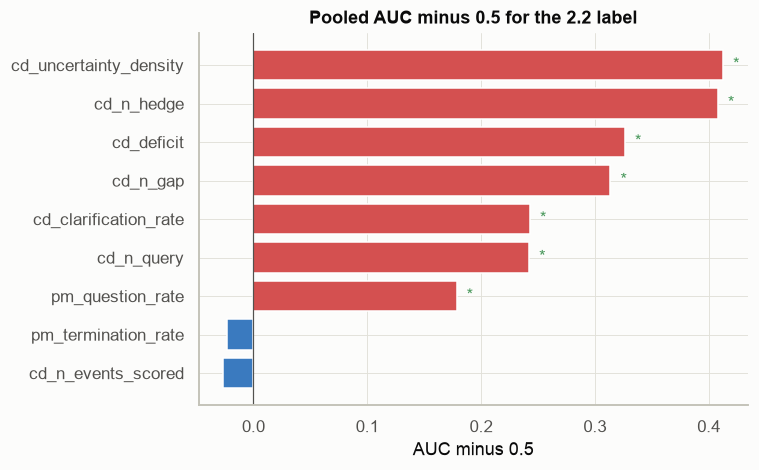

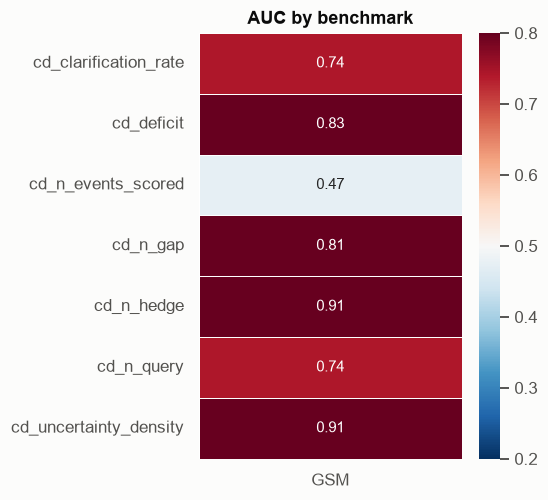

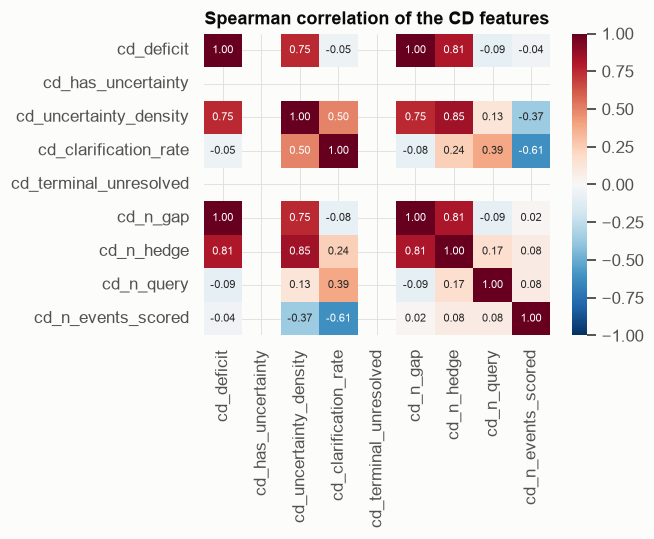

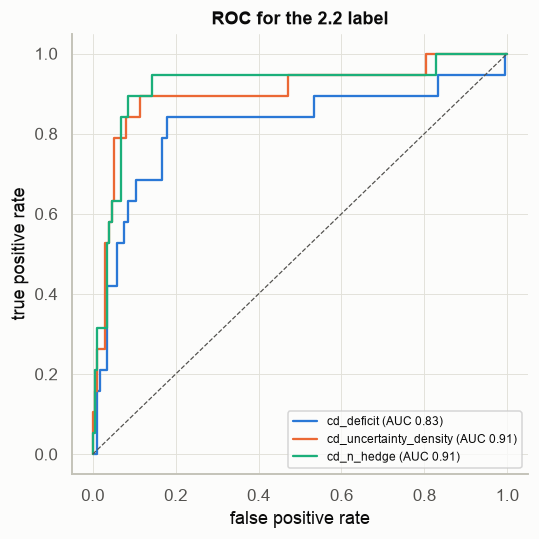

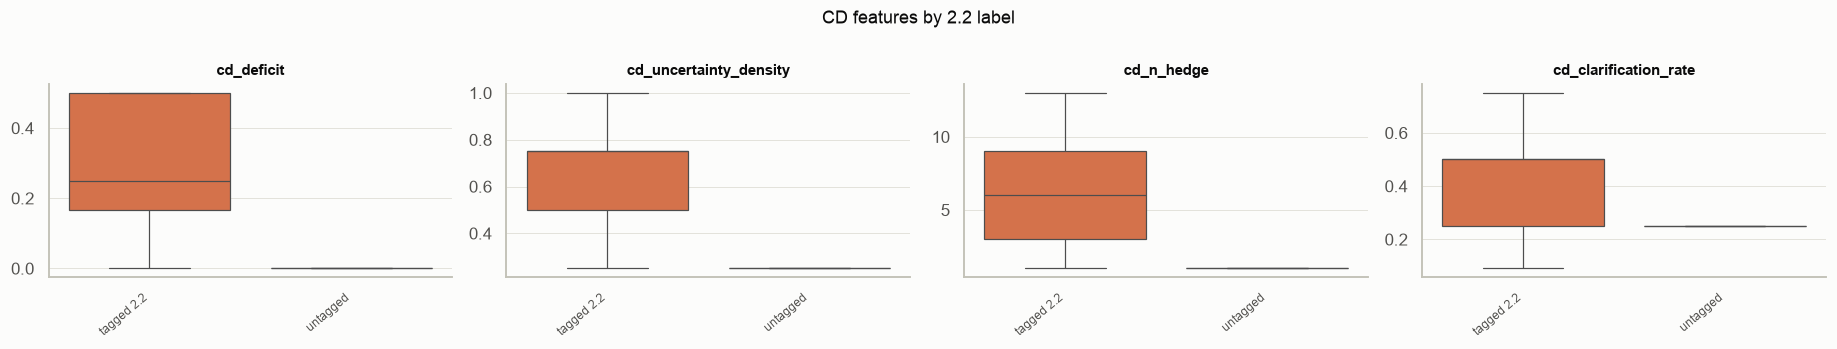

In [24]:
bars = df_pooled.dropna(subset=["AUC"]).assign(delta=lambda d: d["AUC"] - 0.5, sig=lambda d: d["p"] < 0.05)
visualization.diff_bars(bars, "delta", "feature", "Pooled AUC minus 0.5 for the 2.2 label",
                        xlabel="AUC minus 0.5", highlight_col="sig", env=env, name="cd_contrast_bars")
if len(df_strat):
    visualization.contrast_heatmap(df_strat[df_strat["verdict"] != "not testable"], "feature",
                                   "benchmark_name", title="AUC by benchmark", env=env, name="cd_by_benchmark")
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(feature_corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, ax=ax)
ax.set_title("Spearman correlation of the CD features")
fig.tight_layout()
visualization.save_figure(fig, env, "cd_feature_correlation")
visualization.roc_panel(roc, title="ROC for the 2.2 label", env=env, name="cd_roc")
visualization.boxplots_by_group(labelled.assign(label_2_2=labelled[LABEL].map({0: "untagged", 1: "tagged 2.2"})),
                                ["cd_deficit", "cd_uncertainty_density", "cd_n_hedge", "cd_clarification_rate"],
                                by="label_2_2", ncols=4, env=env, name="cd_boxplots",
                                title="CD features by 2.2 label")
plt.show()

### 5.4 Export

The summary table is written as CSV and JSON (`NaN` becomes `null`, so undefined metrics
stay undefined), the notebook's `RESULTS` dictionary as JSON, every extra table as CSV,
and a manifest with library versions, seed and row counts. Everything lands in
`results/<notebook>/`; figures were saved to `results/<notebook>/figures/` as they
were drawn.

In [25]:
exported = aggregation.export_results(env, df_summary, results=RESULTS, extra_tables=EXTRA_TABLES)
pd.Series(exported, name="path").to_frame()

19:54:14 INFO exported 193 rows x 87 columns to /Users/tomheinzelmann/Documents/IBM Praxiseinsätze/Pe4 mit Pa 2/mad_pipeline_refactor/results/analysis_2_2_clarification_AG2_Claude


,path
trace_metrics_csv,/Users/tomheinzelmann/Documents/IBM Praxiseins...
trace_metrics_json,/Users/tomheinzelmann/Documents/IBM Praxiseins...
results_json,/Users/tomheinzelmann/Documents/IBM Praxiseins...
pooled_contrast,/Users/tomheinzelmann/Documents/IBM Praxiseins...
stratified_contrast,/Users/tomheinzelmann/Documents/IBM Praxiseins...
feature_correlation,/Users/tomheinzelmann/Documents/IBM Praxiseins...
manifest,/Users/tomheinzelmann/Documents/IBM Praxiseins...
